# 👥 Previsão de Rotatividade de Funcionários

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** classificação binária (o funcionário sai ou fica?)

> **Resumo:** com a base **IBM HR Analytics** (1.470 funcionários, dados fictícios criados pela IBM), investigamos **o que leva um funcionário a sair** e treinamos um modelo que dá a **probabilidade de saída** de cada pessoa. O RH usa essa probabilidade para decidir **com quem conversar primeiro**. O limiar de decisão é escolhido pelo **custo**: repor um funcionário custa US$ 7.645, e uma ação de retenção custa 1/5 disso. Este notebook une a análise exploratória e o modelo, que na versão original ficavam em dois notebooks.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados (coleta, limpeza, EDA com 13 hipóteses)
- **FASE 03:** Modelagem (5 algoritmos, 4 estratégias de balanceamento, ajuste fino com Grid Search, Random Search e otimização Bayesiana, limiar pelo custo, teste anti-vazamento)
- **FASE 04:** Avaliação (teste, intervalo de confiança, resultado em dólares, curvas ROC e Precision-Recall, variáveis mais importantes com permutação e SHAP)
- **FASE 05:** Implantação (modelo salvo, ficha do modelo, simulação e monitoramento de drift)
- **Respostas**, **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** os dois notebooks originais (EDA e Modelo de Churn) continuam no repositório para mostrar a evolução. Principais correções:
> - a **acurácia de 84%** divulgada na v1 é a mesma de quem **chuta que todo mundo fica** (84,0% no teste); aqui a métrica principal é a da classe **"saiu"**;
> - a v1 **reajustava** o OneHotEncoder e o MinMaxScaler na validação e no teste, e salvou para produção os ajustados **no teste**; aqui tudo fica num `Pipeline` ajustado só no treino;
> - o "Random Forest com 100% em tudo" da v1 foi avaliado em dados que **ele já tinha visto**;
> - a busca de hiperparâmetros otimizava a **acurácia** num treino com **82%** dos funcionários que ficaram descartados (ClusterCentroids);
> - a conta "214 funcionários em risco = US$ 1.636.030" foi substituída por um cálculo de custo com o limiar escolhido na validação.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Perder um funcionário custa caro: além do salário do substituto, há o recrutamento, o tempo até a nova pessoa ocupar a vaga e o treinamento. A versão original citou uma estimativa de **US$ 7.645** por contratação, com cerca de **52 dias** para preencher a vaga (fonte: toggl.com/blog/cost-of-hiring-an-employee).

O RH não consegue conversar com todos os funcionários ao mesmo tempo. Ele precisa saber **com quem falar primeiro**: quem tem mais chance de sair e por quê.

## 🎯 Objetivo

> **Perguntas de negócio:**
> 1. **O que está associado à saída** de um funcionário (hora extra, salário, idade, satisfação, cargo...)?
> 2. Dá para **prever quem vai sair**? Com que precisão, comparado a escolher ao acaso?
> 3. Com quantas pessoas o RH deve **conversar** para que a ação compense o custo?
> 4. Quanto a empresa **economiza** usando o modelo, numa premissa de custo explícita?

**Stakeholder:** gerente de Recursos Humanos.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | 1 linha por **funcionário** |
| **Fonte** | IBM HR Analytics Employee Attrition (Kaggle), base **fictícia** criada por cientistas de dados da IBM |
| **Tipo de problema** | **Classificação binária**: `saiu` = 1 (saiu da empresa) ou 0 (ficou) |
| **Métrica principal** | **PR-AUC** da classe "saiu" (com só 16% de saídas, a acurácia engana); recall, precisão e custo em dólares como apoio |
| **Entrega** | Notebook + README, modelo salvo com ficha, e um **app Streamlit** com o risco de um funcionário e a lista de prioridade do RH |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir as perguntas e a premissa de custo |
| **02. Preparação dos dados** | Traduzir a base, retirar colunas sem informação, checar inconsistências e testar 13 hipóteses |
| **03. Modelagem** | Comparar estratégias de balanceamento e 5 algoritmos, ajustar o melhor e escolher o limiar pelo custo |
| **04. Avaliação** | Medir o resultado no teste, com intervalo de confiança, em dólares e por grupo |
| **05. Implantação** | Salvar o modelo com a ficha, simular funcionários e montar o app |

# FASE 02: PREPARAÇÃO DOS DADOS

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import time

import joblib
import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt

from scipy.stats             import loguniform, randint, uniform
from sklearn.base            import clone
from sklearn.compose         import ColumnTransformer
from sklearn.dummy           import DummyClassifier
from sklearn.ensemble        import RandomForestClassifier
from sklearn.inspection      import permutation_importance
from sklearn.linear_model    import LogisticRegression
from sklearn.metrics         import (average_precision_score, brier_score_loss, classification_report, f1_score,
                                     precision_recall_curve, precision_score, recall_score, ConfusionMatrixDisplay,
                                     PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate,
                                     cross_val_score, RandomizedSearchCV, GridSearchCV)
from sklearn.naive_bayes     import GaussianNB
from sklearn.pipeline        import Pipeline
from sklearn.preprocessing   import OneHotEncoder, StandardScaler
from imblearn.pipeline       import Pipeline as PipelineImb
from imblearn.over_sampling  import SMOTE
from imblearn.under_sampling import ClusterCentroids

import xgboost               as xgb
import lightgbm              as lgb
import optuna
import shap

import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

C:\Users\Rafael\AppData\Local\Temp\nbv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto (também usadas pelo app Streamlit e pelos testes):

| Arquivo | Funções | Para que serve |
|---|---|---|
| `src/config.py` | `SEMENTE`, `FEATURES`, `CUSTO_REPOSICAO`, `PROPORCAO_CUSTO` | Constantes e premissas do projeto num só lugar |
| `src/dados.py` | `carregar_base`, `colunas_sem_informacao` | Lê a base, traduz colunas e valores e acha colunas constantes |
| `src/dados.py` | `criar_variaveis`, `preparar_base`, `funcionario_para_modelo` | Variáveis criadas e preparo de um funcionário novo para o modelo |
| `src/estatistica.py` | `teste_qui_quadrado`, `teste_mann_whitney`, `teste_spearman`, `odds_ratio`, `regra_iqr` | Testes das hipóteses com tamanho do efeito e regra do IQR |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis por Random Forest e Informação Mútua |
| `src/avaliacao.py` | `calcular_metricas_completas`, `relatorio_validacao`, `plot_comparacao_modelos` | Métricas da classe "saiu" e avaliação padronizada de cada algoritmo |
| `src/avaliacao.py` | `limiar_otimo_f1`, `curva_custo`, `resumo_custo`, `ganho_vs_sorteio`, `bootstrap_metricas`, `salvar_ficha_modelo` | Limiar, custo em dólares, ganho sobre o acaso, intervalo de confiança e ficha |
| `src/avaliacao.py` | `explicar_previsao` | As variáveis que mais pesaram na previsão de um funcionário (usada no app) |
| `src/otimizacao.py` | `objetivo_cv`, `resumo_sklearn`, `resumo_optuna`, `historico_optuna` | Comparação entre Grid Search, Random Search e otimização Bayesiana (Optuna) |
| `src/monitoramento.py` | `psi`, `status_psi`, `relatorio_drift` | Monitoramento em produção: mudança na distribuição das variáveis (PSI e teste K-S) |
| `src/graficos.py` | `plot_taxa_saida`, `plot_barras_h`, `pct`, `dolares` | Gráficos e formatação em português |

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.config import (ARQUIVO_BASE, PASTA_MODELO, PASTA_REPORTS, SEMENTE, ALVO, CATEGORICAS, NUMERICAS, TAXAS,
                        FEATURES, FEATURES_ORIGINAIS, FEATURES_CRIADAS, SEM_INFORMACAO, CUSTO_REPOSICAO,
                        PROPORCAO_CUSTO, CUSTO_ABORDAGEM, N_JOBS)
from src.dados import carregar_base, colunas_sem_informacao, criar_variaveis, funcionario_para_modelo
from src.estatistica import teste_qui_quadrado, teste_mann_whitney, teste_spearman, odds_ratio, regra_iqr
from src.selecao import importancia_random_forest, selecao_features
from src.avaliacao import (calcular_metricas_completas, relatorio_validacao, plot_comparacao_modelos, limiar_otimo_f1,
                           curva_custo, resumo_custo, ganho_vs_sorteio, bootstrap_metricas, salvar_ficha_modelo, ROTULOS)
from src.otimizacao import objetivo_cv, resumo_sklearn, resumo_optuna, historico_optuna
from src.monitoramento import relatorio_drift
from src.graficos import (plot_taxa_saida, plot_barras_h, salvar, titulo, pct, dolares,
                          COR_PRINCIPAL, COR_SAIU, COR_FICOU)

### 1.2. Salvar a base em CSV

A base já é um CSV: **`Datasets/Human_Resources.csv`**, a versão do Kaggle da *IBM HR Analytics Employee Attrition & Performance*. Ela é **fictícia**: foi criada por cientistas de dados da IBM para ensino. As conclusões valem para esta base, não para uma empresa real.

In [3]:
print(f'Arquivo: {ARQUIVO_BASE.name} | {ARQUIVO_BASE.stat().st_size / 1024:.0f} KB')

Arquivo: Human_Resources.csv | 223 KB


## 2 - LIMPEZA DOS DADOS

### 2.1. Leitura dos dados

In [4]:
base_original = pd.read_csv(ARQUIVO_BASE, encoding='utf-8-sig')
base_original.head(3)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0


In [5]:
df_bruto = carregar_base(ARQUIVO_BASE)
df_bruto.head(3)

,idade,saiu,viagens,taxa_diaria,departamento,distancia_casa,escolaridade,area_formacao,contagem,id_funcionario,satisfacao_ambiente,genero,taxa_hora,envolvimento,nivel_cargo,cargo,satisfacao_trabalho,estado_civil,salario_mensal,taxa_mensal,empresas_anteriores,maior_18,hora_extra,aumento_salarial_pct,avaliacao_desempenho,satisfacao_relacionamento,horas_padrao,nivel_acoes,anos_experiencia,treinamentos_ano,equilibrio_vida,anos_empresa,anos_cargo_atual,anos_ultima_promocao,anos_gestor_atual
0,41,1,Raramente,1102,Vendas,1,2,Ciências Biológicas,1,1,2,Feminino,94,3,2,Executivo de Vendas,4,Solteiro(a),5993,19479,8,Y,1,11,3,1,80,0,8,0,1,6,4,0,5
1,49,0,Frequentemente,279,Pesquisa e Desenvolvimento,8,1,Ciências Biológicas,1,2,3,Masculino,61,2,2,Cientista Pesquisador,2,Casado(a),5130,24907,1,Y,0,23,4,4,80,1,10,3,3,10,7,1,7
2,37,1,Raramente,1373,Pesquisa e Desenvolvimento,2,2,Outra,1,4,4,Masculino,92,2,1,Técnico de Laboratório,3,Solteiro(a),2090,2396,6,Y,1,15,3,2,80,0,7,3,3,0,0,0,0


#### 📖 Dicionário de dados (após a tradução)

| Coluna | Original | Descrição |
|---|---|---|
| `saiu` | `Attrition` | 🎯 **Alvo**: 1 = saiu da empresa, 0 = ficou |
| `idade`, `genero`, `estado_civil` | `Age`, `Gender`, `MaritalStatus` | Perfil pessoal |
| `departamento`, `cargo`, `nivel_cargo` | `Department`, `JobRole`, `JobLevel` | Posição na empresa (nível de 1 a 5) |
| `salario_mensal`, `aumento_salarial_pct`, `nivel_acoes` | `MonthlyIncome`, `PercentSalaryHike`, `StockOptionLevel` | Remuneração (salário em US$, último aumento em %, ações de 0 a 3) |
| `taxa_diaria`, `taxa_hora`, `taxa_mensal` | `DailyRate`, `HourlyRate`, `MonthlyRate` | "Taxas" sem descrição oficial ⚠️ (ver H12) |
| `hora_extra`, `viagens`, `distancia_casa` | `OverTime`, `BusinessTravel`, `DistanceFromHome` | Rotina de trabalho (distância em milhas) |
| `satisfacao_ambiente`, `satisfacao_trabalho`, `satisfacao_relacionamento`, `equilibrio_vida`, `envolvimento` | `EnvironmentSatisfaction`, `JobSatisfaction`, `RelationshipSatisfaction`, `WorkLifeBalance`, `JobInvolvement` | Pesquisas internas (1 = baixo, 4 = muito alto) |
| `avaliacao_desempenho` | `PerformanceRating` | Avaliação de desempenho (3 ou 4) |
| `escolaridade`, `area_formacao` | `Education`, `EducationField` | Formação (1 = ensino médio a 5 = doutorado) |
| `anos_experiencia`, `anos_empresa`, `anos_cargo_atual`, `anos_ultima_promocao`, `anos_gestor_atual`, `empresas_anteriores`, `treinamentos_ano` | `TotalWorkingYears`, `YearsAtCompany`, ... | Carreira |
| `contagem`, `maior_18`, `horas_padrao`, `id_funcionario` | `EmployeeCount`, `Over18`, `StandardHours`, `EmployeeNumber` | Sem informação (ver item 2.2) |

### 2.2. Colunas

In [6]:
print(df_bruto.columns.to_list())
print('Colunas com um único valor:', {coluna: df_bruto[coluna].iloc[0] for coluna in colunas_sem_informacao(df_bruto)})
print('id_funcionario é único em todas as linhas:', df_bruto['id_funcionario'].is_unique)

['idade', 'saiu', 'viagens', 'taxa_diaria', 'departamento', 'distancia_casa', 'escolaridade', 'area_formacao', 'contagem', 'id_funcionario', 'satisfacao_ambiente', 'genero', 'taxa_hora', 'envolvimento', 'nivel_cargo', 'cargo', 'satisfacao_trabalho', 'estado_civil', 'salario_mensal', 'taxa_mensal', 'empresas_anteriores', 'maior_18', 'hora_extra', 'aumento_salarial_pct', 'avaliacao_desempenho', 'satisfacao_relacionamento', 'horas_padrao', 'nivel_acoes', 'anos_experiencia', 'treinamentos_ano', 'equilibrio_vida', 'anos_empresa', 'anos_cargo_atual', 'anos_ultima_promocao', 'anos_gestor_atual']
Colunas com um único valor: {'contagem': np.int64(1), 'maior_18': 'Y', 'horas_padrao': np.int64(80)}
id_funcionario é único em todas as linhas: True


📌 **Nota**
- 🔎 Três colunas têm **o mesmo valor para todos**: `contagem` (sempre 1), `maior_18` (sempre "Y") e `horas_padrao` (sempre 80). Elas não ajudam a diferenciar ninguém.
- 🔎 `id_funcionario` é **único** em todas as linhas: é só um número de registro.
- ✅ **Decisão:** retirar as 4 colunas (seção 🛡️ abaixo).

### 2.3. Dimensões dos dados

In [7]:
print(f'Linhas (funcionários): {df_bruto.shape[0]:,} | Colunas: {df_bruto.shape[1]}'.replace(',', '.'))
df_bruto.dtypes.value_counts().to_frame('colunas')

Linhas (funcionários): 1.470 | Colunas: 35


,colunas
int64,28
str,7


📌 **Nota**
- 🔎 São **1.470 funcionários** e **35 colunas**: 28 numéricas e 7 de texto. É uma base **pequena**: cada conclusão precisa de cuidado com o acaso.

### 2.4. Valores nulos

In [8]:
print('Valores nulos:', int(df_bruto.isna().sum().sum()))
print('Linhas duplicadas (sem o id):', df_bruto.drop(columns='id_funcionario').duplicated().sum())

Valores nulos: 0
Linhas duplicadas (sem o id): 0


📌 **Nota**
- 🔎 Não há valores nulos nem linhas duplicadas: nenhuma linha precisa ser removida.

### 2.5. Estatística descritiva

In [9]:
df_bruto[['idade', 'salario_mensal', 'distancia_casa', 'anos_experiencia', 'anos_empresa', 'anos_ultima_promocao',
          'empresas_anteriores', 'aumento_salarial_pct']].describe(percentiles=[0.25, 0.5, 0.75]).T

,count,mean,std,min,25%,50%,75%,max
idade,"1,470.000",36.924,9.135,18.000,30.000,36.000,43.000,60.000
salario_mensal,"1,470.000","6,502.931","4,707.957","1,009.000","2,911.000","4,919.000","8,379.000","19,999.000"
distancia_casa,"1,470.000",9.193,8.107,1.000,2.000,7.000,14.000,29.000
anos_experiencia,"1,470.000",11.280,7.781,0.000,6.000,10.000,15.000,40.000
anos_empresa,"1,470.000",7.008,6.127,0.000,3.000,5.000,9.000,40.000
anos_ultima_promocao,"1,470.000",2.188,3.222,0.000,0.000,1.000,3.000,15.000
empresas_anteriores,"1,470.000",2.693,2.498,0.000,1.000,2.000,4.000,9.000
aumento_salarial_pct,"1,470.000",15.210,3.660,11.000,12.000,14.000,18.000,25.000


In [10]:
# Consistência entre colunas de carreira
print('Anos na empresa > anos de experiência:', (df_bruto['anos_empresa'] > df_bruto['anos_experiencia']).sum())
print('Anos no cargo atual > anos na empresa:', (df_bruto['anos_cargo_atual'] > df_bruto['anos_empresa']).sum())
zero_empresas = df_bruto['empresas_anteriores'] == 0
print(f"'0 empresas anteriores': {zero_empresas.sum()} pessoas | delas, com mais anos de experiência que de empresa: "
      f"{(zero_empresas & (df_bruto['anos_experiencia'] > df_bruto['anos_empresa'])).sum()}")
print('Avaliação de desempenho:', df_bruto['avaliacao_desempenho'].value_counts().to_dict())

Anos na empresa > anos de experiência: 0
Anos no cargo atual > anos na empresa: 0
'0 empresas anteriores': 197 pessoas | delas, com mais anos de experiência que de empresa: 197
Avaliação de desempenho: {3: 1244, 4: 226}


📌 **Nota**
- 🔎 O funcionário típico tem **36 anos**, ganha **US$ 4.919** por mês (mediana; a média de US$ 6.503 é puxada pelos cargos altos), está há **5 anos** na empresa e mora a **7 milhas** do trabalho.
- 🔎 As colunas de carreira são coerentes entre si: ninguém tem mais anos de empresa que de experiência, nem mais anos no cargo que na empresa.
- ⚠️ **Inconsistência da base:** as **197** pessoas com "0 empresas anteriores" têm **todas** mais anos de experiência do que de empresa, ou seja, trabalharam em outro lugar antes. Provavelmente o 0 significa "1 empresa anterior" para parte delas. Como não dá para corrigir com segurança, a coluna fica como está.
- 🔎 A avaliação de desempenho só tem **2 valores** (3 e 4: **1.244** e **226** pessoas): ninguém foi mal avaliado, o que limita o uso dessa coluna.

### 2.6. Outliers

In [11]:
# Regra do IQR (abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR)
pd.DataFrame({coluna: regra_iqr(df_bruto[coluna]) for coluna in
              ['salario_mensal', 'anos_experiencia', 'anos_empresa', 'anos_ultima_promocao', 'idade', 'distancia_casa']}).T.round(2)

,limite inferior,limite superior,outliers,% outliers
salario_mensal,"-5,291.000","16,581.000",114.000,0.080
anos_experiencia,-7.500,28.500,63.000,0.040
anos_empresa,-6.000,18.000,104.000,0.070
anos_ultima_promocao,-4.500,7.500,107.000,0.070
idade,10.500,62.500,0.000,0.000
distancia_casa,-16.000,32.000,0.000,0.000


In [12]:
# Os salários "outliers" são de quem?
salario_alto = df_bruto['salario_mensal'] > regra_iqr(df_bruto['salario_mensal'])['limite superior']
display(df_bruto[salario_alto]['nivel_cargo'].value_counts().sort_index().to_frame('pessoas com salário acima do limite'))
df_bruto.groupby('nivel_cargo')['salario_mensal'].median().to_frame('salário mediano (US$)')

,pessoas com salário acima do limite
nivel_cargo,
4,45
5,69


,salário mediano (US$)
nivel_cargo,
1,"2,670.000"
2,"5,340.000"
3,"9,980.000"
4,"16,154.000"
5,"19,232.000"


📌 **Nota**
- 🔎 A regra do IQR marca **114** salários (**8%**), **104** casos de tempo de empresa e **107** de anos sem promoção. Idade e distância não têm outliers.
- 🔎 Os salários acima do limite são **todos** de cargos de nível **4** (**45** pessoas) e **5** (**69**), cujo salário mediano é de **US$ 16.154** e **US$ 19.232**. São diretores e gerentes, não erros.
- ✅ **Decisão:** manter todos. São valores reais e coerentes com o cargo. A Regressão Logística usa as variáveis padronizadas, e as árvores não são sensíveis a valores extremos.

### 2.7. Balanceamento do alvo

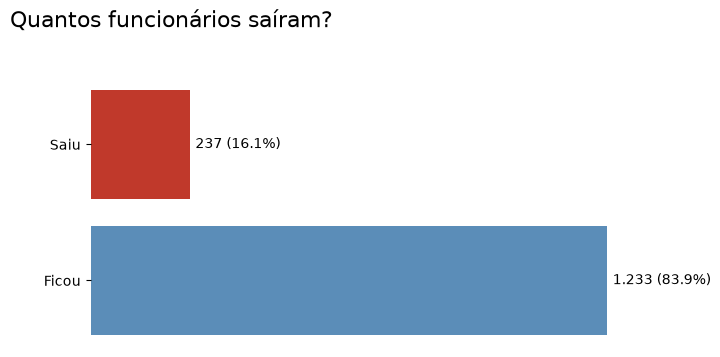

Acurácia de quem chuta "todo mundo fica": 83.9%


In [13]:
contagem = df_bruto[ALVO].value_counts().rename({0: 'Ficou', 1: 'Saiu'})
fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.barh(contagem.index, contagem.values, color=[COR_FICOU, COR_SAIU])
ax.bar_label(barras, labels=[f'{v:,} ({v / contagem.sum():.1%})'.replace(',', '.') for v in contagem.values], padding=4)
ax.set_xticks([])
sns.despine(left=True, bottom=True)
titulo('Quantos funcionários saíram?')
salvar('Distribuicao do alvo')
plt.show()
print(f'Acurácia de quem chuta "todo mundo fica": {1 - df_bruto[ALVO].mean():.1%}')

📌 **Nota**
- 🔎 **237** funcionários saíram (**16,1%**) e **1.233** ficaram (83,9%).
- ⚠️ Quem chuta que **todo mundo fica** acerta **83,9%**. A versão original divulgou uma acurácia de **84%** como resultado do modelo, mas esse é praticamente o acerto do chute.
- ✅ **Decisão:** usar como métrica principal a **PR-AUC** da classe "saiu", com recall, precisão e custo em dólares como apoio. A estratégia de balanceamento é escolhida no item 4.2 da Fase 03.

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

**Vazamento** acontece quando o modelo recebe uma informação que **só existe depois** do que queremos prever, ou que **contém a resposta**. Conferimos cada coluna:

In [14]:
df = criar_variaveis(df_bruto.drop(columns=SEM_INFORMACAO))
removidas = pd.DataFrame({
    'Motivo': ['Constante: 1 em todas as linhas', "Constante: 'Y' em todas as linhas", 'Constante: 80 em todas as linhas',
               'Número de registro (identificador)'],
}, index=SEM_INFORMACAO)
display(removidas)
print(f'Colunas restantes: {df.shape[1]} (com o alvo e as 3 variáveis criadas no item 4)')

,Motivo
contagem,Constante: 1 em todas as linhas
maior_18,Constante: 'Y' em todas as linhas
horas_padrao,Constante: 80 em todas as linhas
id_funcionario,Número de registro (identificador)


Colunas restantes: 34 (com o alvo e as 3 variáveis criadas no item 4)


📌 **Nota**
- 🔎 A base não tem variáveis que só existem **depois** da saída (como data ou motivo do desligamento): nenhuma coluna entrega a resposta.
- 🔎 Saem do modelo as **3 colunas constantes** e o **identificador**.
- ⚠️ Um cuidado de interpretação: a base é uma **fotografia**. Para quem saiu, valores como tempo de empresa e salário são os do momento da saída; para quem ficou, os do momento da coleta. O modelo aprende **associações**, não causas.
- ✅ **Decisão:** seguir com **34 colunas** (alvo + 30 variáveis + 3 criadas). O vazamento da versão original estava na **forma de avaliar**, e o item 9 da Fase 03 mostra isso.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS (EDA)

### 3.1. Criação das Hipóteses

| # | Hipótese | Pergunta |
|---|---|---|
| **H1** | Quem faz **hora extra** sai mais | 1 |
| **H2** | Os **mais jovens** saem mais | 1 |
| **H3** | Quem ganha **menos** sai mais | 1 |
| **H4** | **Solteiros** saem mais | 1 |
| **H5** | Quem **viaja com frequência** sai mais | 1 |
| **H6** | Quem mora **longe** sai mais | 1 |
| **H7** | **Representantes de vendas** saem mais que os outros cargos | 1 |
| **H8** | **Nível de cargo baixo** e **hora extra** juntos multiplicam o risco | 1 |
| **H9** | Quem está **menos satisfeito** sai mais | 1 |
| **H10** | Quem tem **pouco tempo de casa** sai mais | 1 |
| **H11** | Quem **não tem ações** da empresa sai mais | 1 |
| **H12** | As colunas de **"taxa"** (diária, hora, mensal) não têm relação com a saída | 1 |
| **H13** | **Homens e mulheres** saem na mesma proporção | 1 |

Cada hipótese tem um **teste estatístico** e uma medida de **tamanho do efeito**. O que importa é o tamanho do efeito, não o p.

| Teste | Para quê | Tamanho do efeito |
|---|---|---|
| **Qui-quadrado** | Saída × variável de categorias | **V de Cramér** (0,1 = pequeno, 0,3 = médio, 0,5 = grande) e, em 2×2, **odds ratio** (quantas vezes a chance de sair é maior) |
| **Mann-Whitney** | Saída × variável numérica | **Correlação de postos** (−1 a 1; 0,1 = pequeno, 0,3 = médio, 0,5 = grande). Positivo = quem saiu tem valores maiores |

### 3.2. Análises individuais

#### H1: Quem faz hora extra sai mais

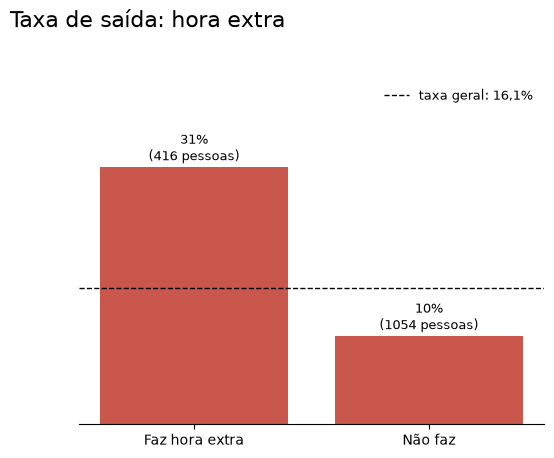

Odds ratio: 3.77


{'teste': 'Qui-quadrado',
 'estatística': np.float64(87.56429365828768),
 'gl': 1,
 'p-valor': np.float64(8.15842372153832e-21),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.24274868721401766}

In [15]:
plot_taxa_saida(df.assign(hora_extra_rotulo=df['hora_extra'].map({1: 'Faz hora extra', 0: 'Não faz'})), 'hora_extra_rotulo',
                'Taxa de saída: hora extra', 'H1 Hora extra')
teste_h1 = teste_qui_quadrado(df['hora_extra'], df[ALVO])
print(f"Odds ratio: {odds_ratio(df['hora_extra'] == 1, df[ALVO]):.2f}")
teste_h1

✅ **Verdadeira, e é o maior efeito individual da base.** Quem faz hora extra tem uma chance de sair **3,77 vezes maior** (odds ratio).

🧪 **Teste estatístico:** qui-quadrado = **87,6**, p < 0,001, V de Cramér = **0,24** (efeito **pequeno a médio**; 0,1 = pequeno, 0,3 = médio). O que importa é o tamanho do efeito, não o p.

#### H2: Os mais jovens saem mais

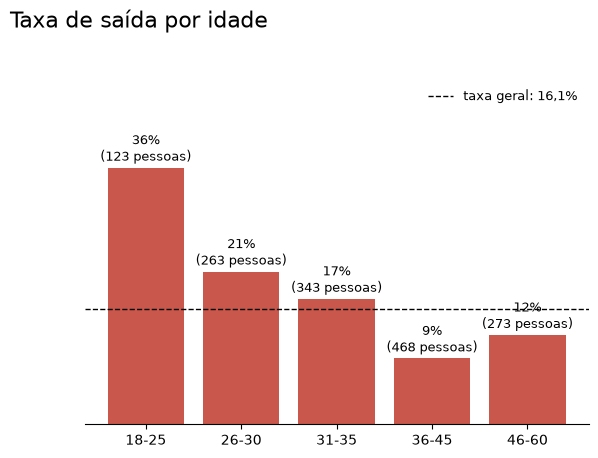

Idade mediana: saiu 32 | ficou 36


{'teste': 'Mann-Whitney',
 'estatística': np.float64(106859.0),
 'p-valor': np.float64(5.304342075341702e-11),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(-0.2686425684670164)}

In [16]:
faixa_idade = pd.cut(df['idade'], [17, 25, 30, 35, 45, 60], labels=['18-25', '26-30', '31-35', '36-45', '46-60'])
plot_taxa_saida(df.assign(faixa_idade=faixa_idade), 'faixa_idade', 'Taxa de saída por idade', 'H2 Idade')
teste_h2 = teste_mann_whitney(df.loc[df[ALVO] == 1, 'idade'], df.loc[df[ALVO] == 0, 'idade'])
print(f"Idade mediana: saiu {df.loc[df[ALVO] == 1, 'idade'].median():.0f} | ficou {df.loc[df[ALVO] == 0, 'idade'].median():.0f}")
teste_h2

✅ **Verdadeira.** Quem saiu tem idade mediana de **32 anos**, contra **36** de quem ficou, e a taxa de saída cai à medida que a idade sobe (gráfico).

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **−0,27** (efeito **pequeno a médio**: quem saiu tende a ser mais jovem), p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H3: Quem ganha menos sai mais

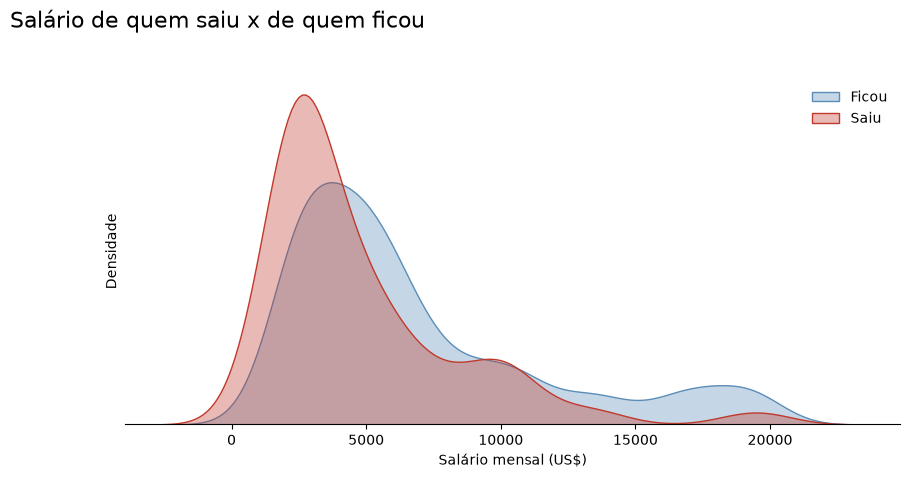

Salário mediano: saiu US$ 3.202 | ficou US$ 5.204


{'teste': 'Mann-Whitney',
 'estatística': np.float64(100620.5),
 'p-valor': np.float64(2.950830917288873e-14),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(-0.3113397052231017)}

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for valor, cor, rotulo in [(0, COR_FICOU, 'Ficou'), (1, COR_SAIU, 'Saiu')]:
    sns.kdeplot(df.loc[df[ALVO] == valor, 'salario_mensal'], fill=True, alpha=0.35, color=cor, label=rotulo, ax=ax, common_norm=False)
ax.set(xlabel='Salário mensal (US$)', ylabel='Densidade', yticks=[])
ax.legend(frameon=False)
sns.despine(left=True)
titulo('Salário de quem saiu x de quem ficou')
salvar('H3 Salario')
plt.show()
teste_h3 = teste_mann_whitney(df.loc[df[ALVO] == 1, 'salario_mensal'], df.loc[df[ALVO] == 0, 'salario_mensal'])
print(f"Salário mediano: saiu {dolares(df.loc[df[ALVO] == 1, 'salario_mensal'].median())} | "
      f"ficou {dolares(df.loc[df[ALVO] == 0, 'salario_mensal'].median())}")
teste_h3

✅ **Verdadeira.** O salário mediano de quem saiu é **US$ 3.202**, contra **US$ 5.204** de quem ficou: **38% menor**. O gráfico mostra que quem saiu se concentra nas faixas abaixo de US$ 5 mil.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **−0,31** (efeito **médio**), p < 0,001. O que importa é o tamanho do efeito, não o p.
- ⚠️ Salário, idade, nível do cargo e tempo de casa andam juntos (item 5): parte desse efeito é de quem está no **começo da carreira**.

#### H4: Solteiros saem mais

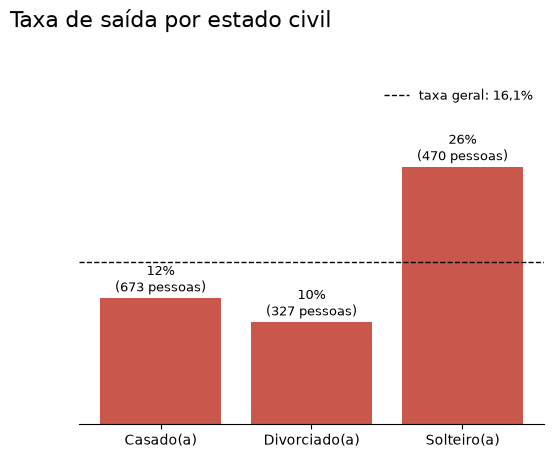

{'teste': 'Qui-quadrado',
 'estatística': np.float64(46.163676540848705),
 'gl': 2,
 'p-valor': np.float64(9.45551106034083e-11),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.17338643559557856}

In [18]:
plot_taxa_saida(df, 'estado_civil', 'Taxa de saída por estado civil', 'H4 Estado civil')
teste_h4 = teste_qui_quadrado(df['estado_civil'], df[ALVO])
teste_h4

✅ **Verdadeira.** Os solteiros saem mais que casados e divorciados (gráfico).

🧪 **Teste estatístico:** qui-quadrado = **46,2**, p < 0,001, V de Cramér = **0,17** (efeito **pequeno**). O que importa é o tamanho do efeito, não o p.

#### H5: Quem viaja com frequência sai mais

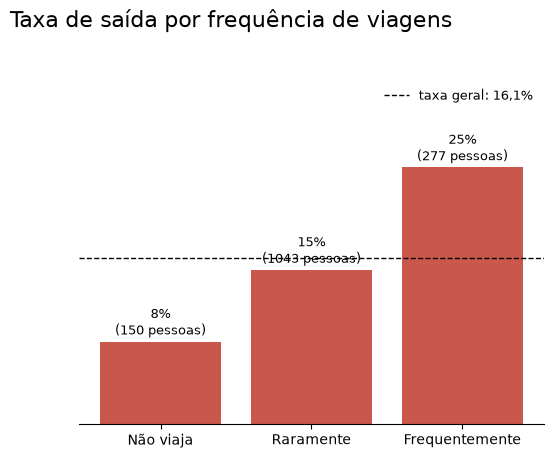

{'teste': 'Qui-quadrado',
 'estatística': np.float64(24.182413685655174),
 'gl': 2,
 'p-valor': np.float64(5.608614476449931e-06),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.12287973746788898}

In [19]:
plot_taxa_saida(df, 'viagens', 'Taxa de saída por frequência de viagens', 'H5 Viagens',
                ordem=['Não viaja', 'Raramente', 'Frequentemente'])
teste_h5 = teste_qui_quadrado(df['viagens'], df[ALVO])
teste_h5

✅ **Verdadeira, com efeito pequeno.** Quem viaja com frequência sai mais que quem viaja raramente, e quem não viaja sai menos (gráfico).

🧪 **Teste estatístico:** qui-quadrado = **24,2**, p < 0,001, V de Cramér = **0,12** (efeito **pequeno**). O que importa é o tamanho do efeito, não o p.

#### H6: Quem mora longe sai mais

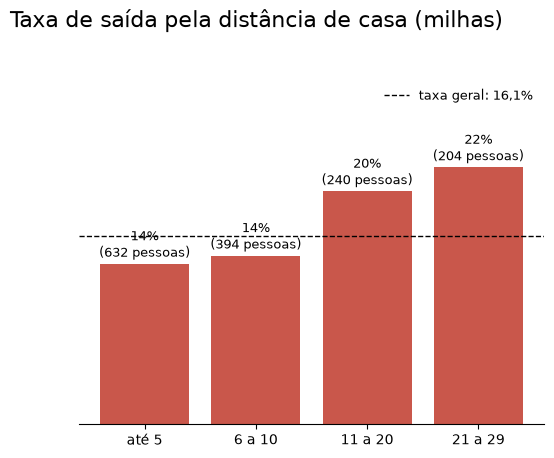

{'teste': 'Mann-Whitney',
 'estatística': np.float64(164225.5),
 'p-valor': np.float64(0.0023870470273627984),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(0.12398150714698808)}

In [20]:
faixa_distancia = pd.cut(df['distancia_casa'], [0, 5, 10, 20, 30], labels=['até 5', '6 a 10', '11 a 20', '21 a 29'])
plot_taxa_saida(df.assign(faixa_distancia=faixa_distancia), 'faixa_distancia', 'Taxa de saída pela distância de casa (milhas)',
                'H6 Distancia')
teste_h6 = teste_mann_whitney(df.loc[df[ALVO] == 1, 'distancia_casa'], df.loc[df[ALVO] == 0, 'distancia_casa'])
teste_h6

⚠️ **Verdadeira, mas com efeito pequeno.** Quem saiu mora um pouco mais longe; a taxa de saída sobe nas faixas acima de 10 milhas (gráfico).

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos = **0,12** (efeito **pequeno**), p = **0,002**. O que importa é o tamanho do efeito, não o p.

### 3.3. Análises combinadas

#### H7: Representantes de vendas saem mais que os outros cargos

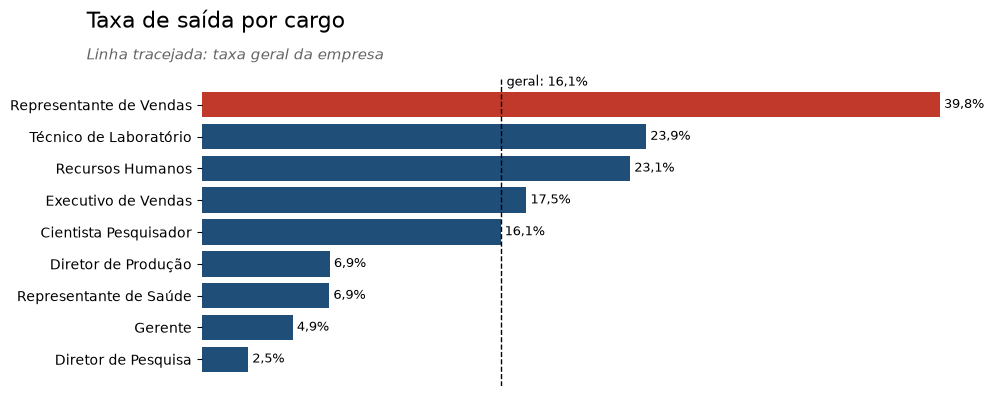

,taxa de saída,pessoas
cargo,,
Representante de Vendas,39.8%,83
Técnico de Laboratório,23.9%,259
Recursos Humanos,23.1%,52
Executivo de Vendas,17.5%,326
Cientista Pesquisador,16.1%,292
Diretor de Produção,6.9%,145
Representante de Saúde,6.9%,131
Gerente,4.9%,102
Diretor de Pesquisa,2.5%,80


Departamento: V de Cramér = 0.077


{'teste': 'Qui-quadrado',
 'estatística': np.float64(86.19025367670434),
 'gl': 8,
 'p-valor': np.float64(2.752481638050657e-15),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.2307014845350407}

In [21]:
taxa_cargo = df.groupby('cargo')[ALVO].agg(['mean', 'size']).sort_values('mean')
plot_barras_h(taxa_cargo['mean'], 'Taxa de saída por cargo', 'H7 Cargo', subtitulo='Linha tracejada: taxa geral da empresa',
              formato=lambda v: pct(v, 1), destaque=['Representante de Vendas'], referencia=df[ALVO].mean())
display(taxa_cargo.rename(columns={'mean': 'taxa de saída', 'size': 'pessoas'}).sort_values('taxa de saída', ascending=False)
        .style.format({'taxa de saída': '{:.1%}'}))
teste_h7 = teste_qui_quadrado(df['cargo'], df[ALVO])
print(f"Departamento: V de Cramér = {teste_qui_quadrado(df['departamento'], df[ALVO])['tamanho do efeito']:.3f}")
teste_h7

✅ **Verdadeira.** Os **representantes de vendas** saem muito mais: **39,8%** (83 pessoas), mais que o dobro da taxa geral. Em seguida vêm os **técnicos de laboratório** (**23,9%**) e o **RH** (**23,1%**). No outro extremo, **diretores de pesquisa** (**2,5%**) e **gerentes** (**4,9%**) quase não saem.
- 🔎 O **departamento** sozinho diz pouco (V de Cramér de **0,08**): o que pesa é o **cargo**. Vendas tem tanto a maior taxa (representantes) quanto cargos estáveis.

🧪 **Teste estatístico:** qui-quadrado = **86,2**, p < 0,001, V de Cramér = **0,23** (efeito **pequeno a médio**). O que importa é o tamanho do efeito, não o p.

#### H8: Nível de cargo baixo e hora extra juntos multiplicam o risco

,taxa de saída (sem hora extra),taxa de saída (com hora extra),pessoas (sem hora extra),pessoas (com hora extra)
nivel_cargo,,,,
1,0.158,0.526,387,156
2,0.067,0.178,388,146
3,0.123,0.206,155,63
4,0.027,0.091,73,33
5,0.039,0.167,51,18


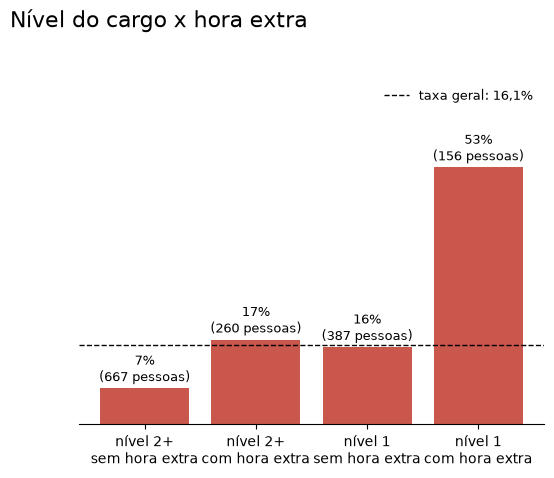

{'teste': 'Qui-quadrado',
 'estatística': np.float64(191.4907037586644),
 'gl': 3,
 'p-valor': np.float64(2.907946302439102e-41),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.35820514380766333}

In [22]:
tabela_h8 = df.groupby(['nivel_cargo', 'hora_extra'])[ALVO].agg(['mean', 'size']).unstack()
tabela_h8.columns = [f"{'taxa de saída' if m == 'mean' else 'pessoas'} ({'com' if h else 'sem'} hora extra)" for m, h in tabela_h8.columns]
display(tabela_h8.round(3))

combinacao = (df['nivel_cargo'] == 1).map({True: 'nível 1', False: 'nível 2+'}) + chr(10) + \
             df['hora_extra'].map({1: 'com hora extra', 0: 'sem hora extra'})
ordem_h8 = [f'{nivel}{chr(10)}{hora}' for nivel in ['nível 2+', 'nível 1'] for hora in ['sem hora extra', 'com hora extra']]
plot_taxa_saida(df.assign(combinacao=combinacao), 'combinacao', 'Nível do cargo x hora extra', 'H8 Nivel x hora extra',
                ordem=ordem_h8)
teste_h8 = teste_qui_quadrado(combinacao, df[ALVO])
teste_h8

✅ **Verdadeira: é a combinação mais forte da base.** No **nível 1** com **hora extra**, a taxa de saída chega a **52,6%** (156 pessoas): mais da metade sai. No nível 1 sem hora extra, é **15,8%**; nos níveis 2 a 5, a hora extra também aumenta a saída em todos os níveis (de **6,7%** para **17,8%** no nível 2, por exemplo).

🧪 **Teste estatístico:** qui-quadrado = **191,5**, p < 0,001, V de Cramér = **0,36** (efeito **médio**, o maior das 13 hipóteses). O que importa é o tamanho do efeito, não o p.
- 💡 **Para o RH:** funcionários júniores fazendo hora extra são o grupo de maior risco. É também o grupo em que uma ação concreta (rever a carga de trabalho) é mais clara.

#### H9: Quem está menos satisfeito sai mais

,teste,p-valor,efeito,tamanho do efeito
satisfacao_ambiente,Mann-Whitney,0.000,correlação de postos,-0.146
satisfacao_trabalho,Mann-Whitney,0.000,correlação de postos,-0.156
satisfacao_relacionamento,Mann-Whitney,0.102,correlação de postos,-0.065
equilibrio_vida,Mann-Whitney,0.046,correlação de postos,-0.071
envolvimento,Mann-Whitney,0.000,correlação de postos,-0.165
satisfacao_media,Mann-Whitney,0.000,correlação de postos,-0.229


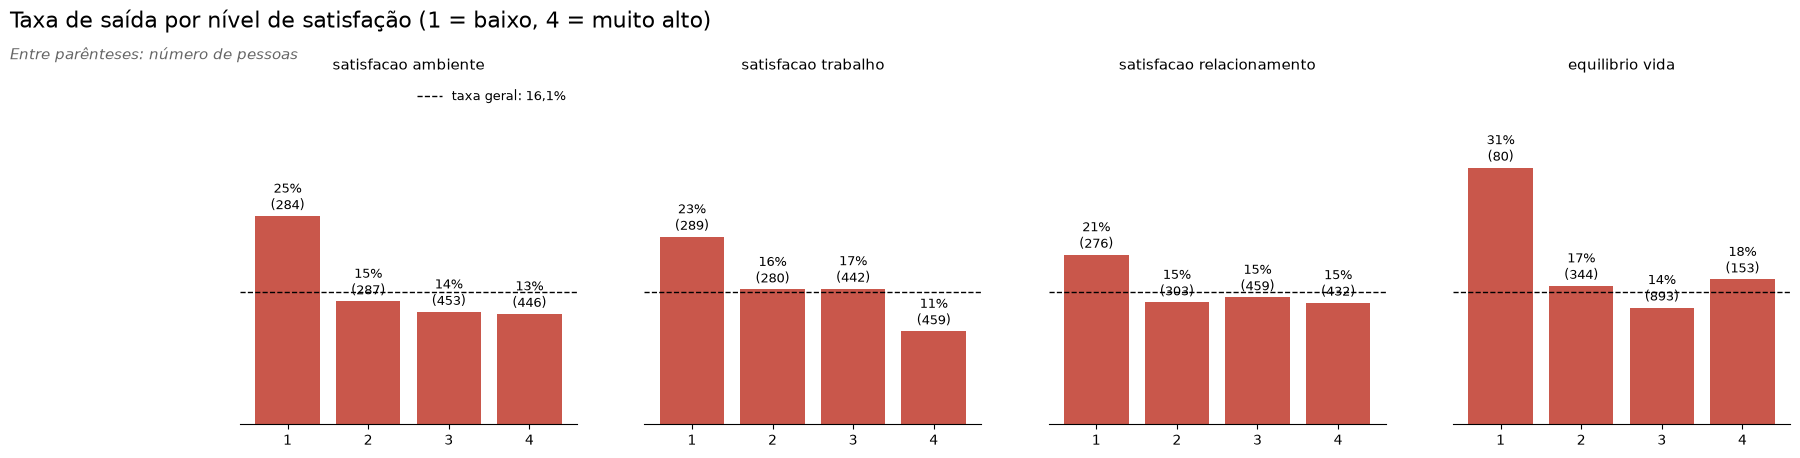

In [23]:
satisfacoes = ['satisfacao_ambiente', 'satisfacao_trabalho', 'satisfacao_relacionamento', 'equilibrio_vida', 'envolvimento',
               'satisfacao_media']
teste_h9 = pd.DataFrame({coluna: teste_mann_whitney(df.loc[df[ALVO] == 1, coluna], df.loc[df[ALVO] == 0, coluna])
                         for coluna in satisfacoes}).T
display(teste_h9[['teste', 'p-valor', 'efeito', 'tamanho do efeito']])

fig, axs = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for i, (ax, coluna) in enumerate(zip(axs, satisfacoes[:4])):
    plot_taxa_saida(df, coluna, '', '', ax=ax, legenda=(i == 0))
    ax.set_title(coluna.replace('_', ' '), fontsize=11)
titulo('Taxa de saída por nível de satisfação (1 = baixo, 4 = muito alto)', 'Entre parênteses: número de pessoas')
salvar('H9 Satisfacao')
plt.show()

⚠️ **Parcial: cada satisfação sozinha tem efeito pequeno.** Satisfação com o ambiente (**−0,15**), com o trabalho (**−0,16**) e envolvimento (**−0,17**) têm efeito pequeno; satisfação com o relacionamento (**−0,07**, p = 0,10) e equilíbrio vida-trabalho (**−0,07**) quase não diferem.
- 🔎 A **média** das 4 satisfações tem efeito maior (**−0,23**) que qualquer uma sozinha: o clima geral diz mais que cada pergunta.
- 🔎 Nos gráficos, o nível **1** (satisfação baixa) é o que mais se destaca, sempre acima da taxa geral.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos de **−0,07** a **−0,23** (efeitos **pequenos**). O que importa é o tamanho do efeito, não o p.

#### H10: Quem tem pouco tempo de casa sai mais

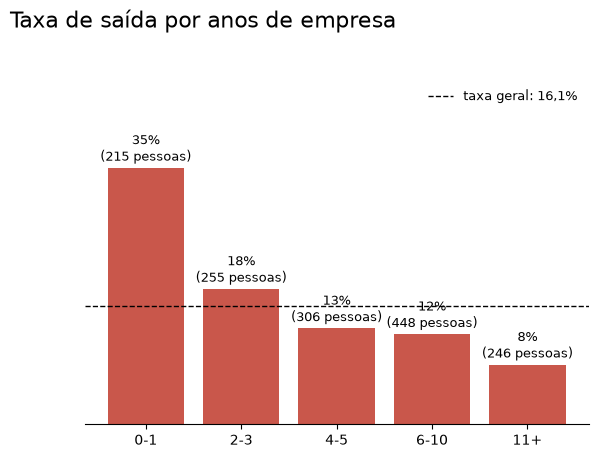

,teste,p-valor,efeito,tamanho do efeito
anos_empresa,Mann-Whitney,0.000,correlação de postos,-0.298
anos_experiencia,Mann-Whitney,0.000,correlação de postos,-0.312
anos_cargo_atual,Mann-Whitney,0.000,correlação de postos,-0.280
anos_gestor_atual,Mann-Whitney,0.000,correlação de postos,-0.272
anos_ultima_promocao,Mann-Whitney,0.041,correlação de postos,-0.080


In [24]:
faixa_casa = pd.cut(df['anos_empresa'], [-1, 1, 3, 5, 10, 40], labels=['0-1', '2-3', '4-5', '6-10', '11+'])
plot_taxa_saida(df.assign(faixa_casa=faixa_casa), 'faixa_casa', 'Taxa de saída por anos de empresa', 'H10 Tempo de casa')
teste_h10 = pd.DataFrame({coluna: teste_mann_whitney(df.loc[df[ALVO] == 1, coluna], df.loc[df[ALVO] == 0, coluna])
                          for coluna in ['anos_empresa', 'anos_experiencia', 'anos_cargo_atual', 'anos_gestor_atual',
                                         'anos_ultima_promocao']}).T
teste_h10[['teste', 'p-valor', 'efeito', 'tamanho do efeito']]

✅ **Verdadeira.** A taxa de saída é maior nos **primeiros anos** de empresa e cai com o tempo (gráfico). Quem saiu tem menos anos de empresa (**−0,30**), de experiência (**−0,31**), no cargo atual (**−0,28**) e com o mesmo gestor (**−0,27**).
- 🔎 O tempo desde a **última promoção** quase não difere (**−0,08**): ficar muito tempo sem promoção, sozinho, não explica a saída.

🧪 **Teste estatístico:** Mann-Whitney, correlação de postos de **−0,27** a **−0,31** (efeitos **médios**), p < 0,001. O que importa é o tamanho do efeito, não o p.

#### H11: Quem não tem ações da empresa sai mais

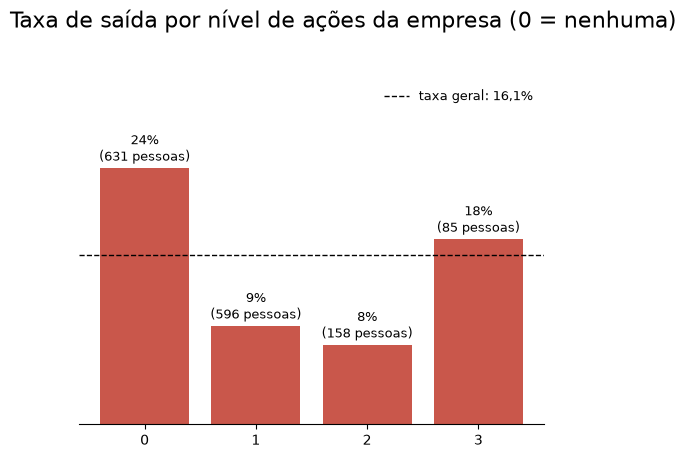

Odds ratio (sem ações x com ações): 2.94
Estado civil x ações (% sem ações): {'Casado(a)': 0.227, 'Divorciado(a)': 0.024, 'Solteiro(a)': 1.0}


{'teste': 'Qui-quadrado',
 'estatística': np.float64(60.59830108612225),
 'gl': 3,
 'p-valor': np.float64(4.379390336108354e-13),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.19800964277576658}

In [25]:
plot_taxa_saida(df, 'nivel_acoes', 'Taxa de saída por nível de ações da empresa (0 = nenhuma)', 'H11 Acoes')
teste_h11 = teste_qui_quadrado(df['nivel_acoes'], df[ALVO])
print(f"Odds ratio (sem ações x com ações): {odds_ratio(df['nivel_acoes'] == 0, df[ALVO]):.2f}")
print('Estado civil x ações (% sem ações):', (df.groupby('estado_civil')['nivel_acoes'].apply(lambda s: (s == 0).mean())
                                              .round(3).to_dict()))
teste_h11

✅ **Verdadeira, mas confundida com o estado civil.** Quem não tem ações sai com uma chance **2,94 vezes maior** (odds ratio).
- ⚠️ Na base, **100%** dos solteiros estão no nível 0 de ações, contra **22,7%** dos casados e **2,4%** dos divorciados. Ações e estado civil contam quase a mesma história, e não dá para separar uma da outra só com estes dados.

🧪 **Teste estatístico:** qui-quadrado = **60,6**, p < 0,001, V de Cramér = **0,20** (efeito **pequeno**). O que importa é o tamanho do efeito, não o p.

#### H12: As colunas de "taxa" não têm relação com a saída

In [26]:
teste_h12 = pd.DataFrame({coluna: teste_mann_whitney(df.loc[df[ALVO] == 1, coluna], df.loc[df[ALVO] == 0, coluna])
                          for coluna in TAXAS + ['salario_mensal']}).T
teste_h12['correlação com o salário (Spearman)'] = [teste_spearman(df[coluna], df['salario_mensal'])['estatística']
                                                     for coluna in teste_h12.index]
teste_h12[['p-valor', 'tamanho do efeito', 'correlação com o salário (Spearman)']]

,p-valor,tamanho do efeito,correlação com o salário (Spearman)
taxa_diaria,0.029,-0.089,0.016
taxa_hora,0.798,-0.011,-0.020
taxa_mensal,0.559,0.024,0.054
salario_mensal,0.000,-0.311,1.000


✅ **Verdadeira: as "taxas" são ruído.** Nenhuma delas se relaciona com o salário real (correlações de **0,02**, **−0,02** e **0,05**), e a diferença entre quem saiu e quem ficou é desprezível (efeitos de **−0,09**, **−0,01** e **0,02**; p = **0,80** e **0,56** para as taxas por hora e mensal).
- ⚠️ A versão original descrevia `DailyRate` como "cálculo do salário". Numa base real, uma coluna com esse nome teria que se relacionar com o salário mensal (**−0,31** de efeito na saída). Aqui, ela parece um número aleatório da base sintética.
- ✅ **Decisão:** as 3 taxas ficam fora do modelo final. A confirmação do item 4.3 da Fase 03 mede o efeito dessa escolha.

🧪 **Teste estatístico:** Mann-Whitney + correlação de Spearman com o salário. O que importa é o tamanho do efeito, não o p.

#### H13: Homens e mulheres saem na mesma proporção

In [27]:
display(df.groupby('genero')[ALVO].agg(['mean', 'size']).rename(columns={'mean': 'taxa de saída', 'size': 'pessoas'})
        .style.format({'taxa de saída': '{:.1%}'}))
teste_h13 = teste_qui_quadrado(df['genero'], df[ALVO])
teste_h13

,taxa de saída,pessoas
genero,,
Feminino,14.8%,588
Masculino,17.0%,882


{'teste': 'Qui-quadrado',
 'estatística': np.float64(1.1169671241970975),
 'gl': 1,
 'p-valor': np.float64(0.29057244902890855),
 'efeito': 'V de Cramér',
 'tamanho do efeito': 0.008897205980620429}

✅ **Verdadeira.** A taxa de saída é de **14,8%** entre as mulheres e **17,0%** entre os homens: diferença pequena e compatível com o acaso.

🧪 **Teste estatístico:** qui-quadrado = **1,1**, p = **0,29**, V de Cramér = **0,01** (efeito **nulo**). O que importa é o tamanho do efeito, não o p.
- ⚖️ Mesmo assim, o gênero ficou **fora do modelo** (item 4.3 da Fase 03): é um atributo sensível, e o modelo não deve usá-lo para decidir com quem o RH conversa.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência | Tamanho do efeito |
|---|---|---|---|---|
| **H1** | Hora extra → sai mais | ✅ Verdadeira | Chance **3,77x** maior | V **0,24** |
| **H2** | Mais jovens saem mais | ✅ Verdadeira | Mediana de **32** contra **36** anos | r **−0,27** |
| **H3** | Quem ganha menos sai mais | ✅ Verdadeira | **US$ 3.202** contra **US$ 5.204** | r **−0,31** (médio) |
| **H4** | Solteiros saem mais | ✅ Verdadeira | — | V **0,17** |
| **H5** | Quem viaja muito sai mais | ✅ Efeito pequeno | — | V **0,12** |
| **H6** | Quem mora longe sai mais | ⚠️ Efeito pequeno | p = 0,002 | r **0,12** |
| **H7** | Representantes de vendas saem mais | ✅ Verdadeira | **39,8%** contra 2,5% dos diretores de pesquisa | V **0,23** |
| **H8** | Nível 1 + hora extra multiplicam o risco | ✅ **Maior efeito** | **52,6%** de saída no grupo | V **0,36** (médio) |
| **H9** | Menos satisfeito → sai mais | ⚠️ Parcial | A média das satisfações pesa mais que cada uma | r de **−0,07** a **−0,23** |
| **H10** | Pouco tempo de casa → sai mais | ✅ Verdadeira | Anos sem promoção quase não diferem | r de **−0,27** a **−0,31** |
| **H11** | Sem ações → sai mais | ✅ Confundida com estado civil | Chance **2,94x** maior; **100%** dos solteiros sem ações | V **0,20** |
| **H12** | As "taxas" são ruído | ✅ Verdadeira | Correlação com o salário ~**0** | r de **−0,09** a **0,02** |
| **H13** | Homens e mulheres saem igual | ✅ Verdadeira | **14,8%** contra **17,0%** (p = 0,29) | V **0,01** (nulo) |

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Como foi criada | Por quê |
|---|---|---|
| `satisfacao_media` | média das 4 satisfações (ambiente, trabalho, relacionamento, equilíbrio) | Cada pesquisa sozinha tem efeito pequeno (H9); a média resume o clima geral |
| `anos_por_empresa` | anos de experiência ÷ (empresas anteriores + 1) | Mede a **estabilidade** na carreira: quem troca muito de emprego |
| `fracao_carreira_na_empresa` | anos na empresa ÷ anos de experiência | 1 = fez a carreira toda aqui; perto de 0 = acabou de chegar vindo de fora |
| `hora_extra` | Sim/Não → 1/0 | Modelos só trabalham com números |
| Colunas de texto | one-hot dentro do `Pipeline` (Fase 03, item 3) | Cada categoria vira uma coluna 0/1 |
| `genero` | **fica fora do modelo** | Atributo sensível: analisado na H13 e na conferência por grupo da Fase 04, mas não usado para prever (item 4.3 da Fase 03) |

> ⚠️ Nenhuma variável criada usa o alvo. As colunas de "taxa" (H12) ficam de fora do modelo final; a confirmação do item 4.3 da Fase 03 mede o efeito dessa escolha.

In [28]:
df[FEATURES_CRIADAS + [ALVO]].groupby(ALVO).median().rename(index={0: 'Ficou (mediana)', 1: 'Saiu (mediana)'}).round(2)

,satisfacao_media,anos_por_empresa,fracao_carreira_na_empresa
saiu,,,
Ficou (mediana),2.750,3.330,0.800
Saiu (mediana),2.500,1.620,0.800


📌 **Nota**
- 🔎 Quem saiu tem **metade** dos anos por empresa (mediana de **1,62**, contra **3,33**): troca de emprego com mais frequência.
- 🔎 A satisfação média de quem saiu é um pouco menor (**2,50** contra **2,75**).
- 🔎 A fração da carreira feita na empresa tem a **mesma mediana** nos dois grupos (**0,80**): sozinha, ela não separa quem sai. A confirmação do item 4.3 da Fase 03 mostra se ela ajuda junto com as outras.

## 5 - EXPLORANDO AS CORRELAÇÕES

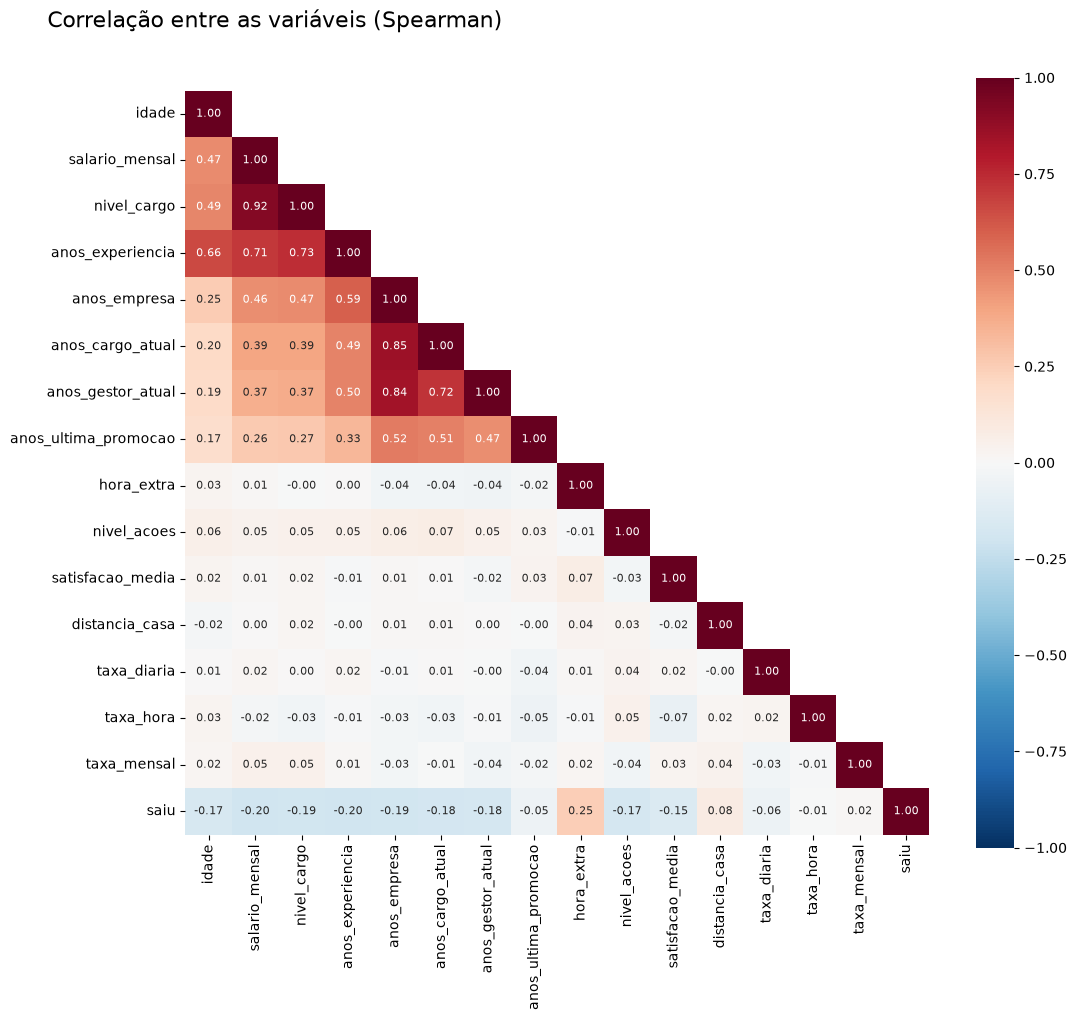

,anos_experiencia,salario_mensal,anos_empresa,nivel_cargo,anos_cargo_atual,anos_gestor_atual,nivel_acoes,idade,satisfacao_media,taxa_diaria,anos_ultima_promocao,taxa_hora,taxa_mensal,distancia_casa,hora_extra
correlação com a saída,-0.200,-0.200,-0.190,-0.190,-0.180,-0.180,-0.170,-0.170,-0.150,-0.060,-0.050,-0.010,0.020,0.080,0.250


In [29]:
colunas_corr = ['idade', 'salario_mensal', 'nivel_cargo', 'anos_experiencia', 'anos_empresa', 'anos_cargo_atual',
                'anos_gestor_atual', 'anos_ultima_promocao', 'hora_extra', 'nivel_acoes', 'satisfacao_media',
                'distancia_casa', 'taxa_diaria', 'taxa_hora', 'taxa_mensal', ALVO]
correlacao = df[colunas_corr].corr(method='spearman')
plt.figure(figsize=(12, 10))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            mask=np.triu(np.ones_like(correlacao, dtype=bool), k=1), annot_kws={'size': 8})
titulo('Correlação entre as variáveis (Spearman)')
salvar('Correlacao entre variaveis')
plt.show()
correlacao[ALVO].drop(ALVO).sort_values().round(2).to_frame('correlação com a saída').T

📌 **Nota**
- 🔎 Nenhuma variável sozinha tem correlação forte com a saída. A maior é a **hora extra** (**0,25**); em seguida, com sinal negativo, vêm anos de experiência e salário (**−0,20**), anos de empresa e nível do cargo (**−0,19**), e ações e idade (**−0,17**).
- 🔎 As três **taxas** ficam perto de zero (**−0,06**, **−0,01** e **0,02**), confirmando a H12.
- ⚠️ Salário, nível do cargo, idade e anos de experiência/empresa são **muito correlacionados entre si** (todos medem o estágio da carreira). O modelo da Fase 03 separa o efeito de cada um.

# FASE 03: MODELAGEM DOS DADOS

**Pergunta 2:** *dá para prever quem vai sair?*

O modelo devolve uma **probabilidade de saída**. A decisão de chamar a pessoa para uma conversa vem do **limiar**, escolhido no item 8 pelo custo.

## 1 - Leitura dos dados

In [30]:
X = df[FEATURES_ORIGINAIS + FEATURES_CRIADAS]   # as taxas ficam disponíveis só para a confirmação do item 4.3
y = df[ALVO]
print(f'Funcionários: {len(X):,} | Saídas: {y.sum()} ({y.mean():.1%}) | Variáveis do modelo final: {len(FEATURES)}'.replace(',', '.'))

Funcionários: 1.470 | Saídas: 237 (16.1%) | Variáveis do modelo final: 29


## 2 - Valores nulos

In [31]:
print('Valores nulos nas variáveis:', int(X.isna().sum().sum()))

Valores nulos nas variáveis: 0


📌 **Nota**
- 🔎 Nenhuma variável tem valor vazio: não é preciso preencher nada.

## 3 - Transformação

| Variável | Transformação | Motivo |
|---|---|---|
| Colunas de texto (cargo, departamento, estado civil, viagens, formação, gênero) | **One-hot** | Cada categoria vira uma coluna 0/1 |
| Numéricas | **Padronização** (média 0, desvio 1), só na Regressão Logística e no Naive Bayes | Coloca idade, salário e anos na mesma escala. As árvores não precisam |

Tudo fica **dentro de um `Pipeline`**: as transformações são aprendidas **só com o treino** e aplicadas igual na validação, no teste e no app. A versão original reajustava o encoder e o scaler em cada conjunto.

In [32]:
def preprocessador(colunas, escalar=True):
    # One-hot das categorias e, opcionalmente, padronização das numéricas (aprendidos só no treino)
    categoricas = [coluna for coluna in colunas if coluna in CATEGORICAS]
    numericas = [coluna for coluna in colunas if coluna not in CATEGORICAS]
    return ColumnTransformer([
        ('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
        ('numericas', StandardScaler() if escalar else 'passthrough', numericas),
    ], verbose_feature_names_out=False)

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

| Conjunto | Tamanho | Para que serve | Comparação |
|---|---|---|---|
| **Treino** | 60% | o modelo **aprende** os padrões | estudar a matéria |
| **Validação** | 20% | **comparar** algoritmos e **escolher o limiar** | fazer simulados |
| **Teste** | 20% | **avaliação final**, usada uma única vez no fim | a prova de verdade |

As duas divisões são **estratificadas** pelo alvo: cada parte tem os mesmos ~16% de saídas. Na versão original, a validação não era estratificada.

In [33]:
X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE, stratify=y)
X_treino, X_validacao, y_treino, y_validacao = train_test_split(X_treino_val, y_treino_val, test_size=0.25,
                                                                random_state=SEMENTE, stratify=y_treino_val)
partes = {'Total': (X, y), 'Treino': (X_treino, y_treino), 'Validação': (X_validacao, y_validacao), 'Teste': (X_teste, y_teste)}
pd.DataFrame({'Funcionários': {n: len(a) for n, (a, b) in partes.items()}, 'Shape de X': {n: a.shape for n, (a, b) in partes.items()},
              '% da base': {n: len(a) / len(X) for n, (a, b) in partes.items()}, 'Saídas': {n: int(b.sum()) for n, (a, b) in partes.items()},
              '% de saídas': {n: b.mean() for n, (a, b) in partes.items()}}).style.format({'% da base': '{:.0%}', '% de saídas': '{:.1%}'})

,Funcionários,Shape de X,% da base,Saídas,% de saídas
Total,1470,"(1470, 33)",100%,237,16.1%
Treino,882,"(882, 33)",60%,143,16.2%
Validação,294,"(294, 33)",20%,47,16.0%
Teste,294,"(294, 33)",20%,47,16.0%


📌 **Nota**
- 🔎 **Treino: 882 funcionários (60%)**, com **143** saídas; **validação: 294 (20%)**, com **47**; **teste: 294 (20%)**, com **47**, guardados até o fim.
- 🔎 A estratificação manteve a taxa de saída igual nas três partes (**16,0%** a **16,2%**).
- ⚠️ Com só **47** saídas na validação e no teste, cada pessoa vale ~2 pontos de recall. Por isso a escolha do modelo usa a **validação cruzada** e o teste ganha um **intervalo de confiança** (Fase 04).

### 4.2. Balancear

Com 16% de saídas, um modelo pode "aprender" que prever sempre "fica" já acerta 84%. Comparamos 4 estratégias, sempre **só no treino**, pela **PR-AUC** em validação cruzada estratificada (5 dobras × 3 repetições do treino):

| Estratégia | Como funciona |
|---|---|
| **Sem balanceamento** | Treina com as proporções reais |
| **Peso da classe** | Cada saída "pesa" ~5 vezes mais no treino; nenhum dado é criado ou descartado |
| **SMOTE** | Cria saídas sintéticas, interpolando entre saídas vizinhas, até as classes empatarem |
| **ClusterCentroids** (v1) | **Descarta** funcionários que ficaram, até as classes empatarem |

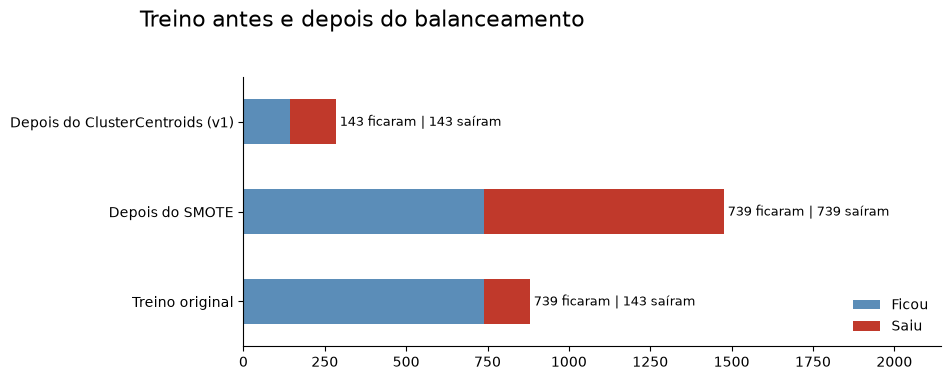

PR-AUC em validação cruzada do treino (sorteio = 0.162):


,ClusterCentroids (v1),Peso da classe,SMOTE,Sem balanceamento
Regressão Logística,0.590 ± 0.081,0.597 ± 0.079,0.597 ± 0.078,0.638 ± 0.066
XGBoost,0.385 ± 0.040,0.560 ± 0.067,0.590 ± 0.066,0.578 ± 0.063


In [34]:
proporcao = (y_treino == 0).sum() / y_treino.sum()   # quantos ficaram para cada um que saiu
amostra_cc = ClusterCentroids(random_state=SEMENTE).fit_resample(preprocessador(FEATURES).fit_transform(X_treino[FEATURES]), y_treino)[1]
amostra_smote = SMOTE(random_state=SEMENTE).fit_resample(preprocessador(FEATURES).fit_transform(X_treino[FEATURES]), y_treino)[1]
fig, ax = plt.subplots(figsize=(9, 3.5))
contagens = pd.DataFrame({'Treino original': y_treino.value_counts(), 'Depois do SMOTE': amostra_smote.value_counts(),
                          'Depois do ClusterCentroids (v1)': amostra_cc.value_counts()}).T.rename(columns={0: 'Ficou', 1: 'Saiu'})
contagens.plot.barh(stacked=True, color=[COR_FICOU, COR_SAIU], ax=ax)
for i, (_, linha) in enumerate(contagens.iterrows()):
    ax.text(linha.sum() + 10, i, f"{int(linha['Ficou'])} ficaram | {int(linha['Saiu'])} saíram", va='center', fontsize=9)
ax.set_xlim(0, contagens.sum(axis=1).max() * 1.45)
ax.legend(frameon=False, loc='lower right')
sns.despine()
titulo('Treino antes e depois do balanceamento')
salvar('Treino antes e depois do balanceamento')
plt.show()

cv_repetida = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMENTE)
estrategias = {
    'Regressão Logística': {
        'Sem balanceamento': Pipeline([('prep', preprocessador(FEATURES)), ('modelo', LogisticRegression(max_iter=3000))]),
        'Peso da classe': Pipeline([('prep', preprocessador(FEATURES)), ('modelo', LogisticRegression(max_iter=3000, class_weight='balanced'))]),
        'SMOTE': PipelineImb([('prep', preprocessador(FEATURES)), ('smote', SMOTE(random_state=SEMENTE)), ('modelo', LogisticRegression(max_iter=3000))]),
        'ClusterCentroids (v1)': PipelineImb([('prep', preprocessador(FEATURES)), ('cc', ClusterCentroids(random_state=SEMENTE)),
                                              ('modelo', LogisticRegression(max_iter=3000))])},
    'XGBoost': {
        'Sem balanceamento': Pipeline([('prep', preprocessador(FEATURES, escalar=False)), ('modelo', xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS))]),
        'Peso da classe': Pipeline([('prep', preprocessador(FEATURES, escalar=False)), ('modelo', xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS, scale_pos_weight=proporcao))]),
        'SMOTE': PipelineImb([('prep', preprocessador(FEATURES, escalar=False)), ('smote', SMOTE(random_state=SEMENTE)), ('modelo', xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS))]),
        'ClusterCentroids (v1)': PipelineImb([('prep', preprocessador(FEATURES, escalar=False)), ('cc', ClusterCentroids(random_state=SEMENTE)),
                                              ('modelo', xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS))])},
}
comparacao_balanceamento = {}
for algoritmo, opcoes in estrategias.items():
    for estrategia, modelo in opcoes.items():
        notas = cross_val_score(modelo, X_treino[FEATURES], y_treino, cv=cv_repetida, scoring='average_precision')
        comparacao_balanceamento[(algoritmo, estrategia)] = f'{notas.mean():.3f} ± {notas.std():.3f}'
print(f'PR-AUC em validação cruzada do treino (sorteio = {y_treino.mean():.3f}):')
pd.Series(comparacao_balanceamento).unstack()

📌 **Nota**
- 🔎 Na **Regressão Logística**, treinar **sem balanceamento** dá a maior PR-AUC (**0,638 ± 0,066**), contra **0,597** com peso da classe, **0,597** com SMOTE e **0,590** com o ClusterCentroids da v1.
- 🔎 No **XGBoost**, as três primeiras opções empatam dentro do desvio (de **0,560** a **0,590**), e o **ClusterCentroids** despenca para **0,385**: jogar fora 82% dos funcionários que ficaram faz o modelo perder informação.
- 🔎 Numa primeira execução com peso da classe, as probabilidades ficaram **distorcidas**: quem recebia 41% de risco saía de fato só 11% das vezes, e o erro das probabilidades (Brier) ficou pior que o de quem chuta.
- ✅ **Decisão:** treinar **sem balanceamento** e tratar o desbalanceamento **no limiar**, escolhido pelo custo no item 8. Assim, a probabilidade do modelo significa o que diz, o que é essencial para a conta de custo.

### 4.3. Seleção de Variáveis

| Método | Como funciona | Em palavras simples |
|---|---|---|
| **Random Forest** | treina várias árvores e mede o quanto cada variável ajuda a separar quem sai de quem fica | "quais perguntas o modelo mais usou para decidir" |
| **Informação Mútua** | mede o quanto conhecer a variável reduz a incerteza sobre a saída | "quanto essa variável, sozinha, conta sobre a saída" |

Usamos as versões de **classificação** (`RandomForestClassifier` e `mutual_info_classif`), na **matriz transformada** (one-hot ajustado **só no treino**), com **todas** as colunas, inclusive as taxas. Não há balanceamento a reaplicar (item 4.2).

> ⚠️ A versão original fez a seleção só "no olho" (removendo as 4 colunas sem informação).

treino transformado .... (882, 53)


anos_por_empresa             0.059
salario_mensal               0.059
idade                        0.058
taxa_diaria                  0.049
satisfacao_media             0.047
anos_experiencia             0.046
distancia_casa               0.045
taxa_mensal                  0.043
taxa_hora                    0.039
aumento_salarial_pct         0.036
fracao_carreira_na_empresa   0.030
anos_empresa                 0.029
hora_extra                   0.029
envolvimento                 0.029
anos_gestor_atual            0.028
empresas_anteriores          0.026
anos_cargo_atual             0.024
treinamentos_ano             0.024
equilibrio_vida              0.022
satisfacao_relacionamento    0.021


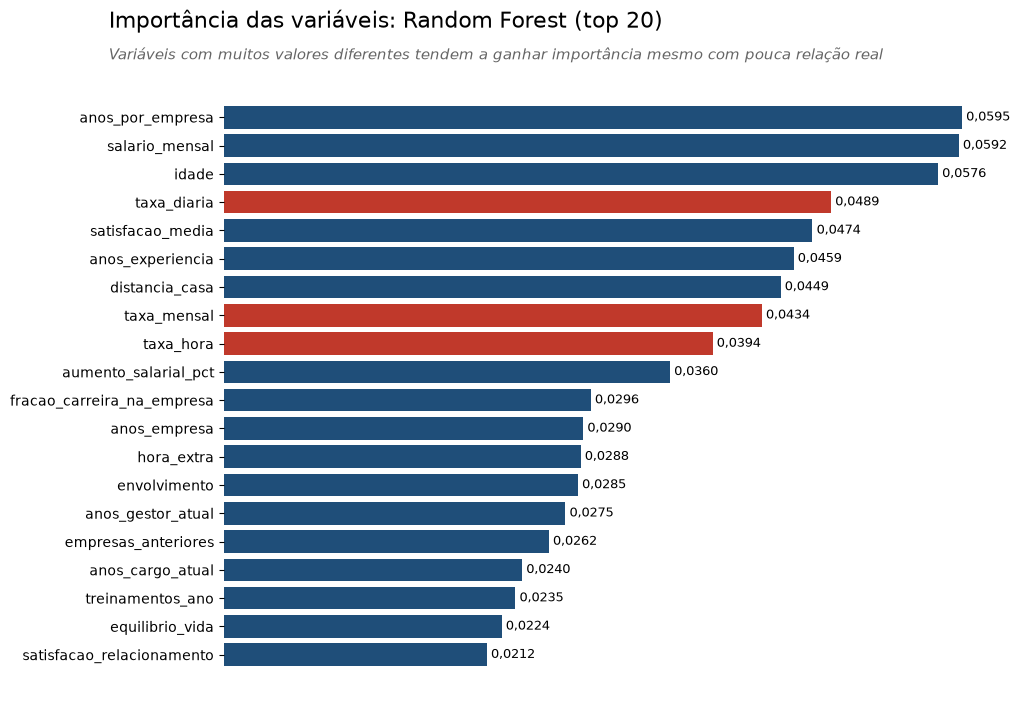

In [35]:
prep_sel = preprocessador(FEATURES_ORIGINAIS + FEATURES_CRIADAS, escalar=False)
X_treino_t = pd.DataFrame(prep_sel.fit_transform(X_treino), index=X_treino.index, columns=prep_sel.get_feature_names_out())
print(f'treino transformado .... {X_treino_t.shape}')

importances = importancia_random_forest(X_treino_t, y_treino, tipo='classificacao', semente=SEMENTE)
print(importances.head(20).round(4).to_string())
plot_barras_h(importances.head(20), 'Importância das variáveis: Random Forest (top 20)', 'Importancia RF (selecao)',
              subtitulo='Variáveis com muitos valores diferentes tendem a ganhar importância mesmo com pouca relação real',
              formato=lambda v: f'{v:.4f}'.replace('.', ','), destaque=TAXAS)

🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de 53):
                                    feature  score
0                         anos_gestor_atual  0.044
1                            salario_mensal  0.042
2                                hora_extra  0.038
3                          anos_por_empresa  0.034
4                          anos_experiencia  0.033
5                               nivel_cargo  0.031
6             cargo_Representante de Vendas  0.030
7                      avaliacao_desempenho  0.028
8                              anos_empresa  0.027
9   departamento_Pesquisa e Desenvolvimento  0.026
10                                    idade  0.026
11                      empresas_anteriores  0.022
12                              nivel_acoes  0.019
13                         satisfacao_media  0.018
14                      area_formacao_Outra  0.017
15                   cargo_Recursos Humanos  0.017
16                              taxa_diaria  0.013
17                   

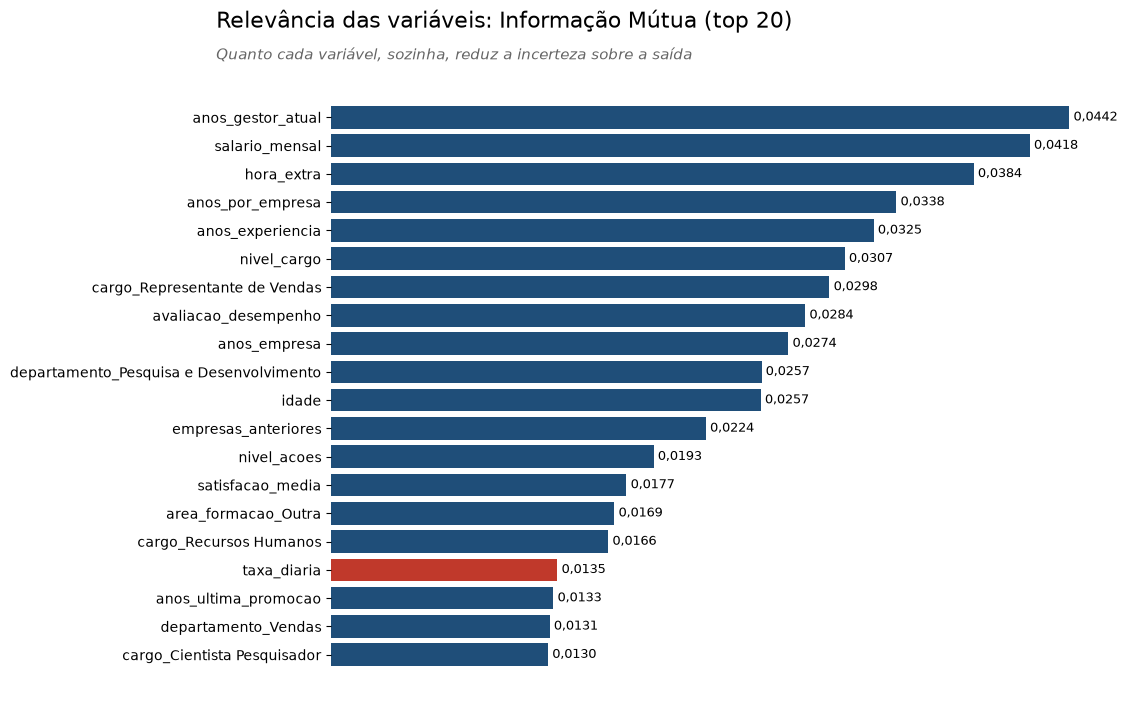

In [36]:
df_scores, selector = selecao_features(X_treino_t, y_treino, k=10, tipo='classificacao', semente=SEMENTE)
print(f'🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (top 20 de {X_treino_t.shape[1]}):')
print('=' * 50)
print(df_scores.head(20).round(4).to_string())
print(f"\ncolunas com informação mútua igual a zero: {(df_scores['score'] == 0).sum()} de {len(df_scores)}")
print('posição das taxas:', {taxa: int(df_scores.index[df_scores['feature'] == taxa][0]) + 1 for taxa in TAXAS})

print('\n🏆 TOP 10 FEATURES SELECIONADAS:')
print('=' * 50)
top_10_features = df_scores.head(10)['feature'].tolist()
for i, (feature, score) in enumerate(df_scores.head(10).itertuples(index=False), 1):
    print(f'{i}. {feature}: {score:.6f}')
print(f'\n📊 Shape original: {X_treino_t.shape}')
print(f'📊 Shape após seleção: {selector.transform(X_treino_t).shape}')

plot_barras_h(df_scores.head(20).set_index('feature')['score'], 'Relevância das variáveis: Informação Mútua (top 20)',
              'Informacao mutua (selecao)', subtitulo='Quanto cada variável, sozinha, reduz a incerteza sobre a saída',
              formato=lambda v: f'{v:.4f}'.replace('.', ','), destaque=TAXAS)

In [37]:
comparacao_selecao = pd.DataFrame({
    'posição RF': importances.rank(ascending=False).astype(int),
    'posição Informação Mútua': df_scores.set_index('feature')['score'].rank(ascending=False, method='first').astype(int),
}).sort_values('posição RF')
comparacao_selecao.head(15)

,posição RF,posição Informação Mútua
anos_por_empresa,1,4
salario_mensal,2,2
idade,3,11
taxa_diaria,4,17
satisfacao_media,5,14
anos_experiencia,6,5
distancia_casa,7,21
taxa_mensal,8,53
taxa_hora,9,29
aumento_salarial_pct,10,46


📌 **Nota**
- 🔎 Os dois métodos concordam em parte: **salário** (2º nos dois), **anos por empresa** (1º e 4º) e **anos de experiência** (6º e 5º) estão no topo.
- ⚠️ O Random Forest coloca as **3 taxas** entre as 10 mais importantes (taxa diária em **4º**, mensal em 8º, por hora em 9º), mesmo sendo ruído (H12). É o viés conhecido do Random Forest por variáveis com **muitos valores diferentes**. A Informação Mútua as coloca em **17º**, **29º** e **53º** (último).
- 🔎 A **hora extra**, maior efeito da EDA (H1), fica em **3º** na Informação Mútua, mas só em **13º** no Random Forest, pelo mesmo viés: é uma variável 0/1.
- 🔎 **20** das 53 colunas têm informação mútua **zero** sozinhas, a maioria categorias pequenas do one-hot.
- ✅ **Decisão:** a confirmação abaixo decide com o modelo de verdade.

#### Confirmação: quais variáveis entram no modelo?

Comparamos o mesmo modelo (Regressão Logística, sem balanceamento, como decidido no item 4.2) com 5 conjuntos de variáveis, na validação cruzada do treino.

> ⚖️ **Gênero fora do modelo:** com o gênero, o modelo dá às mulheres uma chance de sair menor que a dos homens com todo o resto igual (a auditoria da Fase 04, item 2, mede quanto), embora na base bruta homens e mulheres saiam na mesma proporção (H13). Usar gênero para decidir com quem o RH conversa é um problema ético e legal. A decisão foi retirá-lo do modelo. O conjunto "Modelo final" abaixo mede o custo dessa escolha, e a Fase 04 confere se o modelo acerta igual para homens e mulheres.

In [38]:
conjuntos = {
    'Todas as originais (30)': FEATURES_ORIGINAIS,
    'Sem as 3 taxas (27)': CATEGORICAS + NUMERICAS,
    'Sem as taxas + criadas (30)': CATEGORICAS + NUMERICAS + FEATURES_CRIADAS,
    'Modelo final: sem taxas, + criadas, sem gênero (29)': FEATURES,
    'Top 10 da Informação Mútua': None,
}
confirmacao = {}
for nome, colunas in conjuntos.items():
    if colunas is None:
        dados, prep = X_treino_t[top_10_features], StandardScaler()
    else:
        dados, prep = X_treino[colunas], preprocessador(colunas)
    modelo = Pipeline([('prep', prep), ('modelo', LogisticRegression(max_iter=3000))])
    notas = cross_val_score(modelo, dados, y_treino, cv=cv_repetida, scoring='average_precision')
    confirmacao[nome] = {'PR-AUC média': notas.mean(), 'desvio': notas.std()}
pd.DataFrame(confirmacao).T.round(3)

,PR-AUC média,desvio
Todas as originais (30),0.620,0.054
Sem as 3 taxas (27),0.624,0.059
Sem as taxas + criadas (30),0.643,0.060
"Modelo final: sem taxas, + criadas, sem gênero (29)",0.638,0.066
Top 10 da Informação Mútua,0.428,0.053


📌 **Nota**
- 🔎 Tirar as **3 taxas** não perde nada (PR-AUC de **0,620** para **0,624**), o que confirma que são ruído (H12).
- 🔎 As **variáveis criadas** ajudam: a PR-AUC sobe para **0,643**.
- 🔎 Tirar o **gênero** custa quase nada: **0,643 → 0,638**, diferença muito menor que o desvio entre as dobras (**±0,066**).
- 🔎 Ficar só com as **10 melhores** da Informação Mútua **piora muito** (**0,428**): as variáveis "fracas" sozinhas somam informação no modelo.
- ✅ **Decisão:** modelo final com **29 variáveis**: sem as taxas, com as 3 criadas e **sem o gênero**.

## 5 - Treinamento dos Algoritmos de Machine Learning

Todos **sem balanceamento** (item 4.2): o desbalanceamento é tratado no **limiar**, escolhido pelo custo no item 8. Treinados no treino e avaliados na validação, aqui com o limiar padrão de 0,50, que é alto demais para uma classe de 16%: por isso o recall aparece baixo.

**Como vamos medir o desempenho** (classe de interesse = **saiu**):

| Métrica | Fórmula | Pergunta que ela responde | Usar quando |
|---|---|---|---|
| **Recall** | VP / (VP + FN) | Das pessoas que **saíram**, quantas o modelo apontou? | Deixar passar uma saída custa caro (aqui: a reposição) |
| **Precisão** | VP / (VP + FP) | Das pessoas que o modelo apontou, quantas **saíram de fato**? | Um alarme falso custa caro (aqui: a conversa do RH) |
| **F1** | 2 x P x R / (P + R) | Equilíbrio entre recall e precisão (média harmônica) | Classes desbalanceadas, sem custo definido |
| **PR-AUC** | Área sob a curva Precision-Recall | Qualidade da **ordem de risco** em todos os limiares (sorteio = 0,16; perfeito = 1) | Classe rara (fraude, doença, saída): a métrica principal deste projeto |
| **AUC-ROC** | Área sob a curva ROC | Chance de uma pessoa que saiu ter probabilidade maior que uma que ficou (sorteio = 0,50) | Comparação geral entre modelos |
| **Acurácia** | (VP + VN) / Total | Acertos no geral. ⚠️ Chutar "todo mundo fica" já dá 84% | Só com classes balanceadas |

VP = saiu e foi apontado; VN = ficou e não foi apontado; FP = ficou, mas foi apontado (alarme falso); FN = saiu sem ser apontado.

💡 O modelo não devolve "sai" ou "fica", e sim uma **probabilidade**. Recall, precisão, F1 e acurácia dependem do **corte** (limiar) que transforma a probabilidade em "sim": subir o corte dá mais precisão e menos recall; baixar dá o contrário. Não existe corte universal: ele é escolhido pelo custo de cada erro no item 8. PR-AUC e AUC-ROC não dependem do corte, por isso servem para comparar modelos.

Em cada algoritmo: amostra gabarito × previsão, métricas, **treino × validação** (sobreajuste), relatório de classificação e matriz de confusão.

In [39]:
modelos = {
    'Regressão Logística': Pipeline([('prep', preprocessador(FEATURES)),
                                     ('modelo', LogisticRegression(max_iter=3000))]),
    'Naive Bayes': Pipeline([('prep', preprocessador(FEATURES)), ('modelo', GaussianNB())]),
    'Random Forest': Pipeline([('prep', preprocessador(FEATURES, escalar=False)),
                               ('modelo', RandomForestClassifier(random_state=SEMENTE, n_jobs=N_JOBS))]),
    'XGBoost': Pipeline([('prep', preprocessador(FEATURES, escalar=False)),
                         ('modelo', xgb.XGBClassifier(random_state=SEMENTE, n_jobs=N_JOBS))]),
    'LightGBM': Pipeline([('prep', preprocessador(FEATURES, escalar=False)),
                          ('modelo', lgb.LGBMClassifier(random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1))]),
}
metricas_validacao, probas_validacao = {}, {}
Xtr, Xva = X_treino[FEATURES], X_validacao[FEATURES]

### Regressão Logística

A **Regressão Logística** soma o efeito de cada variável com um peso e transforma a soma numa probabilidade. É simples e **fácil de explicar**: cada peso diz se a variável aumenta ou diminui o risco.

Regressão Logística treinado em 0.1s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade de sair,Previsão da máquina
0,0,0.129,0
1,0,0.057,0
2,0,0.000,0
3,0,0.002,0
4,0,0.012,0
5,0,0.024,0
6,0,0.223,0
7,0,0.024,0


MÉTRICAS DE VALIDAÇÃO: Regressão Logística
Acurácia                 0.8844
Precisão                 0.7241
Recall (Sensibilidade)   0.4468
F1-Score                 0.5526
AUC-ROC                  0.8093
PR-AUC                   0.5921
                         (sorteio: PR-AUC = 0.1599, AUC-ROC = 0,50)

SOBREAJUSTE (treino x validação):
  PR-AUC: treino 0.7321 | validação 0.5921 | diferença +0.1400

              precision    recall  f1-score   support

   Ficou (0)      0.902     0.968     0.934       247
    Saiu (1)      0.724     0.447     0.553        47

    accuracy                          0.884       294
   macro avg      0.813     0.707     0.743       294
weighted avg      0.873     0.884     0.873       294



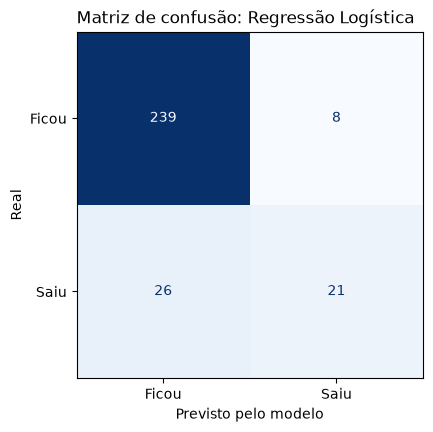

In [40]:
t0 = time.time()
modelos['Regressão Logística'].fit(Xtr, y_treino)
print(f'Regressão Logística treinado em {time.time() - t0:.1f}s' + chr(10))
metricas_validacao['Regressão Logística'], probas_validacao['Regressão Logística'] = relatorio_validacao(
    'Regressão Logística', modelos['Regressão Logística'], Xtr, y_treino, Xva, y_validacao, nome_arquivo='Matriz Regressao Logistica')

📌 **Nota**
- 🔎 PR-AUC de **0,592** (sorteio: 0,160) e AUC-ROC de **0,81**. Com o limiar de 0,50, o modelo é **preciso** (**72%** dos apontados saem) mas encontra só **45%** das saídas: o limiar está alto demais para uma classe de 16% (item 8).
- ✅ **Sobreajuste moderado:** PR-AUC de **0,73** no treino contra **0,59** na validação. É o menor entre os modelos de bom desempenho.

### Naive Bayes

O **Naive Bayes** calcula a probabilidade de saída supondo que as variáveis são **independentes** entre si. É rápido e funciona bem com poucos dados, mas a suposição raramente é verdadeira.

Naive Bayes treinado em 0.0s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade de sair,Previsão da máquina
0,0,0.100,0
1,0,1.000,1
2,0,0.000,0
3,0,0.020,0
4,0,0.000,0
5,0,0.000,0
6,0,1.000,1
7,0,0.027,0


MÉTRICAS DE VALIDAÇÃO: Naive Bayes
Acurácia                 0.6769
Precisão                 0.3000
Recall (Sensibilidade)   0.7660
F1-Score                 0.4311
AUC-ROC                  0.7772
PR-AUC                   0.3995
                         (sorteio: PR-AUC = 0.1599, AUC-ROC = 0,50)

SOBREAJUSTE (treino x validação):
  PR-AUC: treino 0.4161 | validação 0.3995 | diferença +0.0166

              precision    recall  f1-score   support

   Ficou (0)      0.937     0.660     0.774       247
    Saiu (1)      0.300     0.766     0.431        47

    accuracy                          0.677       294
   macro avg      0.618     0.713     0.603       294
weighted avg      0.835     0.677     0.719       294



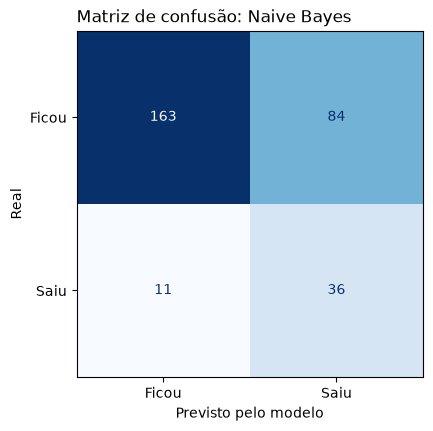

In [41]:
t0 = time.time()
modelos['Naive Bayes'].fit(Xtr, y_treino)
print(f'Naive Bayes treinado em {time.time() - t0:.1f}s' + chr(10))
metricas_validacao['Naive Bayes'], probas_validacao['Naive Bayes'] = relatorio_validacao(
    'Naive Bayes', modelos['Naive Bayes'], Xtr, y_treino, Xva, y_validacao, nome_arquivo='Matriz Naive Bayes')

📌 **Nota**
- 🔎 O Naive Bayes encontra mais saídas (recall de **77%**), mas erra muito: só **30%** dos apontados saem, e a PR-AUC é a pior (**0,40**).
- ⚠️ As probabilidades vão quase sempre para **0 ou 1** (veja a amostra): a suposição de variáveis independentes não vale aqui, porque idade, salário, nível e tempo de casa andam juntos.

### Random Forest

O **Random Forest** treina **centenas de árvores de decisão** independentes e tira a média, como pedir a opinião de vários especialistas.

Random Forest treinado em 0.6s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade de sair,Previsão da máquina
0,0,0.150,0
1,0,0.010,0
2,0,0.030,0
3,0,0.060,0
4,0,0.030,0
5,0,0.090,0
6,0,0.210,0
7,0,0.290,0



MÉTRICAS DE VALIDAÇÃO: Random Forest
Acurácia                 0.8741
Precisão                 0.7500
Recall (Sensibilidade)   0.3191
F1-Score                 0.4478
AUC-ROC                  0.8055
PR-AUC                   0.5554
                         (sorteio: PR-AUC = 0.1599, AUC-ROC = 0,50)

SOBREAJUSTE (treino x validação):
  PR-AUC: treino 1.0000 | validação 0.5554 | diferença +0.4446



              precision    recall  f1-score   support

   Ficou (0)      0.883     0.980     0.929       247
    Saiu (1)      0.750     0.319     0.448        47

    accuracy                          0.874       294
   macro avg      0.817     0.649     0.688       294
weighted avg      0.862     0.874     0.852       294



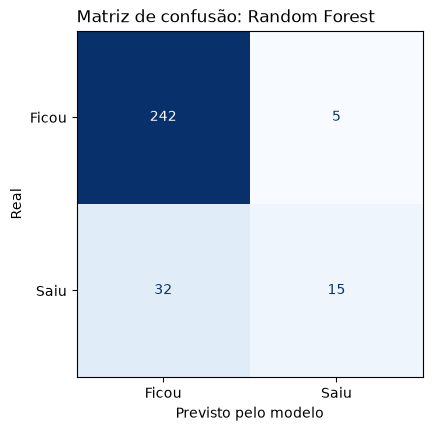

In [42]:
t0 = time.time()
modelos['Random Forest'].fit(Xtr, y_treino)
print(f'Random Forest treinado em {time.time() - t0:.1f}s' + chr(10))
metricas_validacao['Random Forest'], probas_validacao['Random Forest'] = relatorio_validacao(
    'Random Forest', modelos['Random Forest'], Xtr, y_treino, Xva, y_validacao, nome_arquivo='Matriz Random Forest')

📌 **Nota**
- 🔎 PR-AUC de **0,555**. Com o limiar de 0,50, aponta poucas pessoas: **75%** de precisão, mas só **32%** de recall.
- ⚠️ **Sobreajuste total:** PR-AUC de **1,00** no treino. As árvores decoram os 882 funcionários do treino.

### XGBoost

O **XGBoost** constrói **árvores em sequência**: cada nova árvore tenta corrigir os erros das anteriores.

XGBoost treinado em 1.1s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade de sair,Previsão da máquina
0,0,0.011,0
1,0,0.000,0
2,0,0.000,0
3,0,0.000,0
4,0,0.006,0
5,0,0.000,0
6,0,0.260,0
7,0,0.039,0


MÉTRICAS DE VALIDAÇÃO: XGBoost
Acurácia                 0.8571
Precisão                 0.5862
Recall (Sensibilidade)   0.3617
F1-Score                 0.4474
AUC-ROC                  0.7684
PR-AUC                   0.5398
                         (sorteio: PR-AUC = 0.1599, AUC-ROC = 0,50)

SOBREAJUSTE (treino x validação):
  PR-AUC: treino 1.0000 | validação 0.5398 | diferença +0.4602

              precision    recall  f1-score   support

   Ficou (0)      0.887     0.951     0.918       247
    Saiu (1)      0.586     0.362     0.447        47

    accuracy                          0.857       294
   macro avg      0.736     0.657     0.683       294
weighted avg      0.839     0.857     0.843       294



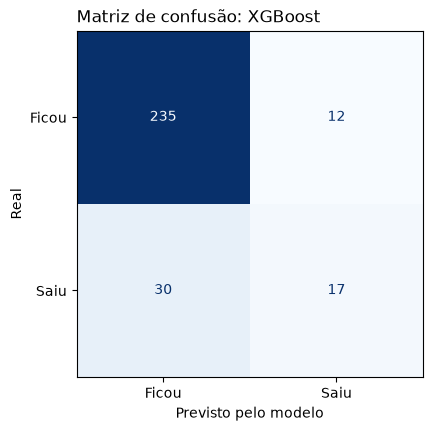

In [43]:
t0 = time.time()
modelos['XGBoost'].fit(Xtr, y_treino)
print(f'XGBoost treinado em {time.time() - t0:.1f}s' + chr(10))
metricas_validacao['XGBoost'], probas_validacao['XGBoost'] = relatorio_validacao(
    'XGBoost', modelos['XGBoost'], Xtr, y_treino, Xva, y_validacao, nome_arquivo='Matriz XGBoost')

📌 **Nota**
- 🔎 PR-AUC de **0,540**, abaixo da Regressão Logística, com recall de **36%** no limiar de 0,50.
- ⚠️ **Sobreajuste total:** **1,00** no treino. Com poucos dados, o XGBoost padrão é complexo demais.

### LightGBM

O **LightGBM** segue a ideia do XGBoost, crescendo cada árvore pelo galho mais promissor.

LightGBM treinado em 0.3s

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade de sair,Previsão da máquina
0,0,0.001,0
1,0,0.000,0
2,0,0.000,0
3,0,0.001,0
4,0,0.000,0
5,0,0.001,0
6,0,0.085,0
7,0,0.004,0


MÉTRICAS DE VALIDAÇÃO: LightGBM
Acurácia                 0.8946
Precisão                 0.7353
Recall (Sensibilidade)   0.5319
F1-Score                 0.6173
AUC-ROC                  0.7994
PR-AUC                   0.5981
                         (sorteio: PR-AUC = 0.1599, AUC-ROC = 0,50)

SOBREAJUSTE (treino x validação):
  PR-AUC: treino 1.0000 | validação 0.5981 | diferença +0.4019

              precision    recall  f1-score   support

   Ficou (0)      0.915     0.964     0.939       247
    Saiu (1)      0.735     0.532     0.617        47

    accuracy                          0.895       294
   macro avg      0.825     0.748     0.778       294
weighted avg      0.887     0.895     0.887       294



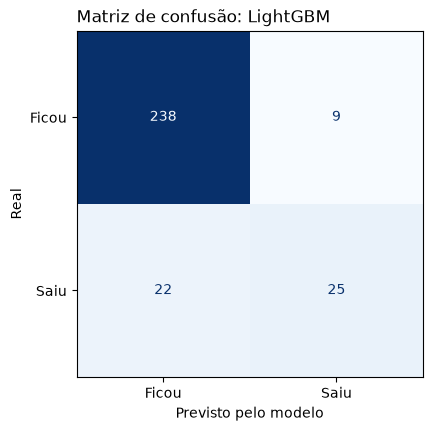

In [44]:
t0 = time.time()
modelos['LightGBM'].fit(Xtr, y_treino)
print(f'LightGBM treinado em {time.time() - t0:.1f}s' + chr(10))
metricas_validacao['LightGBM'], probas_validacao['LightGBM'] = relatorio_validacao(
    'LightGBM', modelos['LightGBM'], Xtr, y_treino, Xva, y_validacao, nome_arquivo='Matriz LightGBM')

📌 **Nota**
- 🔎 O LightGBM tem a melhor PR-AUC **nesta validação** (**0,598**) e o melhor F1 (**0,62**).
- ⚠️ Mas também decora o treino (**1,00**), e com só 47 saídas na validação, um resultado isolado pode ser sorte. A validação cruzada abaixo decide.

### Validação cruzada

A validação tem só **47 saídas**: um ou dois acertos a mais mudam muito as métricas. A validação cruzada estratificada (**5 dobras × 3 repetições**, em treino + validação) mostra a **média ± desvio** e decide o modelo.

In [45]:
resultados_cv = {}
for nome, modelo in modelos.items():
    r = cross_validate(clone(modelo), X_treino_val[FEATURES], y_treino_val, cv=cv_repetida,
                       scoring=['average_precision', 'roc_auc', 'recall', 'precision', 'f1'])
    resultados_cv[nome] = {'PR-AUC (média)': r['test_average_precision'].mean(), 'PR-AUC (desvio)': r['test_average_precision'].std(),
                           'AUC-ROC (média)': r['test_roc_auc'].mean(), 'Recall (média)': r['test_recall'].mean(),
                           'Precisão (média)': r['test_precision'].mean(), 'F1 (média)': r['test_f1'].mean()}
tabela_cv = pd.DataFrame(resultados_cv).T.sort_values('PR-AUC (média)', ascending=False)
melhor_modelo = tabela_cv.index[0]
print(f'Melhor modelo na validação cruzada: {melhor_modelo}')
tabela_cv.round(3)

Melhor modelo na validação cruzada: Regressão Logística


,PR-AUC (média),PR-AUC (desvio),AUC-ROC (média),Recall (média),Precisão (média),F1 (média)
Regressão Logística,0.648,0.046,0.839,0.433,0.755,0.545
LightGBM,0.564,0.052,0.798,0.333,0.677,0.444
XGBoost,0.561,0.046,0.796,0.377,0.688,0.485
Random Forest,0.542,0.054,0.796,0.204,0.789,0.318
Naive Bayes,0.410,0.058,0.757,0.756,0.277,0.402


📌 **Nota**
- 🔎 Na validação cruzada (15 rodadas), a **Regressão Logística** vence com folga: PR-AUC de **0,648 ± 0,046**, contra **0,564** do LightGBM, **0,561** do XGBoost, **0,542** do Random Forest e **0,410** do Naive Bayes.
- 🔎 A vantagem do LightGBM na validação (0,598 contra 0,592) **não se repete** nas outras divisões: era sorte daquela divisão.
- 💡 Com 1.470 funcionários e efeitos que somam (hora extra, idade, salário...), um modelo **simples** generaliza melhor que árvores complexas. E a Regressão Logística é a mais fácil de explicar ao RH.

## 6 - Comparação do desempenho dos modelos

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC,PR-AUC CV (média ± desvio),Verdadeiros Positivos,Falsos Positivos,Falsos Negativos
LightGBM,0.895,0.735,0.532,0.617,0.799,0.598,0.564 ± 0.052,25.000000,9.000000,22.000000
Regressão Logística,0.884,0.724,0.447,0.553,0.809,0.592,0.648 ± 0.046,21.000000,8.000000,26.000000
Random Forest,0.874,0.750,0.319,0.448,0.805,0.555,0.542 ± 0.054,15.000000,5.000000,32.000000
XGBoost,0.857,0.586,0.362,0.447,0.768,0.540,0.561 ± 0.046,17.000000,12.000000,30.000000
Naive Bayes,0.677,0.300,0.766,0.431,0.777,0.399,0.410 ± 0.058,36.000000,84.000000,11.000000
Modelo que chuta,0.840,0.000,0.000,0.000,0.500,0.160,–,0.000000,0.000000,47.000000


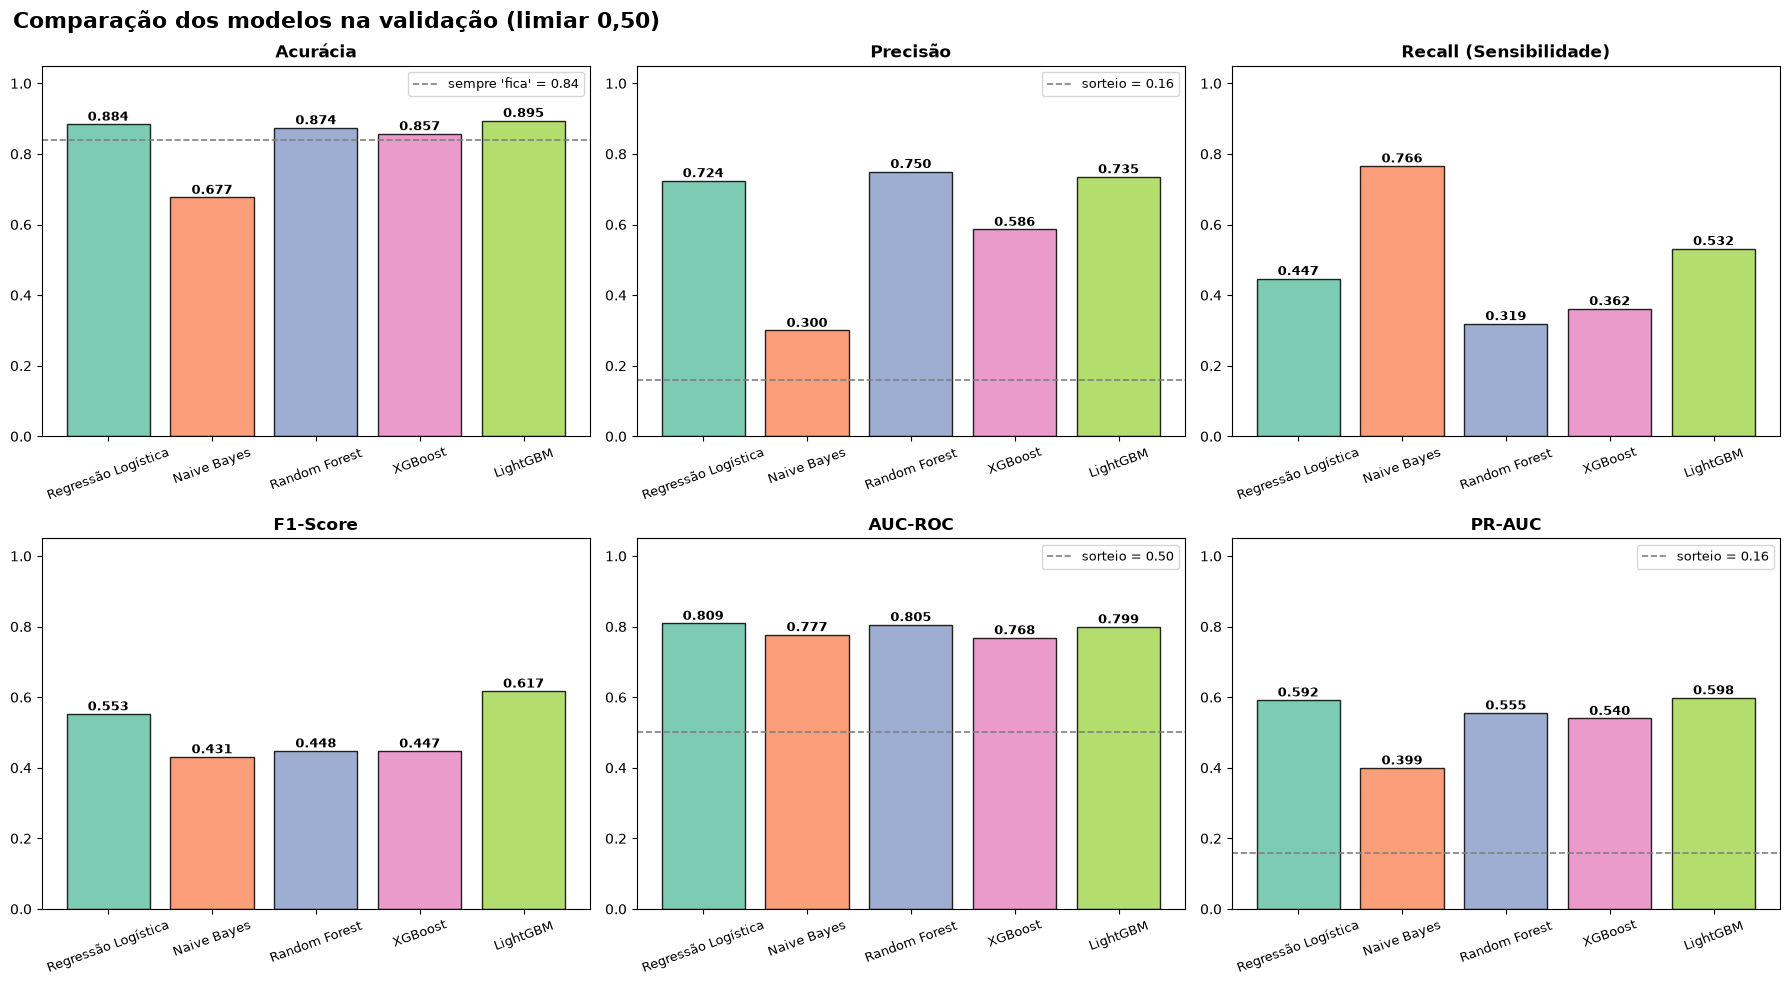

📊 SCORE GERAL (média de F1, PR-AUC, Recall e Precisão na validação):
• LightGBM             0.621 | PR-AUC CV 0.564 ± 0.052
• Regressão Logística  0.579 | PR-AUC CV 0.648 ± 0.046
• Random Forest        0.518 | PR-AUC CV 0.542 ± 0.054
• XGBoost              0.484 | PR-AUC CV 0.561 ± 0.046
• Naive Bayes          0.474 | PR-AUC CV 0.410 ± 0.058

💾 Resultados salvos em: reports/comparacao_modelos.csv


In [46]:
chute = DummyClassifier(strategy='prior').fit(Xtr, y_treino)   # "modelo que chuta": sempre a taxa de saída do treino
proba_chute = chute.predict_proba(Xva)[:, 1]
metricas_tabela = dict(metricas_validacao)
metricas_tabela['Modelo que chuta'] = calcular_metricas_completas(y_validacao, (proba_chute >= 0.5).astype(int), proba_chute)

df_comparacao = pd.DataFrame(metricas_tabela).T
df_comparacao['PR-AUC CV (média ± desvio)'] = [
    f"{tabela_cv.loc[m, 'PR-AUC (média)']:.3f} ± {tabela_cv.loc[m, 'PR-AUC (desvio)']:.3f}" if m in tabela_cv.index else '–'
    for m in df_comparacao.index]
df_comparacao = df_comparacao.sort_values('PR-AUC', ascending=False)
PASTA_REPORTS.mkdir(exist_ok=True)
df_comparacao.to_csv(PASTA_REPORTS / 'comparacao_modelos.csv')

colunas = ['Acurácia', 'Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC', 'PR-AUC CV (média ± desvio)',
           'Verdadeiros Positivos', 'Falsos Positivos', 'Falsos Negativos']
display(df_comparacao[colunas].style.format('{:.3f}', subset=colunas[:6]))
plot_comparacao_modelos(metricas_validacao, y_validacao.mean(), 'Comparacao dos modelos')

score_geral = df_comparacao.loc[list(metricas_validacao), ['F1-Score', 'PR-AUC', 'Recall (Sensibilidade)', 'Precisão']].mean(axis=1)
print('📊 SCORE GERAL (média de F1, PR-AUC, Recall e Precisão na validação):')
for nome, valor in score_geral.sort_values(ascending=False).items():
    print(f'• {nome:<20} {valor:.3f} | PR-AUC CV {df_comparacao.loc[nome, "PR-AUC CV (média ± desvio)"]}')
print('\n💾 Resultados salvos em: reports/comparacao_modelos.csv')

📌 **Nota**
- 🔎 **Como ler o painel:** a linha tracejada é o "modelo que chuta". Na acurácia, todos parecem bons (o chute já acerta **84%**). Na PR-AUC, o chute fica em **0,16** e os modelos entre **0,40** e **0,60**.
- 🔎 No score geral desta validação, o LightGBM aparece em 1º (**0,621**), mas a validação cruzada mostra que essa vantagem não se sustenta (item anterior).
- ✅ **Decisão:** seguir com a **Regressão Logística** para o ajuste fino: melhor e mais estável na validação cruzada, menor sobreajuste e coeficientes interpretáveis.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

**Parâmetros x hiperparâmetros.** Os **parâmetros** são o que o modelo aprende sozinho com os dados (na Regressão Logística, o peso de cada variável). Os **hiperparâmetros** são as configurações que **nós** escolhemos antes do treino e que controlam **como** ele aprende. Na Regressão Logística, os principais são:

| Hiperparâmetro | O que controla | Em palavras simples |
|---|---|---|
| `C` | a força da **regularização** (quanto menor, mais forte) | o quanto o modelo é "freado" para não decorar o treino |
| `l1_ratio` | o tipo de regularização: **0 = L2** (encolhe todos os pesos), **1 = L1** (zera os pesos das variáveis fracas), entre 0 e 1 = mistura (*elastic net*) | encolher tudo um pouco ou descartar variáveis |

Comparamos os **três métodos** de busca mais usados, todos com as **mesmas 5 dobras estratificadas** do treino e a mesma métrica (PR-AUC):

| Método | Como escolhe as combinações | Ponto forte | Ponto fraco |
|---|---|---|---|
| **Grid Search** | testa **todas** as combinações de uma grade | se a melhor estiver na grade, ele a encontra | o custo **explode** com o número de hiperparâmetros |
| **Random Search** | **sorteia** N combinações | explora mais valores com o mesmo orçamento | não aprende com o que já testou |
| **Bayesiana (Optuna)** | usa os resultados anteriores para escolher a **próxima** combinação | concentra as tentativas nas regiões promissoras | mais complexa de explicar |

> 🛡️ **O teste fica trancado.** Escolher os hiperparâmetros pelo resultado no teste ajustaria o modelo **àquelas** 294 pessoas (sobreajuste de hiperparâmetros). A escolha usa só a **validação cruzada do treino**; o teste é aberto uma única vez, no item 7.6.

> 🔁 **Por que dobras estratificadas?** Com 16% de saídas, uma divisão comum pode deixar uma dobra com bem menos saídas que as outras. O *Stratified K-Fold* garante os mesmos ~16% em cada dobra. (O *TimeSeriesSplit* seria o certo para dados com ordem no tempo; a base do RH é um retrato de um único momento.)

### 7.1. Grid Search

Com só 2 hiperparâmetros, o espaço é pequeno: é o caso em que o Grid Search é a escolha natural. A grade tem **11 valores de `C`** em escala logarítmica (de 0,001 a 100) e os **2 tipos de regularização** (L1 e L2).

Grade: 22 combinações x 5 dobras = 110 modelos treinados


Grid Search concluído em 18.8s | melhor PR-AUC (CV): 0.6637
Melhores hiperparâmetros: {'C': 0.1, 'l1_ratio': 0, 'solver': 'liblinear'}


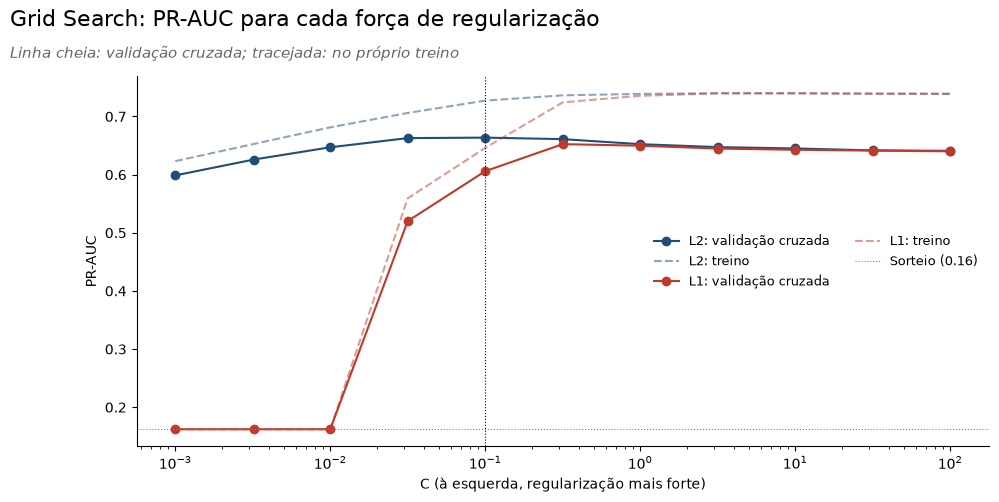

In [47]:
grades = {
    'Regressão Logística': {'modelo__C': np.logspace(-3, 2, 11).round(4).tolist(), 'modelo__l1_ratio': [0, 1], 'modelo__solver': ['liblinear']},
    'Naive Bayes': {'modelo__var_smoothing': np.logspace(-12, -1, 12).tolist()},
    'Random Forest': {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [None, 6, 10], 'modelo__min_samples_leaf': [1, 5, 10]},
    'XGBoost': {'modelo__learning_rate': [0.02, 0.05, 0.1], 'modelo__max_depth': [2, 3, 4], 'modelo__min_child_weight': [1, 5, 10]},
    'LightGBM': {'modelo__learning_rate': [0.02, 0.05, 0.1], 'modelo__num_leaves': [4, 8, 16], 'modelo__min_child_samples': [10, 30, 60]},
}
cv_busca = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
grade = grades[melhor_modelo]
n_combinacoes = int(np.prod([len(valores) for valores in grade.values()]))
print(f'Grade: {n_combinacoes} combinações x {cv_busca.get_n_splits()} dobras = {n_combinacoes * cv_busca.get_n_splits()} modelos treinados')

grid = GridSearchCV(clone(modelos[melhor_modelo]), grade, scoring='average_precision', cv=cv_busca, n_jobs=N_JOBS, return_train_score=True)
t0 = time.time()
grid.fit(Xtr, y_treino)
tempo_grid = time.time() - t0
print(f'Grid Search concluído em {tempo_grid:.1f}s | melhor PR-AUC (CV): {grid.best_score_:.4f}')
print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): v for k, v in grid.best_params_.items()})

# Curva de validação: PR-AUC no treino e na validação cruzada para cada C, com L1 e com L2
if 'modelo__C' in grade:
    resultados_grid = pd.DataFrame(grid.cv_results_)
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for razao, nome, cor in [(0, 'L2', COR_PRINCIPAL), (1, 'L1', COR_SAIU)]:
        parte = resultados_grid[resultados_grid['param_modelo__l1_ratio'] == razao].sort_values('param_modelo__C')
        valores_c = parte['param_modelo__C'].astype(float)
        ax.plot(valores_c, parte['mean_test_score'], marker='o', color=cor, label=f'{nome}: validação cruzada')
        ax.plot(valores_c, parte['mean_train_score'], ls='--', color=cor, alpha=0.5, label=f'{nome}: treino')
    ax.axhline(y_treino.mean(), color='grey', lw=0.8, ls=':', label=f'Sorteio ({y_treino.mean():.2f})')
    ax.axvline(grid.best_params_['modelo__C'], color='black', lw=0.8, ls=':')
    ax.set(xscale='log', xlabel='C (à esquerda, regularização mais forte)', ylabel='PR-AUC')
    ax.legend(frameon=False, fontsize=9, ncol=2)
    sns.despine()
    titulo('Grid Search: PR-AUC para cada força de regularização', 'Linha cheia: validação cruzada; tracejada: no próprio treino')
    salvar('Grid search')
    plt.show()

📌 **Nota**
- 🔎 A grade tem **22 combinações x 5 dobras = 110 modelos**, treinados em **19 s**. A melhor é **C = 0,1 com L2**, com PR-AUC de **0,664** na validação cruzada.
- 🔎 **A curva mostra os dois erros de regularização:** à esquerda (C pequeno, freio forte), o modelo **não aprende o suficiente**; com L1 e C de até 0,01, ele zera todos os pesos e a PR-AUC cai ao nível do sorteio (**0,16**). À direita (C grande, quase sem freio), a PR-AUC no treino sobe para **~0,74** e a da validação cruzada cai para **~0,64**: o modelo começa a **decorar** o treino. O melhor ponto fica no meio (C entre 0,03 e 0,3).
- 🔎 A **L2** fica acima ou igual à L1 em todos os valores de C. Com 48 colunas que somam efeitos pequenos, encolher todos os pesos funciona melhor que descartar variáveis, o mesmo que a confirmação do item 4.3 mostrou (as variáveis "fracas" somam informação).
- 💡 Com só 2 hiperparâmetros, o Grid é barato e cobre o espaço todo: é o caso em que ele é a escolha natural.

### 7.2. Random Search

O Random Search **sorteia** 30 combinações, com `C` vindo de uma distribuição **contínua** em escala logarítmica (`loguniform`), em vez de uma lista fixa. Ajustamos o melhor modelo da validação cruzada com `RandomizedSearchCV` (30 combinações), **otimizando a PR-AUC** em 5 dobras estratificadas do treino. A versão original otimizava a **acurácia**, testou 2.800 combinações (várias inválidas, como `bootstrap='False'` em texto) e levou 30 minutos.

Busca (Regressão Logística) concluída em 11s | melhor PR-AUC (CV): 0.6644
Melhores hiperparâmetros: {'C': np.float64(0.1789), 'l1_ratio': 0, 'solver': 'liblinear'}


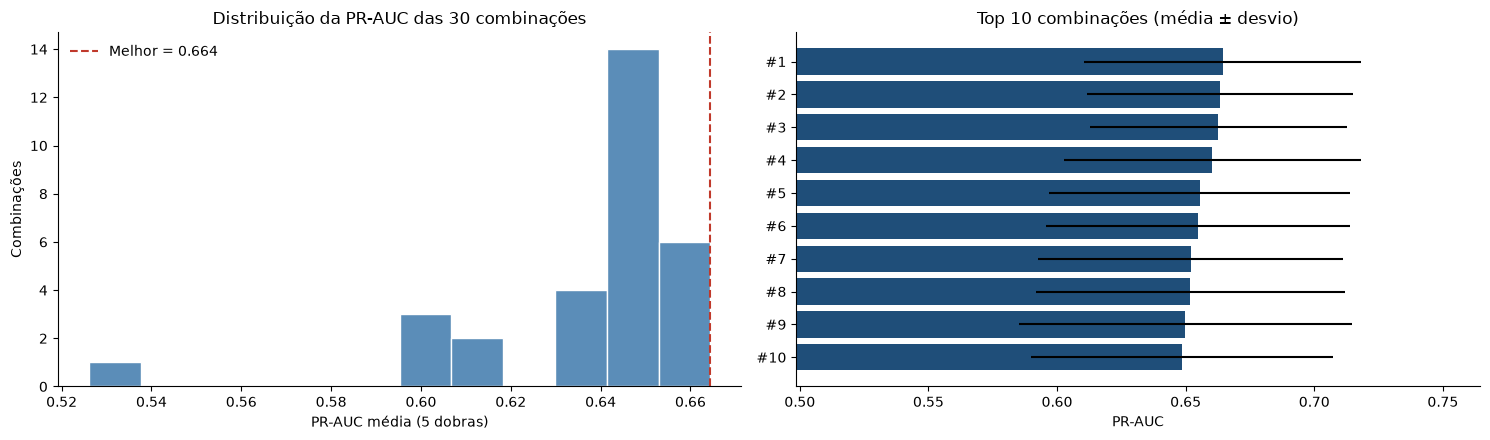

,rank_test_score,mean_test_score,std_test_score,C,l1_ratio,solver
21,1,0.664,0.054,0.179,0,liblinear
5,2,0.663,0.052,0.047,0,liblinear
29,3,0.663,0.050,0.090,0,liblinear
18,4,0.660,0.058,0.373,0,liblinear
23,5,0.655,0.059,0.655,0,liblinear


In [48]:
espacos = {
    'Regressão Logística': {'modelo__C': loguniform(0.001, 100), 'modelo__l1_ratio': [1, 0], 'modelo__solver': ['liblinear']},
    'Naive Bayes': {'modelo__var_smoothing': loguniform(1e-12, 1e-1)},
    'Random Forest': {'modelo__n_estimators': randint(200, 600), 'modelo__max_depth': [None, 4, 6, 10],
                      'modelo__min_samples_leaf': randint(1, 15), 'modelo__max_features': ['sqrt', 0.3, 0.5]},
    'XGBoost': {'modelo__n_estimators': randint(100, 500), 'modelo__max_depth': randint(2, 6),
                'modelo__learning_rate': loguniform(0.01, 0.3), 'modelo__subsample': uniform(0.6, 0.4),
                'modelo__colsample_bytree': uniform(0.4, 0.6), 'modelo__min_child_weight': randint(1, 10)},
    'LightGBM': {'modelo__n_estimators': randint(100, 500), 'modelo__num_leaves': randint(4, 32),
                 'modelo__learning_rate': loguniform(0.01, 0.3), 'modelo__min_child_samples': randint(10, 60),
                 'modelo__subsample': uniform(0.6, 0.4), 'modelo__subsample_freq': [1], 'modelo__colsample_bytree': uniform(0.4, 0.6)},
}
cv_busca = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
busca = RandomizedSearchCV(clone(modelos[melhor_modelo]), espacos[melhor_modelo], n_iter=30, scoring='average_precision',
                           cv=cv_busca, random_state=SEMENTE, n_jobs=N_JOBS, return_train_score=True)
t0 = time.time()
busca.fit(Xtr, y_treino)
tempo_random = time.time() - t0
print(f'Busca ({melhor_modelo}) concluída em {tempo_random:.0f}s | melhor PR-AUC (CV): {busca.best_score_:.4f}')
print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): (round(v, 4) if isinstance(v, float) else v)
                                    for k, v in busca.best_params_.items()})

resultados_busca = pd.DataFrame(busca.cv_results_).sort_values('rank_test_score')
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].hist(resultados_busca['mean_test_score'], bins=12, color=COR_FICOU, edgecolor='white')
axs[0].axvline(busca.best_score_, color=COR_SAIU, ls='--', label=f'Melhor = {busca.best_score_:.3f}')
axs[0].set(title='Distribuição da PR-AUC das 30 combinações', xlabel='PR-AUC média (5 dobras)', ylabel='Combinações')
axs[0].legend(frameon=False)
top10_busca = resultados_busca.head(10)
axs[1].barh(range(10)[::-1], top10_busca['mean_test_score'], xerr=top10_busca['std_test_score'], color=COR_PRINCIPAL)
axs[1].set(yticks=range(10)[::-1], yticklabels=[f'#{i}' for i in top10_busca['rank_test_score']],
           title='Top 10 combinações (média ± desvio)', xlabel='PR-AUC')
axs[1].set_xlim(max(0, top10_busca['mean_test_score'].min() - 0.15), min(1, top10_busca['mean_test_score'].max() + 0.1))
sns.despine()
plt.tight_layout()
salvar('Random Search')
plt.show()

colunas_parametros = [coluna for coluna in resultados_busca if coluna.startswith('param_')]
top5 = resultados_busca[['rank_test_score', 'mean_test_score', 'std_test_score'] + colunas_parametros].head(5)
top5.columns = [coluna.replace('param_modelo__', '') for coluna in top5.columns]
top5

📌 **Nota**
- 🔎 A melhor combinação usa **regularização mais forte** (C = **0,18**; o padrão é 1) com penalidade L2 (`l1_ratio = 0`): o modelo "encolhe" os pesos e confia menos em detalhes do treino.
- 🔎 As 5 melhores combinações ficam entre **0,655** e **0,664**, todas com L2: o resultado é estável. A busca levou **11 segundos**, contra 30 minutos da versão original.

### 7.3. Otimização Bayesiana (Optuna)

O Grid e o Random Search **não aprendem** com o que já testaram. A otimização **Bayesiana** usa o histórico: depois de cada tentativa (*trial*), um modelo probabilístico (o **TPE** do Optuna) estima onde estão as combinações promissoras e escolhe a próxima, equilibrando **exploração** (regiões desconhecidas; as 10 primeiras tentativas são sorteadas) e **explotação** (refinar em volta das melhores).

Aproveitamos uma vantagem do Optuna: o espaço de busca é definido **dentro** da função, com valores contínuos. Aqui, o `l1_ratio` pode ser **qualquer valor entre 0 e 1** (a mistura de L1 e L2, o *elastic net*), o que a grade com só 0 e 1 não testa. Para isso, o solver passa a ser o `saga`, o único que aceita a mistura. Mesmo orçamento do Random Search: **30 tentativas**.

Optuna concluído em 64.9s | melhor PR-AUC (CV): 0.6612 (tentativa nº 20)
Melhores hiperparâmetros: {'C': 0.163, 'l1_ratio': 0.0875}


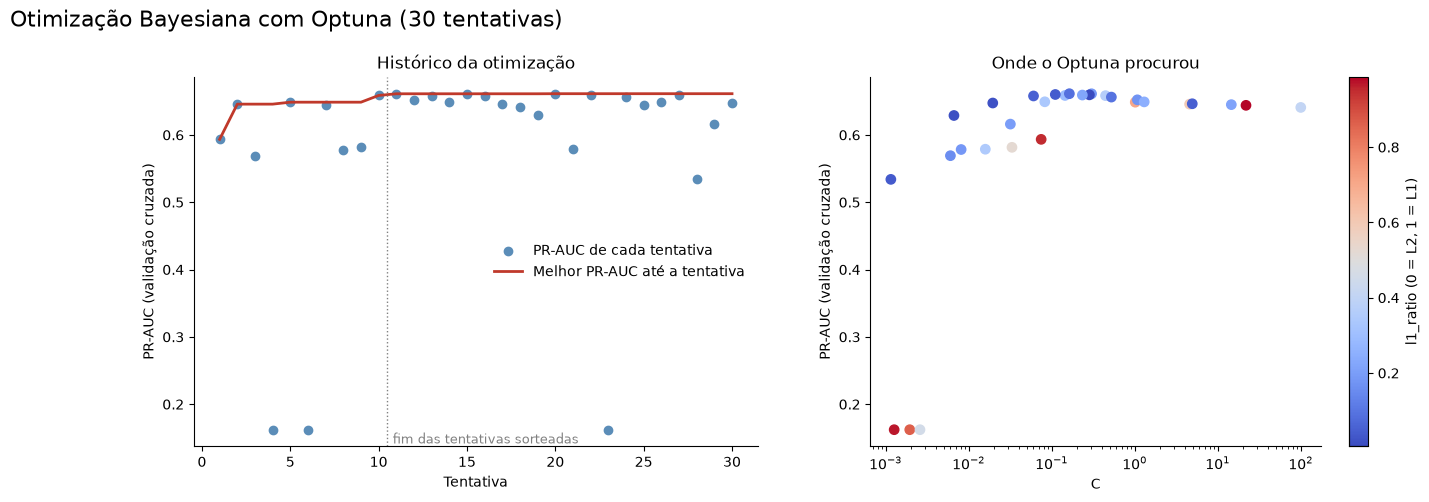

In [49]:
espacos_optuna = {
    'Regressão Logística': lambda t: {'modelo__C': t.suggest_float('C', 1e-3, 100, log=True),
                                      'modelo__l1_ratio': t.suggest_float('l1_ratio', 0.0, 1.0), 'modelo__solver': 'saga'},
    'Naive Bayes': lambda t: {'modelo__var_smoothing': t.suggest_float('var_smoothing', 1e-12, 1e-1, log=True)},
    'Random Forest': lambda t: {'modelo__n_estimators': t.suggest_int('n_estimators', 200, 600, step=50),
                                'modelo__max_depth': t.suggest_int('max_depth', 3, 15),
                                'modelo__min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 15),
                                'modelo__max_features': t.suggest_float('max_features', 0.2, 0.8)},
    'XGBoost': lambda t: {'modelo__n_estimators': t.suggest_int('n_estimators', 100, 500, step=50),
                          'modelo__learning_rate': t.suggest_float('learning_rate', 0.01, 0.3, log=True),
                          'modelo__max_depth': t.suggest_int('max_depth', 2, 6),
                          'modelo__subsample': t.suggest_float('subsample', 0.6, 1.0),
                          'modelo__colsample_bytree': t.suggest_float('colsample_bytree', 0.4, 1.0),
                          'modelo__min_child_weight': t.suggest_int('min_child_weight', 1, 10)},
    'LightGBM': lambda t: {'modelo__n_estimators': t.suggest_int('n_estimators', 100, 500, step=50),
                           'modelo__learning_rate': t.suggest_float('learning_rate', 0.01, 0.3, log=True),
                           'modelo__num_leaves': t.suggest_int('num_leaves', 4, 32, log=True),
                           'modelo__min_child_samples': t.suggest_int('min_child_samples', 10, 60)},
}
estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMENTE))
objetivo = objetivo_cv(clone(modelos[melhor_modelo]), espacos_optuna[melhor_modelo], Xtr, y_treino, cv_busca, 'average_precision', N_JOBS)
t0 = time.time()
estudo.optimize(objetivo, n_trials=30)
tempo_optuna = time.time() - t0
print(f'Optuna concluído em {tempo_optuna:.1f}s | melhor PR-AUC (CV): {estudo.best_value:.4f} (tentativa nº {estudo.best_trial.number + 1})')
print('Melhores hiperparâmetros:', {k: round(v, 4) if isinstance(v, float) else v for k, v in estudo.best_params.items()})

fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
valores, melhor_ate_aqui = historico_optuna(estudo)
axs[0].scatter(range(1, len(valores) + 1), valores, color=COR_FICOU, label='PR-AUC de cada tentativa')
axs[0].plot(range(1, len(valores) + 1), melhor_ate_aqui, color=COR_SAIU, lw=2, label='Melhor PR-AUC até a tentativa')
axs[0].axvline(10.5, color='grey', ls=':', lw=1)
axs[0].text(10.8, axs[0].get_ylim()[0], 'fim das tentativas sorteadas', va='bottom', fontsize=9, color='grey')
axs[0].set(title='Histórico da otimização', xlabel='Tentativa', ylabel='PR-AUC (validação cruzada)')
axs[0].legend(frameon=False)
if 'C' in estudo.best_params:
    tentativas = estudo.trials_dataframe()
    pontos = axs[1].scatter(tentativas['params_C'], tentativas['value'], c=tentativas['params_l1_ratio'], cmap='coolwarm', s=45)
    plt.colorbar(pontos, ax=axs[1], label='l1_ratio (0 = L2, 1 = L1)')
    axs[1].set(xscale='log', title='Onde o Optuna procurou', xlabel='C', ylabel='PR-AUC (validação cruzada)')
else:
    importancia_hps = pd.Series(optuna.importance.get_param_importances(estudo)).sort_values()
    axs[1].barh(importancia_hps.index, importancia_hps.values, color=COR_PRINCIPAL)
    axs[1].set(title='Importância de cada hiperparâmetro (fANOVA)')
sns.despine()
titulo('Otimização Bayesiana com Optuna (30 tentativas)')
salvar('Otimizacao bayesiana')
plt.show()

📌 **Nota**
- 🔎 O Optuna encontrou PR-AUC de **0,661** (tentativa nº 20) com **C = 0,16** e **l1_ratio = 0,09**: uma mistura quase toda L2. Ficou **um pouco abaixo** do Grid e do Random Search (**0,664**).
- 🔎 **Onde ele procurou** (gráfico da direita): as melhores tentativas formam um platô com **C entre 0,05 e 1** e **l1_ratio baixo** (pontos azuis), a mesma região que o Grid apontou. As tentativas com muita L1 (vermelho) e C pequeno zeram os pesos e caem para **0,16**: o Optuna gastou 3 das 30 tentativas aprendendo que essa região é ruim.
- 🔎 A mistura de L1 e L2 (*elastic net*), que só o Optuna testou, **não melhorou nada**: confirma que a L2 pura é a melhor escolha.
- 🔎 Levou **65 s**, contra **11 s** do Random Search: o solver `saga` (necessário para a mistura) é mais lento que o `liblinear`.
- 💡 A otimização Bayesiana brilha com **muitos hiperparâmetros e modelos caros**. Com 2 hiperparâmetros e um modelo que treina em milissegundos, ela não tem vantagem.

### 7.4. Comparação dos 3 métodos

Os métodos lado a lado, junto com o modelo **sem ajuste** (hiperparâmetros padrão): o ganho do ajuste só existe se for medido contra essa referência. Para cada método: a melhor PR-AUC da validação cruzada (± desvio entre as dobras), a PR-AUC no próprio treino (a diferença indica **sobreajuste**), o custo (modelos treinados e tempo) e a PR-AUC na **validação** (dados fora da busca).

**Regra de escolha:** a maior PR-AUC da validação cruzada. Se um método novo ganhar do Random Search (usado até a versão anterior) por **menos que o desvio entre as dobras**, a diferença é ruído e o Random Search continua, para não trocar o modelo do app sem ganho real.

,PR-AUC CV,desvio,PR-AUC treino,sobreajuste,PR-AUC validação,Combinações testadas,Modelos treinados,Tempo (s)
Método,,,,,,,,
Padrão (sem ajuste),0.6544,0.0597,0.7386,0.0841,0.5921,1,5,–
Grid Search,0.6637,0.0494,0.7273,0.0637,0.6042,22,110,18.8
Random Search,0.6644,0.0538,0.7331,0.0687,0.6001,30,150,11.1
Bayesiana (Optuna),0.6612,0.0473,0.7294,0.0682,0.5955,30,150,64.9


Padrão (sem ajuste)  padrão do scikit-learn (C = 1, L2)
Grid Search          {'C': 0.1, 'l1_ratio': 0, 'solver': 'liblinear'}
Random Search        {'C': 0.1789, 'l1_ratio': 0, 'solver': 'liblinear'}
Bayesiana (Optuna)   {'C': 0.163, 'l1_ratio': 0.0875}

Maior PR-AUC na validação cruzada: Random Search (+0.0000 sobre o Random Search)
✅ Método escolhido: Random Search


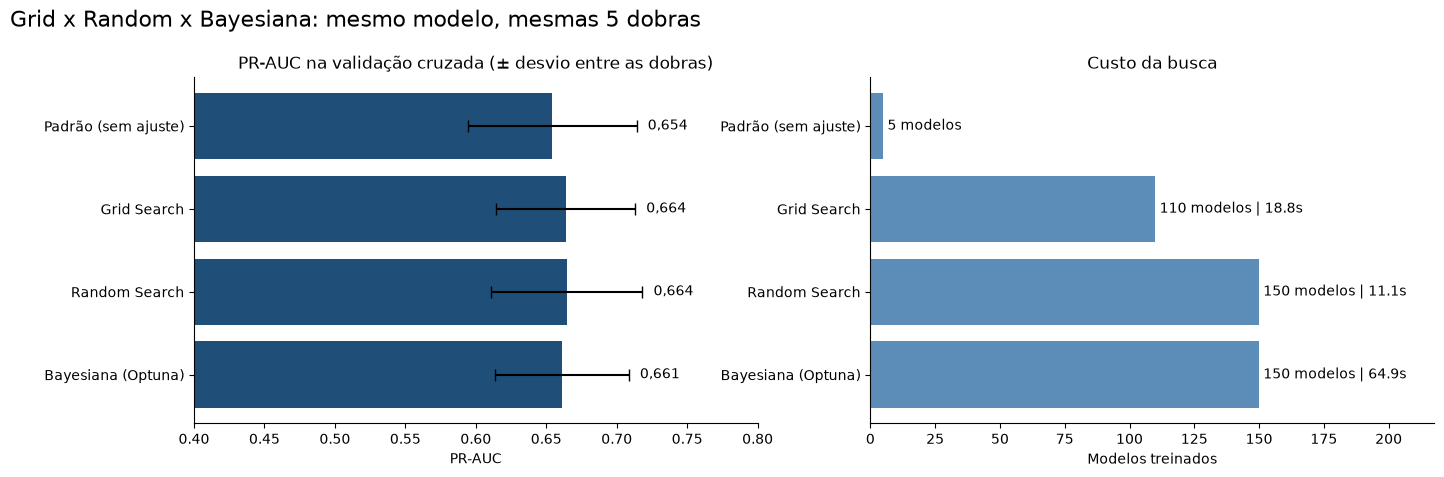

In [50]:
cv_padrao = cross_validate(clone(modelos[melhor_modelo]), Xtr, y_treino, cv=cv_busca, scoring='average_precision', n_jobs=N_JOBS,
                           return_train_score=True)
parametros_por_metodo = {'Grid Search': grid.best_params_, 'Random Search': busca.best_params_,
                         'Bayesiana (Optuna)': espacos_optuna[melhor_modelo](estudo.best_trial)}
estimadores = {'Padrão (sem ajuste)': modelos[melhor_modelo], 'Grid Search': grid.best_estimator_, 'Random Search': busca.best_estimator_,
               'Bayesiana (Optuna)': clone(modelos[melhor_modelo]).set_params(**parametros_por_metodo['Bayesiana (Optuna)']).fit(Xtr, y_treino)}
linhas = [{'Método': 'Padrão (sem ajuste)', 'Melhor score (CV)': cv_padrao['test_score'].mean(), 'Desvio entre dobras': cv_padrao['test_score'].std(),
           'Score no treino': cv_padrao['train_score'].mean(), 'Combinações testadas': 1, 'Modelos treinados': cv_busca.get_n_splits(),
           'Tempo (s)': np.nan, 'Melhores hiperparâmetros': 'padrão do scikit-learn (C = 1, L2)'},
          resumo_sklearn('Grid Search', grid, tempo_grid), resumo_sklearn('Random Search', busca, tempo_random),
          resumo_optuna('Bayesiana (Optuna)', estudo, tempo_optuna, cv_busca.get_n_splits())]
comparacao_busca = pd.DataFrame(linhas).set_index('Método').rename(columns={
    'Melhor score (CV)': 'PR-AUC CV', 'Desvio entre dobras': 'desvio', 'Score no treino': 'PR-AUC treino'})
comparacao_busca['sobreajuste'] = comparacao_busca['PR-AUC treino'] - comparacao_busca['PR-AUC CV']
comparacao_busca['PR-AUC validação'] = [average_precision_score(y_validacao, m.predict_proba(Xva)[:, 1]) for m in estimadores.values()]
colunas_tabela = ['PR-AUC CV', 'desvio', 'PR-AUC treino', 'sobreajuste', 'PR-AUC validação', 'Combinações testadas', 'Modelos treinados', 'Tempo (s)']
display(comparacao_busca[colunas_tabela].style.format({c: '{:.4f}' for c in colunas_tabela[:5]} | {'Tempo (s)': '{:.1f}'}, na_rep='–')
        .highlight_max(subset=['PR-AUC CV'], color='#C8E6C9'))
for metodo, parametros in comparacao_busca['Melhores hiperparâmetros'].items():
    print(f'{metodo:20s}', {k: round(float(v), 4) if isinstance(v, float) else v for k, v in parametros.items()} if isinstance(parametros, dict) else parametros)

# Escolha: maior PR-AUC da validação cruzada, com a regra do desvio entre as dobras
ajustados = comparacao_busca.drop('Padrão (sem ajuste)')
vencedor = ajustados['PR-AUC CV'].idxmax()
ganho_sobre_random = ajustados.loc[vencedor, 'PR-AUC CV'] - ajustados.loc['Random Search', 'PR-AUC CV']
metodo_escolhido = vencedor if (vencedor == 'Random Search' or ganho_sobre_random >= ajustados.loc[vencedor, 'desvio']) else 'Random Search'
melhor_estimador = estimadores[metodo_escolhido]
melhor_score_cv = float(comparacao_busca.loc[metodo_escolhido, 'PR-AUC CV'])
melhores_params = parametros_por_metodo[metodo_escolhido]
print(f'\nMaior PR-AUC na validação cruzada: {vencedor} ({ganho_sobre_random:+.4f} sobre o Random Search)')
print(f'✅ Método escolhido: {metodo_escolhido}')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
ordem = comparacao_busca.index
axs[0].barh(ordem, comparacao_busca['PR-AUC CV'], xerr=comparacao_busca['desvio'], color=COR_PRINCIPAL, capsize=4)
axs[0].bar_label(axs[0].containers[1], labels=[f'{v:.3f}'.replace('.', ',') for v in comparacao_busca['PR-AUC CV']], padding=8)
axs[0].set(xlim=(0.4, 0.8), title='PR-AUC na validação cruzada (± desvio entre as dobras)', xlabel='PR-AUC')
axs[1].barh(ordem, comparacao_busca['Modelos treinados'], color=COR_FICOU)
axs[1].bar_label(axs[1].containers[0], labels=[f'{n} modelos' + (f' | {t:.1f}s' if t == t else '') for n, t in
                                               zip(comparacao_busca['Modelos treinados'], comparacao_busca['Tempo (s)'])], padding=3)
axs[1].set(title='Custo da busca', xlabel='Modelos treinados', xlim=(0, comparacao_busca['Modelos treinados'].max() * 1.45))
for ax in axs:
    ax.invert_yaxis()
sns.despine()
titulo('Grid x Random x Bayesiana: mesmo modelo, mesmas 5 dobras')
salvar('Comparacao dos metodos de busca')
plt.show()

📌 **Nota**

| Método | PR-AUC CV | Sobreajuste (treino - CV) | PR-AUC validação | Custo |
|---|---|---|---|---|
| Padrão (C = 1, L2) | 0,654 ± 0,060 | 0,084 | 0,592 | – |
| Grid Search | 0,664 ± 0,049 | **0,064** | **0,604** | 110 modelos, 19 s |
| Random Search | **0,664 ± 0,054** | 0,069 | 0,600 | 150 modelos, **11 s** |
| Bayesiana (Optuna) | 0,661 ± 0,047 | 0,068 | 0,596 | 150 modelos, 65 s |

- 🔎 Os três métodos melhoram o modelo padrão (de **+0,007 a +0,010** de PR-AUC) e chegam à **mesma resposta**: regularização L2 **mais forte** que a padrão (C entre 0,1 e 0,2, contra 1).
- 🔎 A diferença entre eles (**0,003**) é cerca de **1/20 do desvio entre as dobras** (~0,05): empate técnico. Na validação, a ordem muda (Grid 0,604, Random 0,600, Bayesiana 0,596), outro sinal de que as diferenças são ruído.
- 🔎 O ajuste também reduz o **sobreajuste**, de **0,084** para **0,064 a 0,069**.
- ✅ **Decisão:** o Random Search tem a maior PR-AUC da validação cruzada e **continua**. O modelo, o limiar de 0,34 e o app não mudam.
- 💡 **Lição:** com um espaço pequeno, os três métodos empatam e o mais simples basta. A Bayesiana não é automaticamente melhor: aqui ela foi a mais lenta e ficou levemente abaixo.

### 7.5. Modelo ajustado

AMOSTRA: GABARITO x PROBABILIDADE x PREVISÃO (limiar = 0.50)


,Gabarito,Probabilidade de sair,Previsão da máquina
0,0,0.137,0
1,0,0.071,0
2,0,0.001,0
3,0,0.006,0
4,0,0.019,0
5,0,0.036,0
6,0,0.283,0
7,0,0.067,0


MÉTRICAS DE VALIDAÇÃO: Regressão Logística ajustado
Acurácia                 0.8912
Precisão                 0.7778
Recall (Sensibilidade)   0.4468
F1-Score                 0.5676
AUC-ROC                  0.8099
PR-AUC                   0.6001
                         (sorteio: PR-AUC = 0.1599, AUC-ROC = 0,50)

SOBREAJUSTE (treino x validação):
  PR-AUC: treino 0.7303 | validação 0.6001 | diferença +0.1302

              precision    recall  f1-score   support

   Ficou (0)      0.903     0.976     0.938       247
    Saiu (1)      0.778     0.447     0.568        47

    accuracy                          0.891       294
   macro avg      0.840     0.711     0.753       294
weighted avg      0.883     0.891     0.879       294



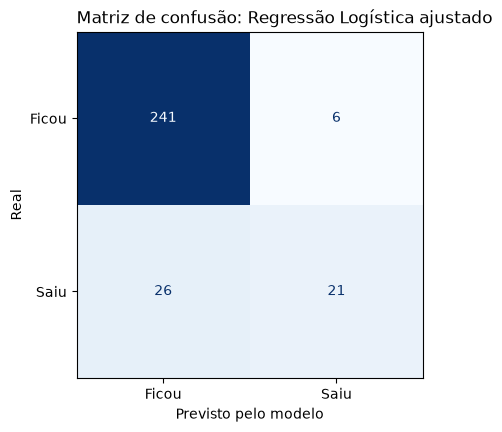

,Precisão,Recall (Sensibilidade),F1-Score,PR-AUC,PR-AUC CV (5 dobras do treino),Falsos Positivos,Falsos Negativos
Regressão Logística (padrão),0.724,0.447,0.553,0.592,0.654,8.000,26.000
Regressão Logística ajustado,0.778,0.447,0.568,0.600,0.664,6.000,26.000


✅ Modelo escolhido pela validação cruzada (mesmas 5 dobras da busca): Regressão Logística ajustado


In [51]:
modelo_ajustado = melhor_estimador   # do método escolhido no item 7.4
metricas_ajustado, proba_ajustado = relatorio_validacao(f'{melhor_modelo} ajustado', modelo_ajustado, Xtr, y_treino, Xva,
                                                         y_validacao, nome_arquivo='Matriz modelo ajustado')
pr_auc_padrao_cv = cross_val_score(clone(modelos[melhor_modelo]), Xtr, y_treino, cv=cv_busca, scoring='average_precision').mean()
usar_ajustado = melhor_score_cv > pr_auc_padrao_cv
modelo_escolhido = modelo_ajustado if usar_ajustado else modelos[melhor_modelo]
proba_escolhido = proba_ajustado if usar_ajustado else probas_validacao[melhor_modelo]
nome_escolhido = f'{melhor_modelo} ajustado' if usar_ajustado else f'{melhor_modelo} (hiperparâmetros padrão)'

display(pd.DataFrame({f'{melhor_modelo} (padrão)': {**metricas_validacao[melhor_modelo], 'PR-AUC CV (5 dobras do treino)': pr_auc_padrao_cv},
                      f'{melhor_modelo} ajustado': {**metricas_ajustado, 'PR-AUC CV (5 dobras do treino)': melhor_score_cv}}).T[
    ['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC', 'PR-AUC CV (5 dobras do treino)', 'Falsos Positivos', 'Falsos Negativos']].round(4))
print(f'✅ Modelo escolhido pela validação cruzada (mesmas 5 dobras da busca): {nome_escolhido}')

📌 **Nota**
- 🔎 O ajuste melhora um pouco: PR-AUC de **0,592 → 0,600** na validação e **0,654 → 0,664** na validação cruzada do treino. Com o limiar de 0,50, os alarmes falsos caem de **8** para **6**, com as mesmas 21 saídas encontradas.
- ✅ **Decisão:** usar o modelo **ajustado**, escolhido pela validação cruzada.

### 7.6. Modelo final

O modelo final é um **clone** do modelo escolhido, treinado de novo com **treino + validação** (80% da base). O teste é usado aqui pela primeira vez, só para registrar o resultado com o limiar padrão; o limiar definitivo vem da validação (item 8).

In [52]:
modelo_final = clone(modelo_escolhido).fit(X_treino_val[FEATURES], y_treino_val)
prob_teste = modelo_final.predict_proba(X_teste[FEATURES])[:, 1]
metricas_teste_05 = calcular_metricas_completas(y_teste, (prob_teste >= 0.5).astype(int), prob_teste)
metricas_escolhido = metricas_ajustado if usar_ajustado else metricas_validacao[melhor_modelo]
pd.DataFrame({f'Validação ({nome_escolhido})': metricas_escolhido, 'Teste (modelo final, limiar 0,5)': metricas_teste_05}).loc[
    ['Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'AUC-ROC', 'PR-AUC', 'Verdadeiros Positivos', 'Falsos Negativos',
     'Falsos Positivos']].round(3)

,Validação (Regressão Logística ajustado),"Teste (modelo final, limiar 0,5)"
Precisão,0.778,0.652
Recall (Sensibilidade),0.447,0.319
F1-Score,0.568,0.429
AUC-ROC,0.810,0.806
PR-AUC,0.600,0.587
Verdadeiros Positivos,21.000,15.000
Falsos Negativos,26.000,32.000
Falsos Positivos,6.000,8.000


📌 **Nota**
- 🔎 No teste, com o limiar de 0,50, a PR-AUC é de **0,587** e a AUC-ROC de **0,81**, perto da validação (**0,600** e **0,81**): **não houve sobreajuste** às escolhas feitas.
- ⚠️ O recall com 0,50 é baixo (**32%**: 15 de 47 saídas). É por isso que o limiar precisa ser escolhido pelo custo (item 8).

## 8 - Otimização de limiar e calibração

O modelo dá uma **probabilidade**; o **limiar** decide a partir de qual probabilidade o RH chama a pessoa para conversar. Tudo aqui usa a **validação** (o modelo escolhido, treinado só no treino); o teste só recebe o limiar já escolhido.

### 8.1. O efeito do limiar

In [53]:
linhas = []
for corte in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    abordado = proba_escolhido >= corte
    linhas.append({'Limiar': corte, 'Pessoas abordadas': int(abordado.sum()), 'Saídas encontradas': int((abordado & (y_validacao == 1)).sum()),
                   'Abordagens desnecessárias': int((abordado & (y_validacao == 0)).sum()),
                   'Precisão': precision_score(y_validacao, abordado, zero_division=0), 'Recall': recall_score(y_validacao, abordado)})
pd.DataFrame(linhas).set_index('Limiar').round(3)

,Pessoas abordadas,Saídas encontradas,Abordagens desnecessárias,Precisão,Recall
Limiar,,,,,
0.200,78,31,47,0.397,0.660
0.300,52,26,26,0.500,0.553
0.400,36,24,12,0.667,0.511
0.500,27,21,6,0.778,0.447
0.600,18,14,4,0.778,0.298
0.700,15,13,2,0.867,0.277
0.800,7,6,1,0.857,0.128


### 8.2. Escolhendo o limiar

| Critério | Como escolhe |
|---|---|
| **F1 máximo** | O melhor equilíbrio entre precisão e recall |
| **Custo mínimo** | Cada saída **não prevista** custa a reposição (**US$ 7.645**); cada pessoa **abordada** custa uma ação de retenção (**US$ 1.529**, 1/5 da reposição). Premissa simplificadora: a conversa evita a saída |
| **Meta de recall (70%)** | O maior limiar que ainda encontra 70% das saídas |

,Limiar,Precisão,Recall,F1,Abordados,Custo total (US$),Economia vs. sem modelo
"Padrão (0,50)",0.50,0.778,0.447,0.568,27,"US$ 240,053",33.2%
F1 máximo,0.41,0.706,0.511,0.593,34,"US$ 227,821",36.6%
Custo mínimo (1:5),0.34,0.619,0.553,0.584,42,"US$ 224,763",37.4%
Meta de recall (70%),0.18,0.388,0.702,0.500,85,"US$ 236,995",34.0%


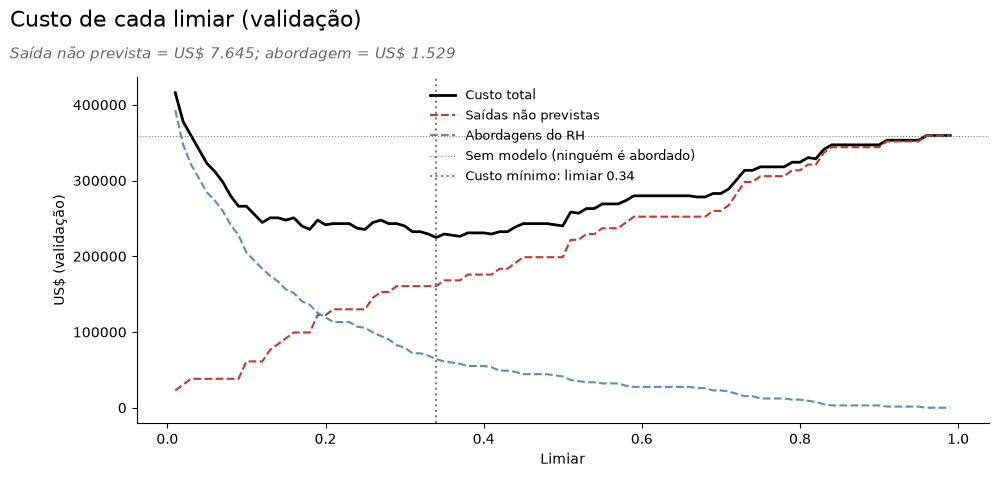

✅ Limiar escolhido (custo mínimo na validação): 0.34


In [54]:
limiar_f1, f1_max = limiar_otimo_f1(y_validacao, proba_escolhido)
custos = curva_custo(y_validacao, proba_escolhido, CUSTO_REPOSICAO, CUSTO_ABORDAGEM)
limiar_custo = float(custos.loc[custos['Custo total'].idxmin(), 'Limiar'])
_, recall_curva, limiares_curva = precision_recall_curve(y_validacao, proba_escolhido)
limiar_meta = float(limiares_curva[recall_curva[:-1] >= 0.70].max())

resumo_limiares = {}
for nome, corte in [('Padrão (0,50)', 0.5), ('F1 máximo', limiar_f1), (f'Custo mínimo (1:{PROPORCAO_CUSTO})', limiar_custo),
                    ('Meta de recall (70%)', limiar_meta)]:
    abordado = proba_escolhido >= corte
    r = resumo_custo(y_validacao, abordado, CUSTO_REPOSICAO, CUSTO_ABORDAGEM)
    resumo_limiares[nome] = {'Limiar': corte, 'Precisão': precision_score(y_validacao, abordado), 'Recall': recall_score(y_validacao, abordado),
                             'F1': f1_score(y_validacao, abordado), 'Abordados': r['Abordados'], 'Custo total (US$)': r['Custo com o modelo'],
                             'Economia vs. sem modelo': r['Economia (%)']}
display(pd.DataFrame(resumo_limiares).T.style.format({'Limiar': '{:.2f}', 'Precisão': '{:.3f}', 'Recall': '{:.3f}', 'F1': '{:.3f}',
                                                      'Abordados': '{:.0f}', 'Custo total (US$)': 'US$ {:,.0f}',
                                                      'Economia vs. sem modelo': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(custos['Limiar'], custos['Custo total'], color='black', lw=2, label='Custo total')
ax.plot(custos['Limiar'], custos['Custo das saídas não previstas'], color=COR_SAIU, ls='--', label='Saídas não previstas')
ax.plot(custos['Limiar'], custos['Custo das abordagens'], color=COR_FICOU, ls='--', label='Abordagens do RH')
ax.axhline(y_validacao.sum() * CUSTO_REPOSICAO, color='grey', lw=0.8, ls=':', label='Sem modelo (ninguém é abordado)')
ax.axvline(limiar_custo, color='grey', ls=':', label=f'Custo mínimo: limiar {limiar_custo:.2f}')
ax.set(xlabel='Limiar', ylabel='US$ (validação)')
ax.legend(frameon=False, fontsize=9)
sns.despine()
titulo('Custo de cada limiar (validação)', f'Saída não prevista = {dolares(CUSTO_REPOSICAO)}; abordagem = {dolares(CUSTO_ABORDAGEM)}')
salvar('Curva de custo')
plt.show()

limiar = limiar_custo
print(f'✅ Limiar escolhido (custo mínimo na validação): {limiar:.2f}')

📌 **Nota**
- 🔎 O limiar de **menor custo** é **0,34**: o RH aborda **42** pessoas da validação, encontra **55%** das saídas, com **62%** de precisão, e o custo cai **37,4%** em relação a não ter modelo.
- 🔎 O limiar de **F1 máximo** (**0,41**) dá um custo parecido (**36,6%** de economia). O padrão de 0,50 economiza **33,2%**, e a meta de 70% de recall (limiar **0,18**) aborda **85** pessoas e economiza **34,0%**.
- 💡 A curva mostra o equilíbrio: com limiar baixo, o custo das abordagens dispara; com limiar alto, sobram saídas não previstas.
- ✅ **Decisão:** limiar de **0,34**, escolhido **na validação**.

In [55]:
# Sensibilidade: e se a abordagem custar mais ou menos, em proporção à reposição?
sensibilidade = {}
for k in [2, 3, 5, 10, 20]:
    tabela = curva_custo(y_validacao, proba_escolhido, CUSTO_REPOSICAO, CUSTO_REPOSICAO / k)
    melhor = tabela.loc[tabela['Custo total'].idxmin()]
    sensibilidade[f'reposição = {k}x a abordagem'] = {'Limiar de custo mínimo': melhor['Limiar'], 'Abordados': int(melhor['Abordados']),
                                                        'Saídas encontradas': int(melhor['Saídas previstas'])}
pd.DataFrame(sensibilidade).T

,Limiar de custo mínimo,Abordados,Saídas encontradas
reposição = 2x a abordagem,0.500,27.000,21.000
reposição = 3x a abordagem,0.370,38.000,25.000
reposição = 5x a abordagem,0.340,42.000,26.000
reposição = 10x a abordagem,0.090,149.000,42.000
reposição = 20x a abordagem,0.090,149.000,42.000


📌 **Nota**
- 🔎 O limiar depende da premissa de custo. Se repor custar só **2x** a abordagem, o melhor é abordar **27** pessoas (limiar **0,50**). Com **3x** ou **5x**, o limiar fica entre **0,37** e **0,34**.
- 🔎 Se repor custar **10x** a abordagem (uma conversa barata), vale abordar **149** das 294 pessoas (limiar **0,09**) para encontrar **42** das 47 saídas.
- 💡 **Para o RH:** a premissa de custo é uma decisão de negócio, não técnica. O app mostra o limiar, e a ficha do modelo registra a premissa usada.

### 8.3. Aplicando o limiar escolhido no teste

In [56]:
previsto_teste = (prob_teste >= limiar).astype(int)
linhas = {}
for nome, corte in [('Limiar padrão (0,50)', 0.5), (f'Limiar escolhido ({limiar:.2f})', limiar)]:
    abordado = prob_teste >= corte
    r = resumo_custo(y_teste, abordado, CUSTO_REPOSICAO, CUSTO_ABORDAGEM)
    linhas[nome] = {'Precisão': precision_score(y_teste, abordado), 'Recall': recall_score(y_teste, abordado), 'F1': f1_score(y_teste, abordado),
                    'Saídas encontradas': f"{r['Saídas previstas']} de {r['Saídas no grupo']}", 'Abordados': r['Abordados'],
                    'Economia vs. sem modelo': f"{r['Economia (%)']:.1%}"}
pd.DataFrame(linhas).T

,Precisão,Recall,F1,Saídas encontradas,Abordados,Economia vs. sem modelo
"Limiar padrão (0,50)",0.652,0.319,0.429,15 de 47,23,22.1%
Limiar escolhido (0.34),0.605,0.489,0.541,23 de 47,38,32.8%


### 8.4. Calibração

Uma probabilidade **calibrada** significa o que diz: entre as pessoas com 30% de risco, cerca de 30% saem. Comparamos, no teste, a probabilidade média de cada faixa com a taxa real de saída.

In [57]:
faixas = pd.cut(prob_teste, bins=[0, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0], include_lowest=True)
calibracao = (pd.DataFrame({'probabilidade': prob_teste, 'real': y_teste.values, 'faixa': faixas})
              .groupby('faixa', observed=True).agg(pessoas=('real', 'size'), probabilidade_media=('probabilidade', 'mean'),
                                                   taxa_real_de_saida=('real', 'mean')))
display(calibracao.style.format({'probabilidade_media': '{:.1%}', 'taxa_real_de_saida': '{:.1%}'}))
print(f'Brier score (erro médio das probabilidades; menor é melhor): {brier_score_loss(y_teste, prob_teste):.4f}'
      f' | modelo que chuta: {brier_score_loss(y_teste, np.full(len(y_teste), y_treino.mean())):.4f}')

,pessoas,probabilidade_media,taxa_real_de_saida
faixa,,,
"(-0.001, 0.1]",161,3.6%,5.0%
"(0.1, 0.2]",58,14.0%,13.8%
"(0.2, 0.35]",37,26.7%,21.6%
"(0.35, 0.5]",15,43.3%,53.3%
"(0.5, 0.7]",14,59.4%,42.9%
"(0.7, 1.0]",9,81.2%,100.0%


Brier score (erro médio das probabilidades; menor é melhor): 0.0990 | modelo que chuta: 0.1343


📌 **Nota**
- 🔎 As probabilidades são **bem calibradas** nas faixas com mais gente: quem recebe de 10% a 20% de risco sai **13,8%** das vezes (previsto: **14,0%**); de 0% a 10%, sai **5,0%** (previsto: **3,6%**).
- 🔎 Nas faixas altas, com poucas pessoas (**9** a **15**), há oscilação: de 50% a 70% previstos, saem **42,9%**; acima de 70%, **todos** saíram.
- 🔎 O erro médio das probabilidades (Brier) é de **0,099**, contra **0,134** de quem chuta. Na primeira execução, com peso da classe, ele era **pior** que o chute (item 4.2).

## 9 - Teste anti-vazamento

A base não tem variáveis que existam só **depois** da saída (como "data de desligamento" ou "motivo da saída"). O vazamento da versão original estava na **forma de avaliar**. Reproduzimos os dois problemas para medir o quanto eles inflam os números:
1. **Avaliar o modelo em dados que ele já viu:** a v1 treinou os modelos "ajustados" em treino + validação e mediu na própria validação (Random Forest com 100% em tudo).
2. **Comparar a acurácia com nada:** a v1 divulgou 84% de acurácia, que é o mesmo acerto de quem chuta que todo mundo fica.

In [58]:
# 1) Random Forest treinado em treino + validação e avaliado na própria validação (como na v1)
rf_vazado = clone(modelos['Random Forest']).fit(X_treino_val[FEATURES], y_treino_val)
proba_vazada = rf_vazado.predict_proba(Xva)[:, 1]
proba_honesta = modelos['Random Forest'].predict_proba(Xva)[:, 1]
vazamento = pd.DataFrame({
    'Random Forest, avaliação honesta (validação nunca vista)': calcular_metricas_completas(y_validacao, (proba_honesta >= 0.5).astype(int), proba_honesta),
    'Random Forest, avaliação com vazamento (validação já vista)': calcular_metricas_completas(y_validacao, (proba_vazada >= 0.5).astype(int), proba_vazada),
}).T[['Acurácia', 'Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC']]
display(vazamento.round(3))

# 2) Acurácia: modelo final x chutar "fica" para todos, no teste
print(f"Acurácia no teste: modelo final (limiar {limiar:.2f}) {np.mean(previsto_teste == y_teste):.1%} | "
      f"chutar 'todo mundo fica' {1 - y_teste.mean():.1%} | modelo da v1 84,35%")

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,PR-AUC
"Random Forest, avaliação honesta (validação nunca vista)",0.874,0.750,0.319,0.448,0.555
"Random Forest, avaliação com vazamento (validação já vista)",1.000,1.000,1.000,1.000,1.000


Acurácia no teste: modelo final (limiar 0.34) 86.7% | chutar 'todo mundo fica' 84.0% | modelo da v1 84,35%


### 🛡️ Resumo: houve vazamento? Foi resolvido?

- 🔎 Avaliado em dados que **já tinha visto**, o Random Forest acerta **100%** em tudo (acurácia, precisão, recall, F1 e PR-AUC = 1,000). Avaliado de forma honesta, a PR-AUC é **0,555** e o recall, **32%**. Esse era o "Random Forest com 100%" da versão original.
- 🔎 A acurácia do modelo final no teste é de **86,7%**, contra **84,0%** de quem chuta que todo mundo fica. Os **84,35%** da v1 eram, na prática, o acerto do chute.
- ✅ **Resolvido:** o teste só foi usado no fim, as transformações ficam num `Pipeline` ajustado no treino, e a métrica principal é a da classe "saiu".

# FASE 04: AVALIAÇÃO

## 1 - Avaliando a Máquina Preditiva

,Acurácia,Precisão,Recall (Sensibilidade),F1-Score,AUC-ROC,PR-AUC,Especificidade,Verdadeiros Positivos,Verdadeiros Negativos,Falsos Positivos,Falsos Negativos
Teste (limiar 0.34),0.867,0.605,0.489,0.541,0.806,0.587,0.939,23.000,232.000,15.000,24.000


              precision    recall  f1-score   support

   Ficou (0)      0.906     0.939     0.922       247
    Saiu (1)      0.605     0.489     0.541        47

    accuracy                          0.867       294
   macro avg      0.756     0.714     0.732       294
weighted avg      0.858     0.867     0.862       294



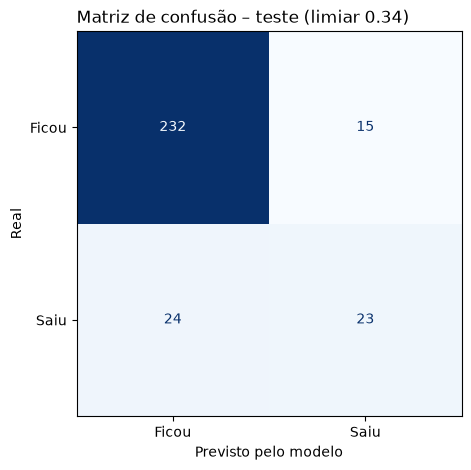

,Custo sem modelo,Custo com o modelo,Economia,Economia (%),Abordados,Saídas previstas,Saídas no grupo
Teste,"US$ 359,315","US$ 241,582","US$ 117,733",32.8%,38.000000,23.000000,47.000000


In [59]:
metricas_teste = calcular_metricas_completas(y_teste, previsto_teste, prob_teste)
display(pd.Series(metricas_teste).to_frame(f'Teste (limiar {limiar:.2f})').T.round(4))
print(classification_report(y_teste, previsto_teste, target_names=ROTULOS, digits=3))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, previsto_teste, display_labels=['Ficou', 'Saiu'], cmap='Blues', colorbar=False, ax=ax)
ax.set(xlabel='Previsto pelo modelo', ylabel='Real')
plt.title(f'Matriz de confusão – teste (limiar {limiar:.2f})', fontsize=12, loc='left')
salvar('Matriz de confusao teste')
plt.show()

custo_teste = resumo_custo(y_teste, previsto_teste, CUSTO_REPOSICAO, CUSTO_ABORDAGEM)
pd.Series(custo_teste).to_frame('Teste').T.style.format({'Custo sem modelo': 'US$ {:,.0f}', 'Custo com o modelo': 'US$ {:,.0f}',
                                                         'Economia': 'US$ {:,.0f}', 'Economia (%)': '{:.1%}'})

📌 **Nota**
- 🔎 No teste (**294** funcionários que o modelo nunca viu), com o limiar de **0,34**, o RH aborda **38** pessoas e encontra **23** das **47** saídas (recall de **49%**). Das pessoas abordadas, **61%** saem de fato (precisão), contra **16%** num sorteio.
- 🔎 PR-AUC de **0,587** e AUC-ROC de **0,81**. A acurácia é **86,7%**, mas ela importa pouco aqui.
- 💰 **Em dólares:** sem modelo, as 47 saídas custariam **US$ 359.315** em reposição. Com o modelo, o custo (saídas não previstas + abordagens) cai para **US$ 241.582**: economia de **US$ 117.733** (**32,8%**), na premissa de que a conversa evita a saída.
- 🔎 **Comparação com a v1** (mesmo tamanho de teste): precisão de **61%** contra **51%**, recall de **49%** contra **53%** e F1 de **0,54** contra **0,52**. Os números parecem próximos, mas os da v1 vinham de transformações ajustadas no próprio teste.

#### Curvas ROC e Precision-Recall

Quase todo classificador devolve uma **probabilidade**, não um "sim" ou "não"; o limiar é que transforma uma na outra. As duas curvas mostram o modelo em **todos os limiares** ao mesmo tempo, o que permite comparar modelos sem depender de um corte:

| Curva | Eixos | Leitura |
|---|---|---|
| **ROC** | recall x taxa de falsos positivos (quem fica e é abordado) | AUC = 1: perfeito; 0,5: sorteio. Pode parecer boa mesmo com poucos acertos na classe rara |
| **Precision-Recall** | precisão x recall | mais informativa com classes desbalanceadas: o sorteio fica na taxa de saída (16%), não em 0,5 |

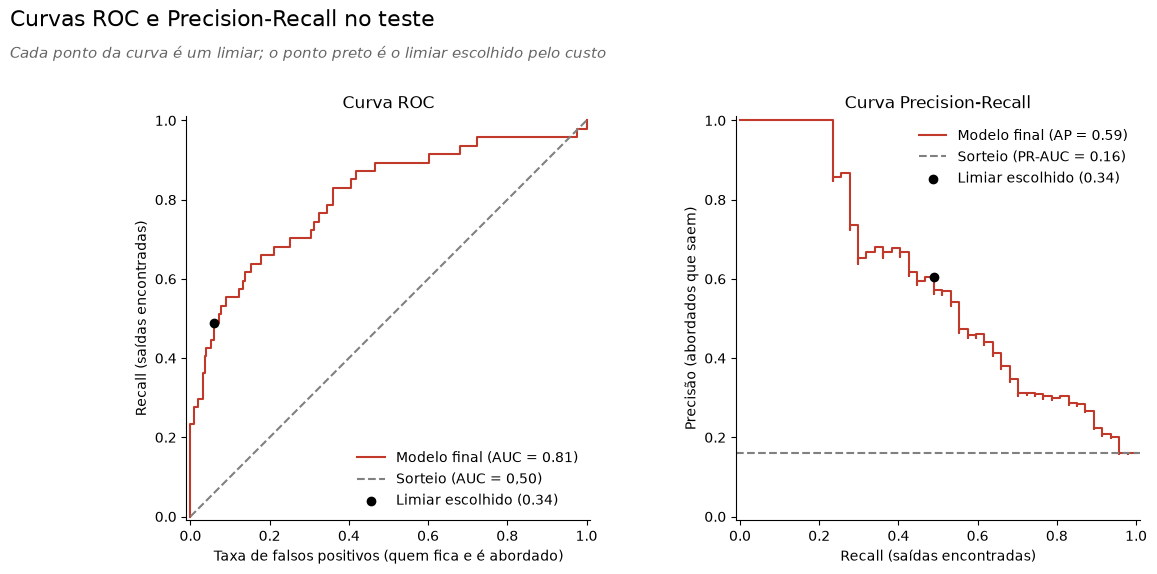

No limiar 0.34: recall 48.9%, precisão 60.5%, taxa de falsos positivos 6.1%


In [60]:
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
taxa_fp = ((previsto_teste == 1) & (y_teste.values == 0)).sum() / (y_teste == 0).sum()
recall_limiar, precisao_limiar = recall_score(y_teste, previsto_teste), precision_score(y_teste, previsto_teste)

RocCurveDisplay.from_predictions(y_teste, prob_teste, ax=axs[0], name='Modelo final', curve_kwargs={'color': COR_SAIU})
axs[0].plot([0, 1], [0, 1], color='grey', ls='--', label='Sorteio (AUC = 0,50)')
axs[0].scatter(taxa_fp, recall_limiar, color='black', zorder=5, label=f'Limiar escolhido ({limiar:.2f})')
axs[0].set(title='Curva ROC', xlabel='Taxa de falsos positivos (quem fica e é abordado)', ylabel='Recall (saídas encontradas)')

PrecisionRecallDisplay.from_predictions(y_teste, prob_teste, ax=axs[1], name='Modelo final', curve_kwargs={'color': COR_SAIU})
axs[1].axhline(y_teste.mean(), color='grey', ls='--', label=f'Sorteio (PR-AUC = {y_teste.mean():.2f})')
axs[1].scatter(recall_limiar, precisao_limiar, color='black', zorder=5, label=f'Limiar escolhido ({limiar:.2f})')
axs[1].set(title='Curva Precision-Recall', xlabel='Recall (saídas encontradas)', ylabel='Precisão (abordados que saem)')
for ax in axs:
    ax.legend(frameon=False, loc='lower right' if ax is axs[0] else 'upper right')
sns.despine()
fig.subplots_adjust(top=0.85)   # espaço para o título e o subtítulo acima dos gráficos
titulo('Curvas ROC e Precision-Recall no teste', 'Cada ponto da curva é um limiar; o ponto preto é o limiar escolhido pelo custo')
fig.subplots_adjust(top=0.85 - 0.4 / fig.get_figheight())   # desce os gráficos: espaço para o título de cada curva
salvar('Curvas ROC e PR teste')
plt.show()
print(f'No limiar {limiar:.2f}: recall {recall_limiar:.1%}, precisão {precisao_limiar:.1%}, taxa de falsos positivos {taxa_fp:.1%}')

📌 **Nota**
- 🔎 **AUC-ROC de 0,81** e **PR-AUC (AP) de 0,59**, contra **0,50** e **0,16** do sorteio.
- 🔎 No limiar de **0,34**, o modelo encontra **48,9%** das saídas (recall), com **60,5%** de precisão, abordando só **6,1%** de quem fica. Na ROC, o ponto parece ótimo (canto superior esquerdo); a curva Precision-Recall mostra o preço real: de cada 10 pessoas abordadas, 6 saem.
- 🔎 A precisão é de **100%** nas primeiras ~23% saídas (as de maior risco) e depois cai: para encontrar **80%** das saídas, a precisão desce para cerca de **30%**. É essa troca que a curva de custo do item 8 converte em dólares.
- 💡 Com a classe rara (16%), a **Precision-Recall** é a curva honesta; a ROC serve para comparar modelos sem fixar um limiar.

### 1.1. Quão certos são esses números?

Com só **47 saídas** no teste, poucas pessoas mudam muito as métricas. O **bootstrap estratificado** sorteia, com reposição, 1.000 versões do teste (com as mesmas quantidades de saídas e permanências) e recalcula as métricas.

In [61]:
intervalos = bootstrap_metricas(y_teste, prob_teste, limiar, n=1000, semente=SEMENTE)
intervalos.style.format('{:.3f}')

,"IC 2,5%",mediana,"IC 97,5%"
PR-AUC,0.470,0.593,0.702
Recall,0.340,0.489,0.638
Precisão,0.468,0.606,0.744


📌 **Nota**
- 🔎 Com 95% de confiança, a PR-AUC no teste fica entre **0,47** e **0,70**, o recall entre **34%** e **64%**, e a precisão entre **47%** e **74%**.
- ⚠️ Os intervalos são **largos** porque há só 47 saídas no teste. Mesmo no pior cenário, a PR-AUC (**0,47**) fica muito acima do sorteio (**0,16**): o modelo **ordena bem** o risco, mas os números exatos têm incerteza.

## 2 - Previsto x observado

In [62]:
resultado_teste = X_teste[['idade', 'cargo', 'salario_mensal', 'hora_extra', 'anos_empresa', 'satisfacao_media']].assign(
    real=y_teste.values, probabilidade=prob_teste.round(3), previsto=previsto_teste)
print('✅ Saídas previstas (maiores probabilidades):')
display(resultado_teste.query('real == 1 and previsto == 1').sort_values('probabilidade', ascending=False).head(4))
print('❌ Saídas que o modelo não previu:')
display(resultado_teste.query('real == 1 and previsto == 0').sort_values('probabilidade').head(4))
print('⚠️ Abordagens desnecessárias (ficaram, mas o modelo apontou):')
display(resultado_teste.query('real == 0 and previsto == 1').sort_values('probabilidade', ascending=False).head(4))

✅ Saídas previstas (maiores probabilidades):


,idade,cargo,salario_mensal,hora_extra,anos_empresa,satisfacao_media,real,probabilidade,previsto
357,21,Representante de Vendas,2174,1,3,2.250,1,0.970,1
911,25,Representante de Vendas,1118,1,1,3.500,1,0.949,1
688,19,Representante de Vendas,2121,1,1,3.000,1,0.877,1
514,33,Cientista Pesquisador,3348,1,10,1.500,1,0.804,1


❌ Saídas que o modelo não previu:


,idade,cargo,salario_mensal,hora_extra,anos_empresa,satisfacao_media,real,probabilidade,previsto
1111,53,Diretor de Produção,10169,0,33,3.000,1,0.000,0
126,58,Representante de Saúde,10312,0,40,3.500,1,0.003,0
45,41,Diretor de Pesquisa,19545,0,22,3.000,1,0.026,0
700,58,Cientista Pesquisador,2479,0,1,2.750,1,0.031,0


⚠️ Abordagens desnecessárias (ficaram, mas o modelo apontou):


,idade,cargo,salario_mensal,hora_extra,anos_empresa,satisfacao_media,real,probabilidade,previsto
1391,38,Representante de Vendas,2858,0,1,1.250,0,0.642,1
1168,24,Cientista Pesquisador,3760,1,6,2.750,0,0.632,1
397,25,Executivo de Vendas,4487,1,5,2.750,0,0.606,1
301,18,Representante de Vendas,1200,0,0,2.750,0,0.606,1


In [63]:
# Tradução do erro por grupo: o modelo encontra as saídas igualmente em todos os grupos?
def por_grupo(coluna):
    tabela = resultado_teste.assign(grupo=X_teste[coluna].values).groupby('grupo', observed=True).agg(
        pessoas=('real', 'size'), saidas=('real', 'sum'), apontados=('previsto', 'sum'))
    acertos = resultado_teste.assign(grupo=X_teste[coluna].values).query('real == 1 and previsto == 1').groupby('grupo').size()
    tabela['saídas encontradas'] = acertos.reindex(tabela.index, fill_value=0)
    tabela['recall'] = tabela['saídas encontradas'] / tabela['saidas'].replace(0, np.nan)
    tabela['precisão'] = tabela['saídas encontradas'] / tabela['apontados'].replace(0, np.nan)
    return tabela

for coluna in ['departamento', 'hora_extra', 'genero']:
    print(f'POR {coluna.upper()}')
    display(por_grupo(coluna).style.format({'recall': '{:.0%}', 'precisão': '{:.0%}'}, na_rep='–'))

POR DEPARTAMENTO


,pessoas,saidas,apontados,saídas encontradas,recall,precisão
grupo,,,,,,
Pesquisa e Desenvolvimento,197,29,16,9,31%,56%
Recursos Humanos,15,2,2,0,0%,0%
Vendas,82,16,20,14,88%,70%


POR HORA_EXTRA


,pessoas,saidas,apontados,saídas encontradas,recall,precisão
grupo,,,,,,
0,218,17,11,4,24%,36%
1,76,30,27,19,63%,70%


POR GENERO


,pessoas,saidas,apontados,saídas encontradas,recall,precisão
grupo,,,,,,
Feminino,116,16,17,9,56%,53%
Masculino,178,31,21,14,45%,67%


📌 **Nota**
- ✅ As saídas com maior probabilidade são o retrato da H8: **representantes de vendas** de **19 a 25 anos**, com **hora extra** e salário baixo (probabilidades de **88%** a **97%**).
- ❌ As saídas que o modelo **não previu** são de **veteranos**: um diretor de produção de **53 anos** com **33 anos de casa**, uma pessoa de **58 anos** com **40 anos de casa**. Provavelmente **aposentadorias**, um tipo de saída que o modelo não tem como distinguir.
- ⚠️ As abordagens desnecessárias são de perfis parecidos com os de quem sai (jovens, vendas, hora extra), o que é esperado: o RH conversaria com pessoas de risco real.
- 🔎 **Por grupo:** o modelo encontra **88%** das saídas em **Vendas**, mas só **31%** em **Pesquisa e Desenvolvimento** (9 de 29). Entre quem faz **hora extra**, encontra **63%**; entre quem não faz, só **24%**.
- ⚖️ **Por gênero** (fora do modelo): recall de **56%** nas mulheres e **45%** nos homens, com precisão de **53%** e **67%**. Com só 16 e 31 saídas, a diferença está dentro da incerteza do teste: o modelo não favorece um grupo de forma clara.

#### ⚖️ Auditoria: o que muda com o gênero no modelo?

O gênero ficou fora do modelo por ser um atributo sensível (item 4.3 da Fase 03). Para registrar o efeito dessa decisão, treinamos o **mesmo modelo** com o gênero, pelo **mesmo processo** (limiar de menor custo escolhido na validação, retreino em treino + validação), e comparamos os dois no teste. Nada é escolhido aqui: é só uma conferência.

In [64]:
features_com_genero = FEATURES + ['genero']
modelo_genero = clone(modelo_escolhido).set_params(prep=preprocessador(features_com_genero))
proba_val_genero = modelo_genero.fit(X_treino[features_com_genero], y_treino).predict_proba(X_validacao[features_com_genero])[:, 1]
custos_genero = curva_custo(y_validacao, proba_val_genero, CUSTO_REPOSICAO, CUSTO_ABORDAGEM)
limiar_genero = float(custos_genero.loc[custos_genero['Custo total'].idxmin(), 'Limiar'])
modelo_genero = clone(modelo_genero).fit(X_treino_val[features_com_genero], y_treino_val)
prob_teste_genero = modelo_genero.predict_proba(X_teste[features_com_genero])[:, 1]
pr_auc_cv_genero = cross_val_score(clone(modelo_genero), X_treino[features_com_genero], y_treino, cv=cv_repetida,
                                   scoring='average_precision').mean()
pr_auc_cv_final = cross_val_score(clone(modelo_final), X_treino[FEATURES], y_treino, cv=cv_repetida,
                                  scoring='average_precision').mean()

auditoria = {}
for nome, proba, corte, pr_cv in [('Com gênero', prob_teste_genero, limiar_genero, pr_auc_cv_genero),
                                  ('Sem gênero (modelo final)', prob_teste, limiar, pr_auc_cv_final)]:
    abordado = proba >= corte
    r = resumo_custo(y_teste, abordado, CUSTO_REPOSICAO, CUSTO_ABORDAGEM)
    auditoria[nome] = {'PR-AUC (validação cruzada do treino)': pr_cv, 'PR-AUC (teste)': average_precision_score(y_teste, proba),
                       'Limiar (custo mínimo na validação)': corte, 'Saídas encontradas': f"{r['Saídas previstas']} de {r['Saídas no grupo']}",
                       'Abordados': r['Abordados'], 'Precisão': precision_score(y_teste, abordado), 'F1': f1_score(y_teste, abordado),
                       'Economia vs. sem modelo': r['Economia (%)']}
display(pd.DataFrame(auditoria).T)
nomes_genero = modelo_genero.named_steps['prep'].get_feature_names_out()
coef_genero = dict(zip(nomes_genero, np.exp(modelo_genero.named_steps['modelo'].coef_[0])))
razao_genero = coef_genero['genero_Feminino'] / coef_genero['genero_Masculino']
print(f"Com o gênero no modelo, a chance de sair de uma mulher é {razao_genero:.2f} vez a de um homem com todo o resto igual "
      f"({razao_genero - 1:+.0%})")

,PR-AUC (validação cruzada do treino),PR-AUC (teste),Limiar (custo mínimo na validação),Saídas encontradas,Abordados,Precisão,F1,Economia vs. sem modelo
Com gênero,0.650,0.598,0.380,21 de 47,34,0.618,0.519,0.302
Sem gênero (modelo final),0.647,0.587,0.340,23 de 47,38,0.605,0.541,0.328


Com o gênero no modelo, a chance de sair de uma mulher é 0.76 vez a de um homem com todo o resto igual (-24%)


📌 **Nota: retirar o gênero não piorou o modelo**

| | Com gênero | Sem gênero (modelo final) |
|---|---|---|
| PR-AUC (validação cruzada do treino) | 0,650 | **0,647** |
| PR-AUC (teste) | 0,598 | **0,587** |
| Limiar de menor custo (validação) | 0,38 | **0,34** |
| Saídas encontradas no teste | 21 de 47 (34 abordados) | **23 de 47** (38 abordados) |
| Precisão / F1 no teste | 61,8% / 0,519 | **60,5% / 0,541** |
| Economia vs. sem modelo | 30,2% | **32,8%** |

- 🔎 A qualidade da ordem de risco (PR-AUC) cai **muito pouco** sem o gênero (**0,003** na validação cruzada, **0,011** no teste), bem menos que a incerteza do teste (IC 95% de 0,47 a 0,70).
- 🔎 Com o limiar escolhido pelo custo, o modelo sem gênero encontra até **2 saídas a mais** e economiza um pouco mais. Nos dois sentidos, as diferenças são ruído de uma base pequena.
- ⚖️ Com o gênero, o modelo dava às mulheres uma chance de sair **24% menor** que a dos homens com todo o resto igual (0,76 vez), embora na base bruta os dois grupos saiam na mesma proporção (H13).
- ✅ **Decisão confirmada:** o gênero fica fora do modelo, sem custo real de desempenho.

## 3 - Quais variáveis mais influenciam o modelo?

hora_extra             0.232
anos_ultima_promocao   0.066
satisfacao_media       0.058
empresas_anteriores    0.043
envolvimento           0.039
satisfacao_trabalho    0.035
viagens                0.032
distancia_casa         0.031
anos_por_empresa       0.024
satisfacao_ambiente    0.018
anos_cargo_atual       0.017
treinamentos_ano       0.016


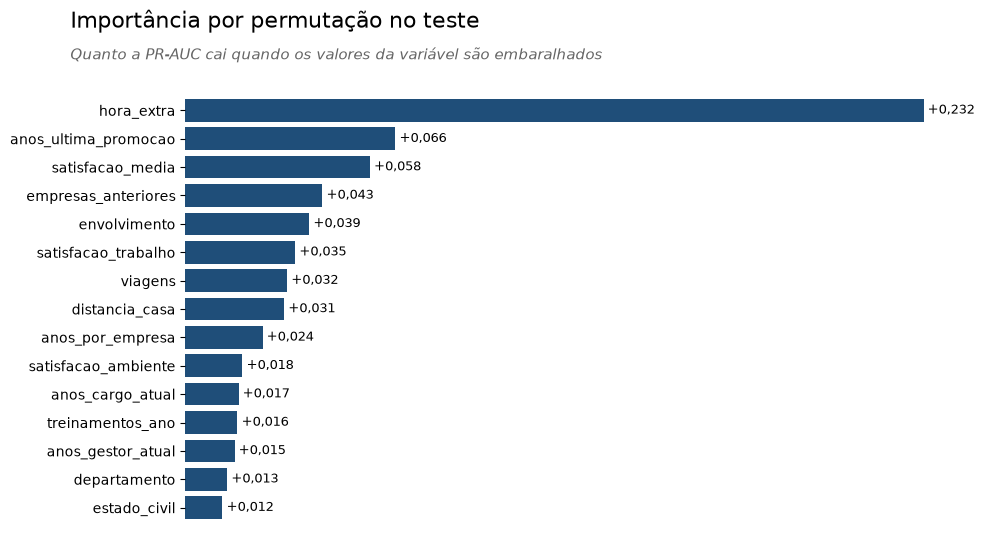

In [65]:
importancia_perm = permutation_importance(modelo_final, X_teste[FEATURES], y_teste, scoring='average_precision', n_repeats=20,
                                          random_state=SEMENTE, n_jobs=N_JOBS)
importancia_teste = pd.Series(importancia_perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print(importancia_teste.head(12).round(4).to_string())
plot_barras_h(importancia_teste.head(15), 'Importância por permutação no teste', 'Importancia por permutacao',
              subtitulo='Quanto a PR-AUC cai quando os valores da variável são embaralhados',
              formato=lambda v: f'{v:+.3f}'.replace('.', ','))

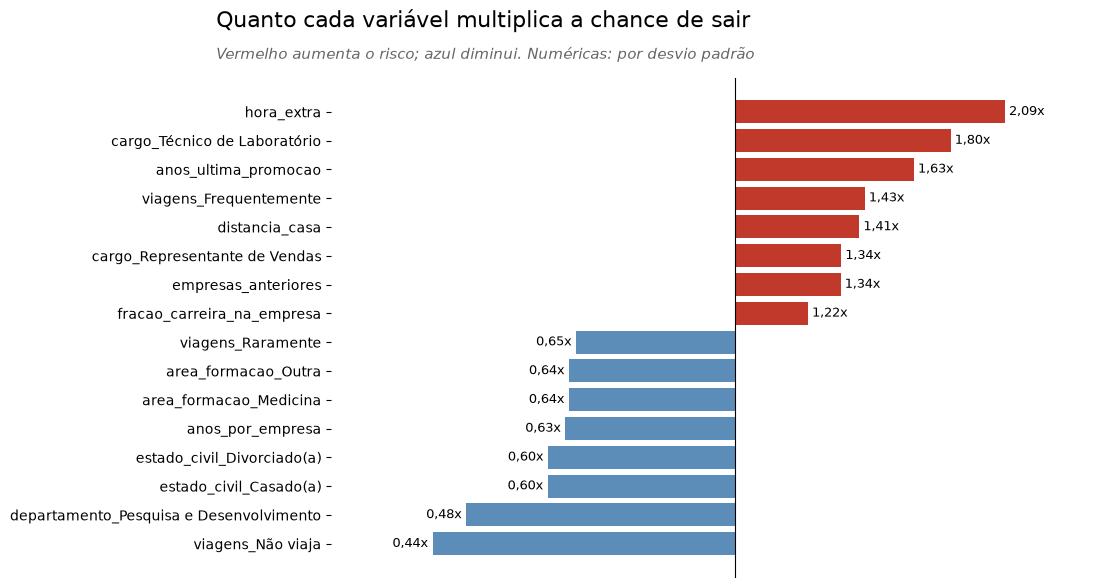

,multiplica a chance por
viagens_Não viaja,0.440
departamento_Pesquisa e Desenvolvimento,0.480
estado_civil_Casado(a),0.600
estado_civil_Divorciado(a),0.600
anos_por_empresa,0.630
area_formacao_Medicina,0.640
area_formacao_Outra,0.640
viagens_Raramente,0.650
fracao_carreira_na_empresa,1.220
empresas_anteriores,1.340


In [66]:
# Para a Regressão Logística: cada peso vira um "multiplicador da chance" (odds ratio) por desvio padrão ou por categoria
estimador = modelo_final.named_steps['modelo']
if hasattr(estimador, 'coef_'):
    nomes = modelo_final.named_steps['prep'].get_feature_names_out()
    multiplicador = pd.Series(np.exp(estimador.coef_[0]), index=nomes).sort_values()
    efeitos = pd.concat([multiplicador.head(8), multiplicador.tail(8)])
    # Escala log centrada em 1: multiplicar por 2 e dividir por 2 ficam com barras do mesmo tamanho
    fig, ax = plt.subplots(figsize=(10, 6.5))
    barras = ax.barh(efeitos.index, np.log2(efeitos.values), color=[COR_SAIU if v > 1 else COR_FICOU for v in efeitos.values])
    ax.bar_label(barras, labels=[f'{v:.2f}x'.replace('.', ',') for v in efeitos.values], padding=3, fontsize=9)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_xticks([])
    ax.set_xlim(np.log2(efeitos.min()) - 0.4, np.log2(efeitos.max()) + 0.4)
    sns.despine(left=True, bottom=True)
    titulo('Quanto cada variável multiplica a chance de sair', 'Vermelho aumenta o risco; azul diminui. Numéricas: por desvio padrão')
    salvar('Odds ratio regressao logistica')
    plt.show()
    display(efeitos.round(2).to_frame('multiplica a chance por'))
else:
    print(f'O modelo final ({nome_escolhido}) não tem coeficientes: a leitura fica com a importância por permutação.')

📌 **Nota**
- 🔎 A **hora extra** é, de longe, a variável mais importante: embaralhá-la derruba a PR-AUC em **0,23**. Em seguida vêm **anos desde a última promoção** (**0,07**), **satisfação média** (**0,06**), **empresas anteriores** (**0,04**) e **envolvimento** (**0,04**).
- 🔎 Na Regressão Logística, com todo o resto igual: fazer **hora extra** multiplica a chance de sair por **2,09**; ser **técnico de laboratório**, por **1,80**; cada desvio padrão a mais de **anos sem promoção**, por **1,63**; viajar **com frequência**, por **1,43**.
- 🔎 Diminuem o risco: **não viajar** (**0,44x**), estar em **Pesquisa e Desenvolvimento** (**0,48x**), ser **casado ou divorciado** (**0,60x**) e ter mais **anos por empresa** (**0,63x**).
- 💡 **Anos sem promoção** quase não diferia na EDA (H10), mas pesa **com o resto igual**: entre pessoas com o mesmo tempo de casa e idade, quem está há mais tempo sem promoção sai mais. Só o modelo, que separa os efeitos, mostra isso.
- ⚠️ São **associações**, não causas: hora extra pode ser sintoma (equipe sobrecarregada) e não o motivo em si.

#### SHAP: quanto cada variável empurrou o risco de cada pessoa

A permutação diz **quais** variáveis o modelo usa; os multiplicadores (odds ratio) dizem o efeito **médio**. O **SHAP** (baseado nos valores de Shapley, da teoria dos jogos) explica **cada pessoa**: começa no **valor base** (o risco médio) e soma a contribuição de cada variável até chegar ao risco daquele funcionário. Assim o RH pode responder "por que o modelo apontou esta pessoa?".

| Propriedade | O que garante |
|---|---|
| **Eficiência** | valor base + soma das contribuições = previsão: nenhuma parte fica sem explicação |
| **Simetria** | variáveis com o mesmo efeito recebem a mesma contribuição |
| **Aditividade** | as contribuições somam, inclusive em modelos combinados |

Para um modelo linear, o explainer certo é o **LinearExplainer**: exato e instantâneo. As contribuições ficam na escala do modelo, o **log da chance** (*log-odds*): somar +0,69 dobra a chance de sair; −0,69 divide por 2.

In [67]:
prep_final = modelo_final.named_steps['prep']
nomes_colunas = list(prep_final.get_feature_names_out())
fundo = pd.DataFrame(prep_final.transform(X_treino_val[FEATURES]), columns=nomes_colunas)
X_shap = pd.DataFrame(prep_final.transform(X_teste[FEATURES]), columns=nomes_colunas, index=X_teste.index)
explainer = shap.LinearExplainer(modelo_final.named_steps['modelo'], shap.maskers.Independent(fundo, max_samples=len(fundo)))
valores_shap = explainer.shap_values(X_shap)
valor_base = float(np.ravel(explainer.expected_value)[0])
print(f'Matriz SHAP: {valores_shap.shape[0]} funcionários x {valores_shap.shape[1]} colunas')
print(f'Valor base: {valor_base:.3f} em log-odds = {1 / (1 + np.exp(-valor_base)):.1%} de risco para um funcionário "médio"')

# Eficiência: valor base + soma das contribuições = log-odds do modelo (diferença ~0, só arredondamento)
log_odds = modelo_final.named_steps['modelo'].decision_function(X_shap)
print(f'Maior diferença entre (valor base + soma dos SHAP) e o log-odds do modelo: {np.abs(valor_base + valores_shap.sum(axis=1) - log_odds).max():.2e}')

# Para os gráficos, as colunas numéricas voltam à escala original (anos, dólares...) em vez da padronizada
X_exibir = X_shap.copy()
numericas_shap = [coluna for coluna in nomes_colunas if coluna in X_teste.columns]
X_exibir[numericas_shap] = X_teste[numericas_shap].values

# Importância global por variável original (as categorias somam as suas colunas 0/1) x importância por permutação
variavel_original = lambda coluna: next((cat for cat in CATEGORICAS if coluna.startswith(cat + '_')), coluna)
shap_por_variavel = pd.DataFrame(valores_shap, columns=nomes_colunas, index=X_teste.index).T.groupby(variavel_original).sum().T
importancia_shap = shap_por_variavel.abs().mean().sort_values(ascending=False)
pd.DataFrame({'SHAP: contribuição média (log-odds)': importancia_shap, 'Permutação: queda da PR-AUC': importancia_teste}).sort_values(
    'SHAP: contribuição média (log-odds)', ascending=False).head(12).round(3)

Matriz SHAP: 294 funcionários x 48 colunas
Valor base: -2.402 em log-odds = 8.3% de risco para um funcionário "médio"
Maior diferença entre (valor base + soma dos SHAP) e o log-odds do modelo: 2.22e-15


,SHAP: contribuição média (log-odds),Permutação: queda da PR-AUC
hora_extra,0.649,0.232
anos_ultima_promocao,0.356,0.066
anos_por_empresa,0.322,0.024
cargo,0.297,-0.000
departamento,0.296,0.013
anos_gestor_atual,0.290,0.015
envolvimento,0.279,0.039
anos_cargo_atual,0.277,0.017
estado_civil,0.275,0.012
distancia_casa,0.269,0.031


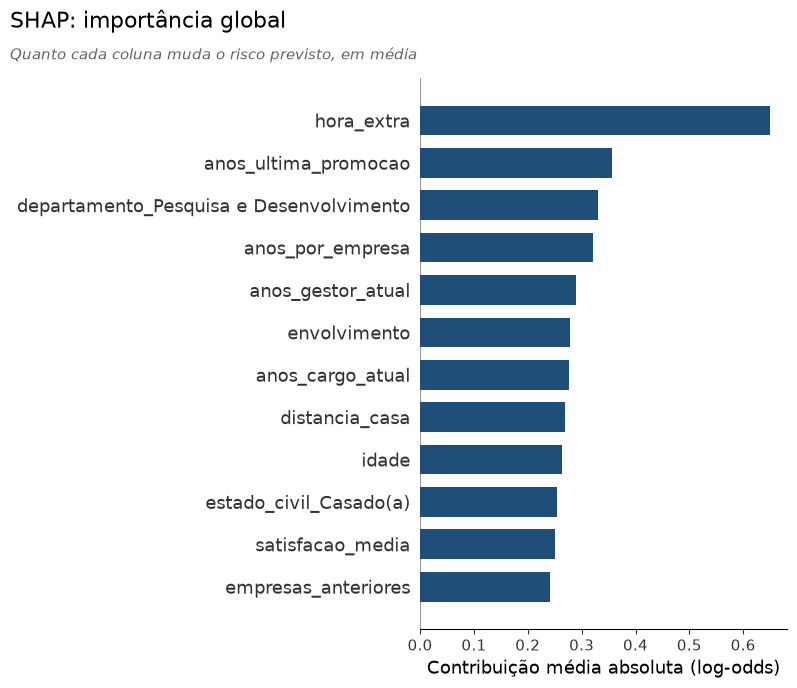

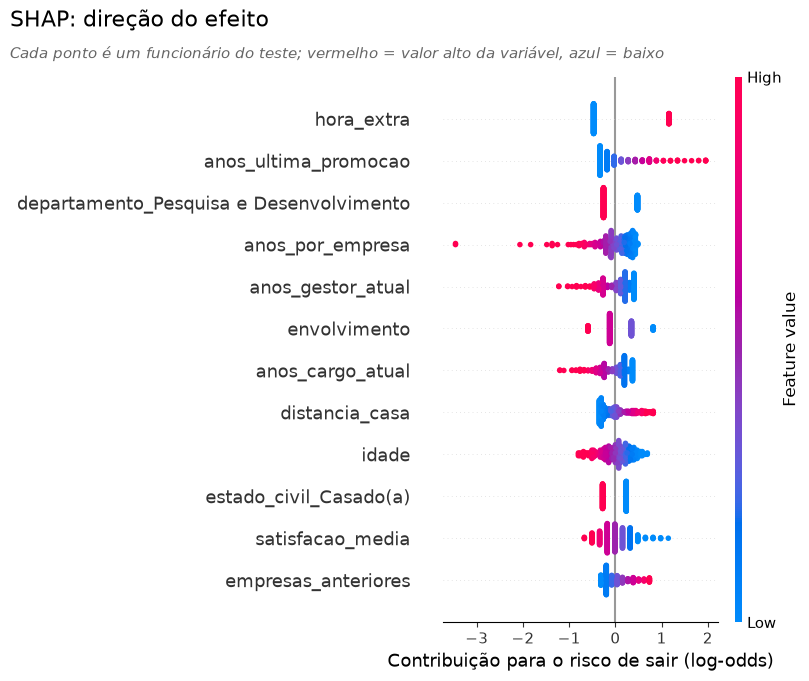

In [68]:
plt.figure()
shap.summary_plot(valores_shap, X_exibir, plot_type='bar', max_display=12, show=False, color=COR_PRINCIPAL)
plt.xlabel('Contribuição média absoluta (log-odds)')
titulo('SHAP: importância global', 'Quanto cada coluna muda o risco previsto, em média')
salvar('SHAP importancia global')
plt.show()

plt.figure()
shap.summary_plot(valores_shap, X_exibir, max_display=12, show=False)
plt.xlabel('Contribuição para o risco de sair (log-odds)')
titulo('SHAP: direção do efeito', 'Cada ponto é um funcionário do teste; vermelho = valor alto da variável, azul = baixo')
salvar('SHAP beeswarm')
plt.show()

📌 **Nota**
- 🔎 **Eficiência conferida:** valor base + soma das contribuições = log-odds do modelo, com diferença de **2 x 10⁻¹⁵** (arredondamento). O valor base, **−2,40**, equivale a **8,3%** de risco: é o risco de quem tem características "médias". Fica abaixo da taxa de saída (16%) porque o risco se concentra em poucas pessoas, de risco muito alto.
- 🔎 A **hora extra** domina: contribuição média de **0,65**, quase o dobro da 2ª variável (**anos sem promoção**, 0,36). Pelo gráfico de pontos, quem faz hora extra ganha **+1,2** e quem não faz, **−0,5**: uma distância de 1,7 em log-odds, ou seja, com o resto igual, a chance de quem faz hora extra é **~5 vezes** a de quem não faz. (O multiplicador de 2,09 do gráfico anterior é **por desvio padrão** da variável padronizada, não de "não faz" para "faz".)
- 🔎 **SHAP x permutação:** concordam nos 2 primeiros lugares, mas o **cargo** tem contribuição média de **0,30** e importância por permutação **zero**. Cargo e departamento carregam quase a mesma informação (representante de vendas está em Vendas): embaralhar só um não piora a PR-AUC, porque o outro compensa. O SHAP reparte a previsão entre os dois. A **idade** mostra o mesmo (0,26 x 0,001), por andar junto com anos de experiência e de empresa.
- 🔎 **Direção do efeito:** muitos anos **sem promoção** somam até **+2**; estar **fora de P&D** soma **+0,5** (em P&D, −0,3); mais **anos por empresa**, mais tempo com o **gestor atual**, mais **idade** e mais **satisfação** diminuem o risco; morar **longe** e ter passado por **muitas empresas** aumentam.

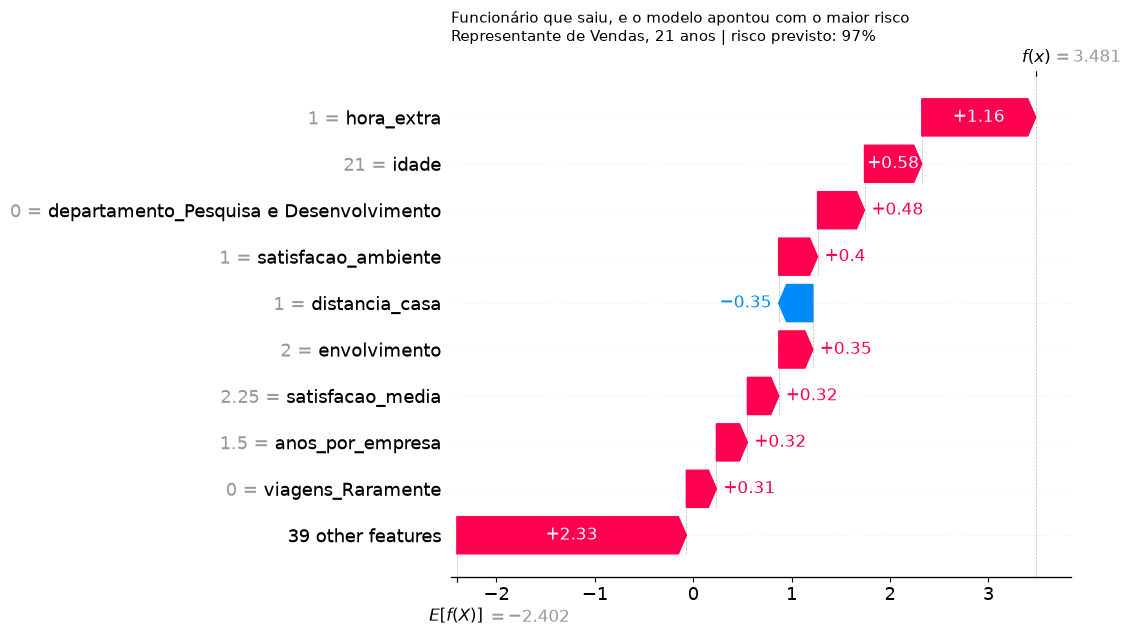

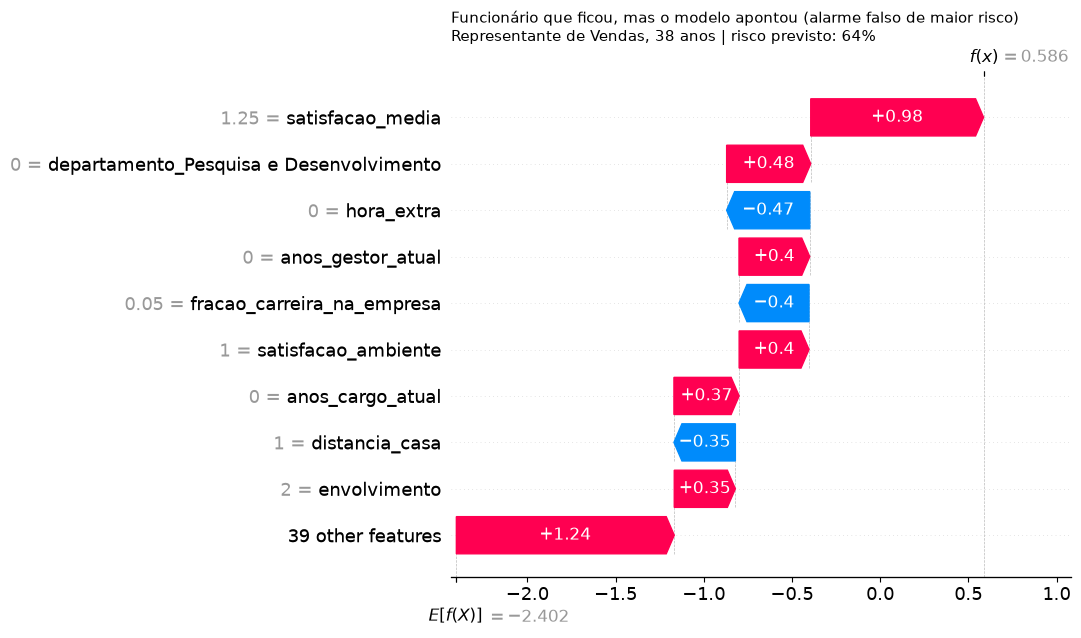

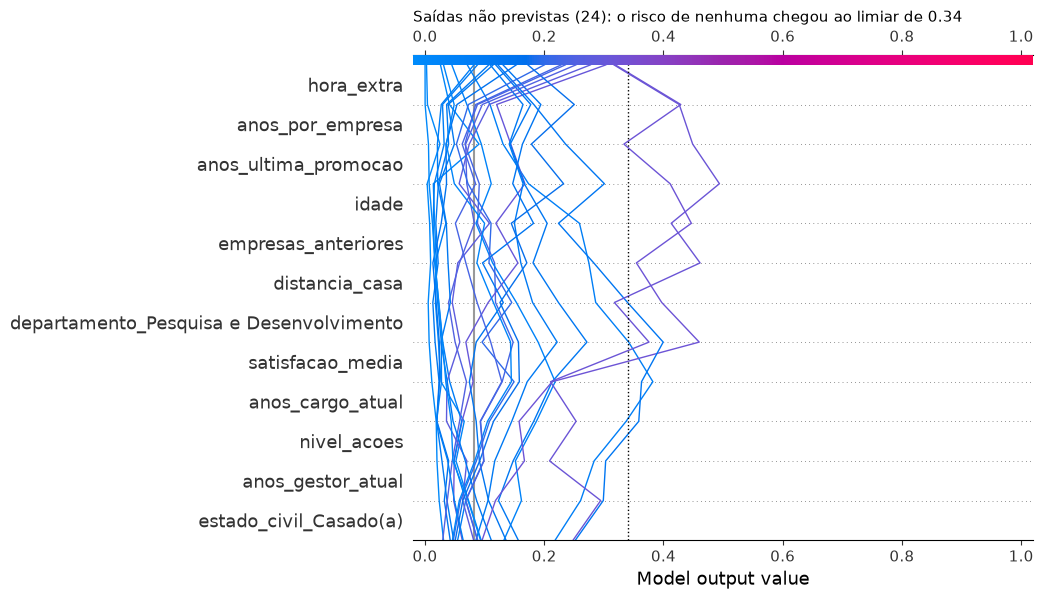

In [69]:
# Waterfall: a previsão de duas pessoas, passo a passo, do risco médio até o risco delas
y_teste_array = y_teste.to_numpy()
casos = {'saiu, e o modelo apontou com o maior risco': int(np.argmax(np.where(y_teste_array == 1, prob_teste, -1))),
         'ficou, mas o modelo apontou (alarme falso de maior risco)': int(np.argmax(np.where(y_teste_array == 0, prob_teste, -1)))}
for rotulo, posicao in casos.items():
    explicacao = shap.Explanation(values=valores_shap[posicao], base_values=valor_base, data=X_exibir.iloc[posicao].values,
                                  feature_names=nomes_colunas)
    shap.plots.waterfall(explicacao, max_display=10, show=False)
    pessoa = X_teste.iloc[posicao]
    plt.title(f"Funcionário que {rotulo}\n{pessoa['cargo']}, {pessoa['idade']} anos | risco previsto: {prob_teste[posicao]:.0%}",
              loc='left', fontsize=11)
    salvar(f"SHAP waterfall {rotulo.split(',')[0]}")
    plt.show()

# Decision plot: o caminho das saídas que o modelo NÃO previu (falsos negativos), no risco em probabilidade
falsos_negativos = (y_teste_array == 1) & (previsto_teste == 0)
shap.decision_plot(valor_base, valores_shap[falsos_negativos], X_exibir[falsos_negativos], link='logit', feature_display_range=slice(None, -13, -1),
                   show=False)
plt.axvline(limiar, color='black', ls=':', lw=1)
plt.title(f'Saídas não previstas ({falsos_negativos.sum()}): o risco de nenhuma chegou ao limiar de {limiar:.2f}', loc='left', fontsize=11)
salvar('SHAP decision plot falsos negativos')
plt.show()

📌 **Nota**
- 🔎 **Quem saiu, com o maior risco** (representante de vendas, 21 anos, **97%**): parte de −2,40 (8%) e chega a +3,48. **Hora extra** soma **+1,16**, ter **21 anos** **+0,58**, estar fora de P&D **+0,48** e a satisfação mínima com o ambiente **+0,40**. As outras 39 colunas somam **+2,33**: não há uma causa única, é o **acúmulo** de muitos sinais pequenos.
- 🔎 **Alarme falso de maior risco** (representante de vendas, 38 anos, **64%**, ficou): **não** faz hora extra (**−0,47**), mas tem **satisfação média de 1,25** (a escala vai de 1 a 4), que soma **+0,98**, está fora de P&D (+0,48) e com **0 anos** com o gestor atual (+0,40). É um perfil de risco real: uma conversa do RH com alguém tão insatisfeito não é desperdício.
- 🔎 **Saídas não previstas** (decision plot, eixo em probabilidade): as **24** partem do risco médio e as variáveis quase não as movem; a maioria termina abaixo de **20%**, e as poucas que passam do limiar no meio do caminho voltam para baixo dele. O modelo não tem sinal para essas pessoas (como as aposentadorias do item 2).
- 💡 **Para o RH:** o waterfall responde "por que esta pessoa foi apontada?" em linguagem de negócio ("hora extra, 21 anos, insatisfeita com o ambiente"), o que torna a conversa mais objetiva.

In [70]:
# Auditoria com SHAP: o gênero está fora do modelo, mas outras variáveis poderiam "carregar" o gênero (proxies)
por_genero = shap_por_variavel.groupby(X_teste['genero']).mean().T
por_genero['diferença (F - M)'] = por_genero['Feminino'] - por_genero['Masculino']
risco_total = shap_por_variavel.sum(axis=1).groupby(X_teste['genero']).mean()
print(f"Soma das contribuições (risco em relação ao funcionário médio, em log-odds): mulheres {risco_total['Feminino']:+.3f} | "
      f"homens {risco_total['Masculino']:+.3f}")
display(pd.DataFrame({'Pessoas': y_teste.groupby(X_teste['genero']).size(), 'Risco médio previsto': pd.Series(prob_teste, index=X_teste.index).groupby(X_teste['genero']).mean(),
              'Taxa real de saída': y_teste.groupby(X_teste['genero']).mean()}).style.format({'Risco médio previsto': '{:.1%}', 'Taxa real de saída': '{:.1%}'}))
por_genero.reindex(por_genero['diferença (F - M)'].abs().sort_values(ascending=False).index).head(6).round(3)

Soma das contribuições (risco em relação ao funcionário médio, em log-odds): mulheres +0.028 | homens -0.180


,Pessoas,Risco médio previsto,Taxa real de saída
genero,,,
Feminino,116,17.0%,13.8%
Masculino,178,14.7%,17.4%


genero,Feminino,Masculino,diferença (F - M)
anos_gestor_atual,0.076,0.008,0.068
anos_por_empresa,0.046,-0.012,0.058
estado_civil,0.039,-0.012,0.051
hora_extra,-0.022,-0.068,0.047
satisfacao_media,-0.018,0.024,-0.042
fracao_carreira_na_empresa,0.014,-0.022,0.035


📌 **Nota**
- ⚖️ Mesmo **sem o gênero no modelo**, o risco médio previsto no teste é de **17,0%** para as mulheres e **14,7%** para os homens, enquanto a taxa real de saída foi de **13,8%** e **17,4%**. Em log-odds, a soma das contribuições é **+0,03** para elas e **−0,18** para eles.
- 🔎 A diferença vem de variáveis que se distribuem de forma diferente entre os grupos: **anos com o gestor atual** (+0,07 a mais para as mulheres), **anos por empresa** (+0,06) e **estado civil** (+0,05). São candidatas a **proxy** (variáveis que carregam parte do gênero sem citá-lo).
- ⚠️ Com só **16** saídas de mulheres e **31** de homens no teste, cada pessoa vale ~6 pontos percentuais na taxa das mulheres: a diferença entre previsto e real está dentro da incerteza. Na auditoria do item 2, o modelo também não favoreceu um grupo de forma clara (recall de 56% nas mulheres e 45% nos homens).
- ✅ **Encaminhamento:** acompanhar em produção o **risco previsto x a taxa real por gênero**; se a diferença se mantiver com mais dados, recalibrar o modelo ou rever as variáveis-proxy.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

In [71]:
PASTA_MODELO.mkdir(exist_ok=True)
padrao = {coluna: (df[coluna].mode()[0] if coluna in CATEGORICAS else int(df[coluna].median())) for coluna in CATEGORICAS + NUMERICAS}
joblib.dump({'modelo': modelo_final, 'limiar': float(limiar), 'features': FEATURES, 'padrao': padrao,
             'taxa_base': float(y.mean()), 'proporcao_custo': PROPORCAO_CUSTO}, PASTA_MODELO / 'modelo_rotatividade.pkl')
pd.DataFrame({'real': y_teste.values, 'probabilidade': prob_teste}).to_csv(PASTA_REPORTS / 'previsoes_teste.csv', index=False)

ficha = salvar_ficha_modelo(
    PASTA_MODELO / 'modelo_rotatividade.json',
    modelo=f'{nome_escolhido}, sem balanceamento (Pipeline: one-hot + padronização + modelo)',
    arquivo='modelo_rotatividade.pkl',
    treinado_com=f'{len(X_treino_val):,} funcionários (treino + validação), {int(y_treino_val.sum())} saídas'.replace(',', '.'),
    colunas_de_entrada=FEATURES, alvo='saiu (1 = saiu da empresa, 0 = ficou)',
    limiar_recomendado=round(float(limiar), 3),
    criterio_do_limiar=f'custo mínimo na validação: saída não prevista = US$ {CUSTO_REPOSICAO:,.0f}; abordagem = 1/{PROPORCAO_CUSTO} disso',
    metricas_teste={k: round(float(metricas_teste[k]), 4) for k in ['Acurácia', 'Precisão', 'Recall (Sensibilidade)', 'F1-Score', 'PR-AUC', 'AUC-ROC']},
    intervalo_95_teste={metrica: [round(float(intervalos.loc[metrica, 'IC 2,5%']), 3), round(float(intervalos.loc[metrica, 'IC 97,5%']), 3)]
                        for metrica in intervalos.index},
    resultado_teste_dolares={k: round(float(v), 2) for k, v in custo_teste.items()},
    hiperparametros=({k.replace('modelo__', ''): (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else str(v))
                      for k, v in melhores_params.items()} if usar_ajustado else f'padrão do {melhor_modelo}'),
    metodo_de_ajuste=(f'{metodo_escolhido} (maior PR-AUC na validação cruzada de 5 dobras do treino)' if usar_ajustado else 'nenhum'),
    avisos=['Base fictícia (IBM): as conclusões valem para esta base, não para uma empresa real.',
            'O modelo aponta associação, não causa: hora extra alta pode ser sintoma, não motivo.',
            f'O limiar depende da premissa de custo (abordagem = 1/{PROPORCAO_CUSTO} da reposição).',
            'Não use o modelo para decisões punitivas: ele serve para priorizar conversas de retenção.',
            'O gênero foi retirado do modelo de propósito (atributo sensível); não o reintroduza.'],
)
print('Modelo salvo em Model/modelo_rotatividade.pkl e ficha em Model/modelo_rotatividade.json')
ficha['metricas_teste']

Modelo salvo em Model/modelo_rotatividade.pkl e ficha em Model/modelo_rotatividade.json


{'Acurácia': 0.8673,
 'Precisão': 0.6053,
 'Recall (Sensibilidade)': 0.4894,
 'F1-Score': 0.5412,
 'PR-AUC': 0.5868,
 'AUC-ROC': 0.8059}

📌 **Nota**
- 🔎 `Model/modelo_rotatividade.pkl` guarda o **pipeline completo** (one-hot + padronização + Regressão Logística), o **limiar** de 0,34, as colunas e o **valor típico** de cada coluna (usado pelo app nos campos não informados).
- 🔎 `Model/modelo_rotatividade.json` é a **ficha do modelo**: métricas no teste com **intervalo de 95%**, resultado em dólares, hiperparâmetros, premissa de custo e **avisos de uso** (base fictícia, associação não é causa, gênero retirado de propósito, não usar para punir).
- ⚠️ A versão original salvou o encoder e o scaler ajustados **no teste**: aplicados a um funcionário novo, gerariam uma escala diferente da usada no treino.

## 2 - Aplicando uma simulação

In [72]:
carregado = joblib.load(PASTA_MODELO / 'modelo_rotatividade.pkl')
perfis = {
    'Jovem, solteiro, nível 1, faz hora extra': dict(idade=24, estado_civil='Solteiro(a)', nivel_cargo=1, hora_extra=1, salario_mensal=2300,
                                                     anos_empresa=1, anos_experiencia=2, nivel_acoes=0, cargo='Representante de Vendas',
                                                     departamento='Vendas', viagens='Frequentemente'),
    'Mesmo perfil, sem hora extra': dict(idade=24, estado_civil='Solteiro(a)', nivel_cargo=1, hora_extra=0, salario_mensal=2300,
                                         anos_empresa=1, anos_experiencia=2, nivel_acoes=0, cargo='Representante de Vendas',
                                         departamento='Vendas', viagens='Frequentemente'),
    'Funcionário típico da empresa': {},
    'Gerente casado, 15 anos de casa': dict(idade=45, estado_civil='Casado(a)', nivel_cargo=4, hora_extra=0, salario_mensal=15000,
                                            anos_empresa=15, anos_experiencia=22, nivel_acoes=1, cargo='Gerente',
                                            departamento='Pesquisa e Desenvolvimento', anos_cargo_atual=7, anos_gestor_atual=7),
}
linhas = {}
for nome, mudancas in perfis.items():
    funcionario = {**carregado['padrao'], **mudancas}
    probabilidade = carregado['modelo'].predict_proba(funcionario_para_modelo(funcionario)[carregado['features']])[0, 1]
    linhas[nome] = {'probabilidade de sair': f'{probabilidade:.0%}', 'vezes a taxa média': f"{probabilidade / carregado['taxa_base']:.1f}x",
                    'recomendação': '🔴 Conversar' if probabilidade >= carregado['limiar'] else '🟢 Acompanhar'}
pd.DataFrame(linhas).T

,probabilidade de sair,vezes a taxa média,recomendação
"Jovem, solteiro, nível 1, faz hora extra",77%,4.8x,🔴 Conversar
"Mesmo perfil, sem hora extra",40%,2.5x,🔴 Conversar
Funcionário típico da empresa,1%,0.1x,🟢 Acompanhar
"Gerente casado, 15 anos de casa",0%,0.0x,🟢 Acompanhar


📌 **Nota**
- 🔎 Um funcionário **jovem, solteiro, de nível 1, representante de vendas, com hora extra** tem **77%** de chance de sair (**4,8 vezes** a média): o RH deve conversar.
- 🔎 O **mesmo perfil sem hora extra** cai para **40%**, ainda acima do limiar. A hora extra, sozinha, quase dobra o risco.
- 🔎 O **funcionário típico** da empresa tem **1%**, e um **gerente casado com 15 anos de casa**, praticamente **0%**.

#### Quantas saídas o RH encontra conversando com N pessoas?

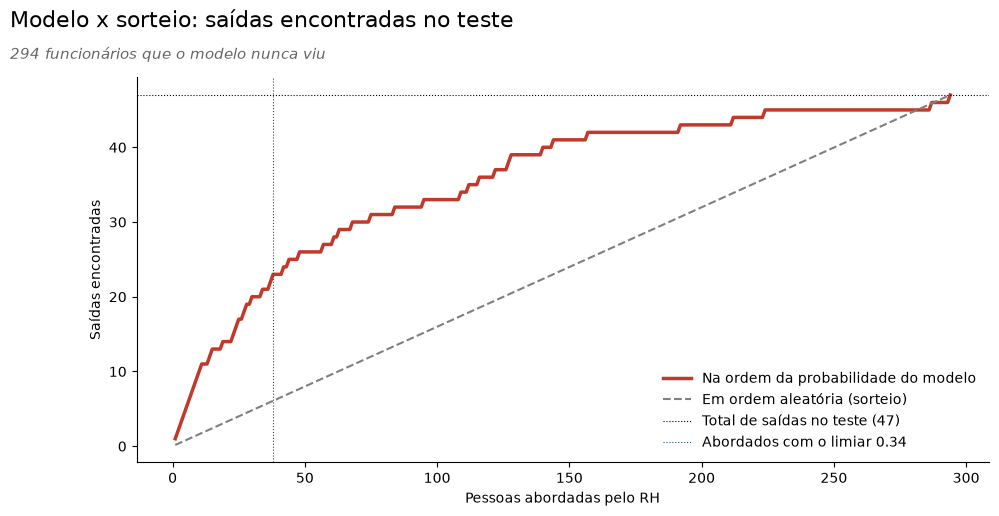

Abordando 30 pessoas (10% do teste): modelo encontra 20 saídas | sorteio, 4.8
Abordando 60 pessoas (20% do teste): modelo encontra 27 saídas | sorteio, 9.6
Abordando 90 pessoas (31% do teste): modelo encontra 32 saídas | sorteio, 14.4


In [73]:
ganho = ganho_vs_sorteio(y_teste, prob_teste)
plt.figure(figsize=(11, 5))
plt.plot(ganho['Abordados'], ganho['Modelo'], color=COR_SAIU, lw=2.5, label='Na ordem da probabilidade do modelo')
plt.plot(ganho['Abordados'], ganho['Sorteio'], color='grey', ls='--', label='Em ordem aleatória (sorteio)')
plt.axhline(y_teste.sum(), color='black', lw=0.8, ls=':', label=f'Total de saídas no teste ({y_teste.sum()})')
plt.axvline(int(previsto_teste.sum()), color=COR_PRINCIPAL, lw=0.8, ls=':', label=f'Abordados com o limiar {limiar:.2f}')
plt.xlabel('Pessoas abordadas pelo RH')
plt.ylabel('Saídas encontradas')
plt.legend(frameon=False)
sns.despine()
titulo('Modelo x sorteio: saídas encontradas no teste', f'{len(y_teste)} funcionários que o modelo nunca viu')
salvar('Ganho do modelo x sorteio')
plt.show()
for n in [30, 60, 90]:
    linha = ganho.iloc[n - 1]
    print(f'Abordando {n:>2} pessoas ({n / len(y_teste):.0%} do teste): modelo encontra {int(linha["Modelo"])} saídas | sorteio, {linha["Sorteio"]:.1f}')

📌 **Nota**
- 🔎 Conversando com as **30** pessoas de maior risco (**10%** do teste), o RH encontra **20** das 47 saídas, contra **4,8** num sorteio: **4 vezes mais**.
- 🔎 Com **60** pessoas (20%), encontra **27**; com **90** (31%), **32**. Depois disso, a curva achata: as saídas restantes (como as aposentadorias) são difíceis de prever.
- 💡 **Para o RH:** se a equipe só consegue fazer algumas dezenas de conversas, a ordem do modelo concentra o esforço onde ele rende mais.

## 3 - Monitoramento em produção

A validação não termina quando o modelo vai para o ar: a empresa muda e o modelo envelhece. Há dois tipos de mudança:

| Tipo | O que muda | Exemplo aqui | Como detectar |
|---|---|---|---|
| **Data drift** | a distribuição das **entradas** | a empresa passa a exigir mais hora extra; os salários sobem | comparar as entradas novas com as do treino (**PSI** e teste **K-S**) |
| **Concept drift** | a **relação** entre entradas e saída | depois de um plano de carreira, hora extra deixa de levar à saída | acompanhar a PR-AUC quando as saídas reais forem conhecidas |

**PSI** (*Population Stability Index*): divide a variável em faixas pelo treino e mede o quanto a proporção de pessoas em cada faixa mudou. Abaixo de **0,10**, estável; de 0,10 a **0,25**, mudança moderada; acima de 0,25, mudança forte (retreinar). O **K-S** testa se as duas distribuições são iguais.

> 🚫 **Backtest no tempo (walk-forward): não se aplica.** A base não tem a data de cada saída (é um retrato de um único momento), então não há "passado" para treinar e "futuro" para testar. No projeto Rossmann, que tem datas, a validação é feita em janelas de tempo.

In [74]:
numericas_monitoradas = [coluna for coluna in FEATURES if coluna not in CATEGORICAS]
formato_drift = {'PSI': '{:.3f}', 'K-S': '{:.3f}', 'p-valor (K-S)': '{:.3f}'}

# 1) Linha de base: o teste (mesma época do treino) deve ser estável
drift_teste = relatorio_drift(X_treino_val, X_teste, numericas_monitoradas)
print('TREINO x TESTE:', drift_teste['Status (PSI)'].value_counts().to_dict())
display(drift_teste.head(5).style.format(formato_drift))

# 2) Simulação: um ano depois, metade de quem não fazia hora extra passa a fazer e os salários sobem 10%
rng = np.random.default_rng(SEMENTE)
X_futuro = X_teste.assign(salario_mensal=X_teste['salario_mensal'] * 1.10,
                          hora_extra=np.where(rng.random(len(X_teste)) < 0.5, 1, X_teste['hora_extra']))
drift_futuro = relatorio_drift(X_treino_val, X_futuro, numericas_monitoradas)
print('TREINO x SIMULAÇÃO (mais hora extra, salário +10%):', drift_futuro['Status (PSI)'].value_counts().to_dict())
display(drift_futuro.head(4).style.format(formato_drift))
prob_futuro = modelo_final.predict_proba(X_futuro[FEATURES])[:, 1]
print(f'Fazem hora extra: {X_teste["hora_extra"].mean():.0%} -> {X_futuro["hora_extra"].mean():.0%} | risco médio previsto: '
      f'{prob_teste.mean():.1%} -> {prob_futuro.mean():.1%} | apontados pelo limiar: {int(previsto_teste.sum())} -> {int((prob_futuro >= limiar).sum())}')

TREINO x TESTE: {'estável': 24}


,PSI,Status (PSI),K-S,p-valor (K-S),K-S indica mudança
anos_experiencia,0.059,estável,0.058,0.402,False
distancia_casa,0.051,estável,0.071,0.187,False
treinamentos_ano,0.048,estável,0.075,0.139,False
salario_mensal,0.046,estável,0.072,0.166,False
idade,0.041,estável,0.042,0.799,False


TREINO x SIMULAÇÃO (mais hora extra, salário +10%): {'estável': 23, 'drift severo: retreinar': 1}


,PSI,Status (PSI),K-S,p-valor (K-S),K-S indica mudança
hora_extra,0.496,drift severo: retreinar,0.344,0.000,True
anos_experiencia,0.059,estável,0.058,0.402,False
distancia_casa,0.051,estável,0.071,0.187,False
treinamentos_ano,0.048,estável,0.075,0.139,False


Fazem hora extra: 26% -> 63% | risco médio previsto: 15.6% -> 22.2% | apontados pelo limiar: 38 -> 71


In [75]:
# SLA: PR-AUC mínima aceitável em produção = limite inferior do intervalo de 95% do teste (item 1.1 da Fase 04)
sla_pr_auc = float(intervalos.loc['PR-AUC', 'IC 2,5%'])
lotes = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE).split(X_teste, y_teste)
monitor = [{'Lote': f'Lote {n}', 'Funcionários': len(idx), 'Saídas': int(y_teste.iloc[idx].sum()),
            'PR-AUC': average_precision_score(y_teste.iloc[idx], prob_teste[idx])} for n, (_, idx) in enumerate(lotes, 1)]
# Concept drift simulado: as saídas passam a acontecer sem relação com o perfil (rótulos embaralhados)
y_conceito_novo = np.random.default_rng(SEMENTE).permutation(y_teste_array)
monitor.append({'Lote': 'Simulação: concept drift', 'Funcionários': len(y_teste), 'Saídas': int(y_conceito_novo.sum()),
                'PR-AUC': average_precision_score(y_conceito_novo, prob_teste)})
monitor = pd.DataFrame(monitor).set_index('Lote')
monitor['Situação'] = np.where(monitor['PR-AUC'] >= sla_pr_auc, '✅ dentro do SLA', '🚨 alerta: investigar e retreinar')
print(f'SLA: PR-AUC de pelo menos {sla_pr_auc:.3f} (sorteio: {y_teste.mean():.3f})')
monitor.style.format({'PR-AUC': '{:.3f}'})

SLA: PR-AUC de pelo menos 0.470 (sorteio: 0.160)


,Funcionários,Saídas,PR-AUC,Situação
Lote,,,,
Lote 1,98,15,0.668,✅ dentro do SLA
Lote 2,98,16,0.543,✅ dentro do SLA
Lote 3,98,16,0.636,✅ dentro do SLA
Simulação: concept drift,294,47,0.183,🚨 alerta: investigar e retreinar


📌 **Nota**
- 🔎 **Linha de base:** as **24** variáveis numéricas estão estáveis entre o treino e o teste (PSI de no máximo **0,059**; o K-S não aponta mudança).
- 🔎 **Simulação (mais hora extra e salário +10%):** a parcela que faz hora extra vai de **26%** para **63%**, e o PSI marca **0,496** (mudança forte: retreinar); o K-S também detecta. O aumento de 10% no salário **não** aparece no PSI: como no projeto do aluguel, ele pega mudanças grandes, não deslocamentos pequenos.
- 🔎 **Efeito no negócio:** o risco médio previsto sobe de **15,6%** para **22,2%** e o número de pessoas apontadas quase dobra (**38 → 71**). Se essa hora extra vier de uma demanda temporária e não levar a mais saídas, a relação entre hora extra e saída muda (concept drift) e o RH faria o dobro de conversas: é hora de retreinar.
- 🔎 **SLA:** PR-AUC de pelo menos **0,470** (o limite inferior do intervalo de 95% do teste). Os 3 lotes de 98 pessoas ficam entre **0,543** e **0,668**, dentro do SLA. No **concept drift simulado** (as saídas passam a acontecer sem relação com o perfil), a PR-AUC cai para **0,183**, perto do sorteio, e o alerta dispara.
- ⚠️ Com ~16 saídas por lote, a PR-AUC oscila bastante (0,54 a 0,67 em lotes do mesmo período): na prática, avaliar em janelas maiores (por exemplo, trimestrais).
- ✅ **Proposta para produção:** PSI e K-S das entradas todo mês; PR-AUC e risco previsto x taxa real (geral e por gênero) a cada trimestre; **retreinar** se o PSI passar de 0,25 numa variável importante ou se a PR-AUC ficar abaixo de 0,47.

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

| # | Pergunta | Resposta | Onde está |
|---|---|---|---|
| 1 | O que está associado à saída? | **Hora extra** (chance 3,8x maior; 52,6% de saída no nível 1 com hora extra), **começo de carreira** (jovem, salário baixo, pouco tempo de casa), **cargo** (representante de vendas: 39,8%), estado civil/ações e satisfação baixa. Gênero e as "taxas" não importam | H1 a H13; Fase 04, item 3 |
| 2 | Dá para prever quem vai sair? | Sim, como **ordem de prioridade**: PR-AUC de **0,59** no teste (sorteio: 0,16; IC 95% de 0,47 a 0,70). Abordando as 30 pessoas de maior risco, o RH encontra **4x mais** saídas que ao acaso | Fase 03, itens 5 a 7; Fase 04 |
| 3 | Com quantas pessoas conversar? | Com quem tem probabilidade **≥ 34%**: no teste, **38** de 294 pessoas (13%), das quais **61%** sairiam. O número depende da premissa de custo (de 27 a 149 pessoas) | Fase 03, item 8 |
| 4 | Quanto a empresa economiza? | **32,8%** do custo de reposição no teste (**US$ 117.733** de US$ 359.315), na premissa de que a conversa evita a saída e custa 1/5 da reposição | Fase 04, item 1 |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA | No modelo |
|---|---|---|---|
| H1 / H8 | Hora extra (e nível 1) | ✅ Maior efeito (V 0,24; 0,36 combinada) | Confirmado: variável **mais importante** (2,09x a chance) |
| H3 / H2 / H10 | Começo de carreira | ✅ Efeitos médios (r de −0,27 a −0,31) | Parcial: pesam juntos, mas com o resto igual cada um acrescenta pouco |
| H10 | Anos sem promoção | ⚠️ Quase nulo sozinho (r −0,08) | **Novo:** com o resto igual, é a **2ª** mais importante (1,63x por desvio padrão) |
| H7 | Cargo | ✅ Representantes de vendas: 39,8% | Confirmado: técnico de laboratório (1,80x) e representante (1,34x) aumentam o risco |
| H9 | Satisfação | ⚠️ Efeitos pequenos | Confirmado: a **satisfação média** é a 3ª mais importante |
| H12 | Taxas são ruído | ✅ Correlação ~0 | Confirmado: tirá-las não muda a PR-AUC |
| H13 | Gênero | ✅ Sem diferença (V 0,01) | Retirado do modelo; o recall por gênero fica dentro da incerteza |

# 💡 INSIGHTS

| # | Insight | Para quem interessa |
|---|---|---|
| 1 | **A acurácia de 84% da v1 era o acerto de quem chuta "todo mundo fica"** (84,0%). Com 16% de saídas, a métrica tem de ser a da classe "saiu" | Qualquer analista: **comparar sempre com o chute** |
| 2 | **Júnior + hora extra é o grupo de maior risco:** 52,6% de saída no nível 1 com hora extra, contra 15,8% sem | RH: rever a **carga de trabalho** dos júniores é a ação mais direta |
| 3 | **Ficar muito tempo sem promoção pesa, com o resto igual** (1,63x), embora sozinho pareça irrelevante | RH: acompanhar o **plano de carreira** de quem está parado |
| 4 | **Representantes de vendas saem 39,8% das vezes**, mais que o dobro da média | Gestores de vendas |
| 5 | **Balancear as classes piorou o modelo:** o peso da classe distorceu as probabilidades, e o ClusterCentroids da v1 jogou fora 82% dos dados | Qualquer analista: **testar se o balanceamento ajuda** antes de usar |
| 6 | **Um modelo simples venceu:** a Regressão Logística superou Random Forest, XGBoost e LightGBM na validação cruzada (0,648 contra 0,564) | Com poucos dados, **simples e explicável** costuma ganhar |
| 7 | **Abordando 10% dos funcionários, o RH encontra 43% das saídas** (20 de 47), 4x mais que ao acaso | RH: priorizar as conversas pela lista do modelo |
| 8 | **O gênero não muda a taxa de saída, e saiu do modelo** sem perda de desempenho | Qualquer modelo de RH: **atributos sensíveis fora** |

### Os limites, ditos com todas as letras

- **Base fictícia:** os dados foram criados pela IBM para ensino. As conclusões valem para esta base; numa empresa real, o modelo precisaria ser retreinado.
- **Base pequena:** com 47 saídas no teste, as métricas têm intervalos largos (recall entre 34% e 64%).
- **Fotografia, não filme:** não há datas. Para quem saiu, os valores são os do momento da saída. O modelo aponta **associação**, não causa.
- **Aposentadorias:** saídas de veteranos não têm como ser previstas com estas variáveis.
- **Premissa de custo:** a economia supõe que a conversa evita a saída e custa 1/5 da reposição. Se a ação de retenção funcionar só às vezes, a economia real é menor.
- **Uso ético:** o modelo serve para **priorizar conversas de retenção**, nunca para decisões punitivas ou de desligamento.

# 🚀 PRÓXIMOS PASSOS

1. **Retreinar com dados reais** da empresa, com **datas** (admissão e desligamento), para separar pedidos de demissão de aposentadorias e demissões e prever **quando** a saída acontece (análise de sobrevivência).
2. **Medir o efeito da conversa de retenção** com um teste controlado (parte do grupo de risco é abordada, parte não), para trocar a premissa de custo por um número observado.
3. **Acompanhar a justiça do modelo** por gênero, idade e cargo a cada retreino, com mais dados para reduzir a incerteza.
4. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

Para que o RH use o modelo **sem abrir o notebook**, criamos um app em **Streamlit** com 3 abas:
1. **Funcionário:** informa o perfil na barra lateral (idade, salário, hora extra, cargo, satisfação...) e recebe a **probabilidade de saída**, a comparação com a taxa média e a **recomendação** (conversar ou acompanhar), pelo limiar de menor custo. Abaixo, as **3 variáveis que mais pesaram** para aquele funcionário, comparado ao funcionário típico da empresa (ex.: "hora extra: sim → multiplica a chance de sair por 5,1"). Na Regressão Logística, essa divisão é exata: a soma dos efeitos de todas as variáveis dá a diferença entre as duas previsões. Serve para o RH saber **o que conversar**.
2. **Lista de prioridade do RH:** escolhe quantas pessoas o RH consegue abordar e vê **quantas saídas** o modelo encontraria no teste, comparado a escolher ao acaso.
3. **Sobre o modelo:** métricas no teste, limiar e avisos da ficha do modelo.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [76]:
%%writefile ../app.py
"""App Streamlit: risco de saída de um funcionário e lista de prioridade para o RH."""
import json
import sys
from pathlib import Path

import joblib
import pandas as pd
import plotly.graph_objects as go
import streamlit as st

RAIZ = Path(__file__).resolve().parent
sys.path.append(str(RAIZ))

from src.avaliacao import explicar_previsao  # noqa: E402
from src.config import CUSTO_REPOSICAO, NOMES_LEGIVEIS, VALORES  # noqa: E402
from src.dados import funcionario_para_modelo  # noqa: E402

st.set_page_config(page_title='Rotatividade de funcionários', page_icon='👥', layout='wide')


@st.cache_resource
def carregar_modelo():
    pacote = joblib.load(RAIZ / 'Model' / 'modelo_rotatividade.pkl')
    ficha = json.loads((RAIZ / 'Model' / 'modelo_rotatividade.json').read_text(encoding='utf-8'))
    return pacote, ficha


@st.cache_data
def carregar_teste():
    return pd.read_csv(RAIZ / 'reports' / 'previsoes_teste.csv')


def dolares(valor):
    return 'US$ ' + f'{valor:,.0f}'.replace(',', '.')


def formatar(coluna, valor):
    if coluna == 'hora_extra':
        return 'sim' if valor else 'não'
    if coluna == 'salario_mensal':
        return dolares(valor)
    if isinstance(valor, str) or float(valor).is_integer():
        return str(valor if isinstance(valor, str) else int(valor))
    return f'{valor:.2f}'.replace('.', ',')


pacote, ficha = carregar_modelo()
teste = carregar_teste()
padrao = pacote['padrao']   # valor típico (mediana ou mais comum) de cada coluna, para o que não for informado
limiar = pacote['limiar']

st.title('👥 Quem está em risco de sair?')
st.caption('Modelo treinado com a base fictícia IBM HR Analytics (1.470 funcionários, 16% saíram). '
           'A probabilidade indica prioridade para uma conversa do RH, não uma certeza.')

aba_funcionario, aba_lista, aba_modelo = st.tabs(['🧑 Funcionário', '📋 Lista de prioridade do RH', 'ℹ️ Sobre o modelo'])

with aba_funcionario:
    with st.sidebar:
        st.header('Dados do funcionário')
        idade = st.slider('Idade', 18, 60, int(padrao['idade']))
        salario = st.number_input('Salário mensal (US$)', 1000, 20000, int(padrao['salario_mensal']), step=100)
        hora_extra = st.toggle('Faz hora extra', value=bool(padrao['hora_extra']))
        estado_civil = st.selectbox('Estado civil', list(VALORES['estado_civil'].values()),
                                    index=list(VALORES['estado_civil'].values()).index(padrao['estado_civil']))
        viagens = st.selectbox('Viagens a trabalho', list(VALORES['viagens'].values()),
                               index=list(VALORES['viagens'].values()).index(padrao['viagens']))
        departamento = st.selectbox('Departamento', list(VALORES['departamento'].values()),
                                    index=list(VALORES['departamento'].values()).index(padrao['departamento']))
        cargo = st.selectbox('Cargo', list(VALORES['cargo'].values()),
                             index=list(VALORES['cargo'].values()).index(padrao['cargo']))
        nivel_cargo = st.slider('Nível do cargo (1 a 5)', 1, 5, int(padrao['nivel_cargo']))
        nivel_acoes = st.slider('Nível de ações da empresa (0 a 3)', 0, 3, int(padrao['nivel_acoes']))
        anos_empresa = st.slider('Anos na empresa', 0, 40, int(padrao['anos_empresa']))
        anos_experiencia = st.slider('Anos de experiência (total)', 0, 40, max(int(padrao['anos_experiencia']), anos_empresa))
        satisfacao = st.slider('Satisfação com o trabalho (1 a 4)', 1, 4, int(padrao['satisfacao_trabalho']))
        ambiente = st.slider('Satisfação com o ambiente (1 a 4)', 1, 4, int(padrao['satisfacao_ambiente']))
        equilibrio = st.slider('Equilíbrio vida-trabalho (1 a 4)', 1, 4, int(padrao['equilibrio_vida']))

    funcionario = dict(padrao)
    funcionario.update(idade=idade, salario_mensal=salario, hora_extra=int(hora_extra), estado_civil=estado_civil,
                       viagens=viagens, departamento=departamento, cargo=cargo, nivel_cargo=nivel_cargo,
                       nivel_acoes=nivel_acoes, anos_empresa=anos_empresa, anos_experiencia=max(anos_experiencia, anos_empresa),
                       satisfacao_trabalho=satisfacao, satisfacao_ambiente=ambiente, equilibrio_vida=equilibrio,
                       anos_cargo_atual=min(int(padrao['anos_cargo_atual']), anos_empresa),
                       anos_gestor_atual=min(int(padrao['anos_gestor_atual']), anos_empresa),
                       anos_ultima_promocao=min(int(padrao['anos_ultima_promocao']), anos_empresa))
    entrada = funcionario_para_modelo(funcionario)[pacote['features']]
    probabilidade = float(pacote['modelo'].predict_proba(entrada)[0, 1])

    col1, col2, col3 = st.columns(3)
    col1.metric('Probabilidade de sair', f'{probabilidade:.0%}')
    col2.metric('Taxa média da empresa', f"{pacote['taxa_base']:.0%}",
                delta=f'{probabilidade / pacote["taxa_base"]:.1f}x a média', delta_color='off')
    col3.metric('Recomendação', '🔴 Conversar' if probabilidade >= limiar else '🟢 Acompanhar')
    st.caption(f'O RH é acionado a partir de {limiar:.0%} de probabilidade (limiar de menor custo na validação, '
               f'com reposição de {dolares(CUSTO_REPOSICAO)} = {pacote["proporcao_custo"]}x o custo de uma abordagem). '
               'Os campos não mostrados usam o valor típico da empresa.')

    figura = go.Figure(go.Indicator(mode='gauge+number', value=probabilidade * 100, number={'suffix': '%'},
                                    gauge={'axis': {'range': [0, 100]}, 'bar': {'color': '#C0392B'},
                                           'threshold': {'line': {'color': 'black', 'width': 3}, 'value': limiar * 100}}))
    figura.update_layout(height=260, margin=dict(t=20, b=10))
    st.plotly_chart(figura, use_container_width=True)

    st.subheader('O que mais pesou para este funcionário')
    referencia = funcionario_para_modelo(padrao)[pacote['features']]
    explicacao = explicar_previsao(pacote['modelo'], entrada, referencia)
    explicacao = explicacao[explicacao['efeito_log_chance'].abs() > 0.01]   # ignora efeitos desprezíveis
    if explicacao.empty:
        st.write('Este perfil é igual ao funcionário típico da empresa: nenhuma variável se destaca.')
    for linha in explicacao.itertuples():
        sentido = '🔺 multiplica' if linha.multiplicador > 1 else '🔻 divide'
        fator = f'{max(linha.multiplicador, 1 / linha.multiplicador):.1f}'.replace('.', ',')
        st.markdown(f'- **{NOMES_LEGIVEIS[linha.variavel]}**: {formatar(linha.variavel, entrada[linha.variavel].iloc[0])} '
                    f'(típico: {formatar(linha.variavel, referencia[linha.variavel].iloc[0])}) → {sentido} a chance de sair '
                    f'por {fator}')
    st.caption('Comparação com o funcionário típico da empresa (valor mais comum de cada campo), que tem '
               f"{pacote['modelo'].predict_proba(referencia)[0, 1]:.0%} de probabilidade de sair. "
               'Mostra o que o modelo associa ao risco, não a causa: serve para orientar a conversa do RH.')

with aba_lista:
    st.subheader('Quantas saídas o RH encontra abordando as pessoas de maior risco?')
    st.caption(f'Funcionários do teste ({len(teste)} pessoas que o modelo nunca viu, {int(teste["real"].sum())} saíram), '
               'ordenados pela probabilidade de sair.')
    vagas = st.slider('Quantas pessoas o RH consegue abordar?', 5, len(teste), 60, step=5)
    ordenado = teste.sort_values('probabilidade', ascending=False)
    encontradas = int(ordenado['real'].head(vagas).sum())
    sorteio = vagas * teste['real'].mean()
    col1, col2, col3 = st.columns(3)
    col1.metric('Saídas encontradas pelo modelo', f"{encontradas} de {int(teste['real'].sum())}")
    col2.metric('Se escolhesse ao acaso', f'{sorteio:.1f}')
    col3.metric('Ganho sobre o acaso', f'{encontradas / sorteio:.1f}x' if sorteio else '-')
    curva = pd.DataFrame({'Abordados': range(1, len(ordenado) + 1), 'Modelo': ordenado['real'].cumsum().values})
    curva['Ao acaso'] = curva['Abordados'] * teste['real'].mean()
    st.line_chart(curva.set_index('Abordados'), height=320)

with aba_modelo:
    metricas = ficha['metricas_teste']
    col1, col2, col3, col4 = st.columns(4)
    col1.metric('PR-AUC (teste)', f"{metricas['PR-AUC']:.2f}", help=f"Um sorteio teria {pacote['taxa_base']:.2f}")
    col2.metric('Recall', f"{metricas['Recall (Sensibilidade)']:.0%}", help='Das pessoas que saíram, quantas o modelo apontou')
    col3.metric('Precisão', f"{metricas['Precisão']:.0%}", help='Das pessoas apontadas, quantas saíram de fato')
    col4.metric('Limiar', f'{limiar:.0%}')
    st.markdown(f"**Modelo:** {ficha['modelo']}  \n**Treinado com:** {ficha['treinado_com']}")
    st.markdown('**Avisos:**\n' + '\n'.join(f'- {aviso}' for aviso in ficha['avisos']))

Overwriting ../app.py
